In [1]:
%pip install gerbonara shapely matplotlib pandas numpy

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached rtree-1.4.1-py3-none-win_amd64.whl.metadata (2.2 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.4-cp311-cp311-win_amd64.whl.metadata (2.8 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached wsproto-1.3.2-py3-none-any.whl.metadata (5.2 kB)
  Using cached hyperframe-6.1.0-py3-none-any.whl.metadata (4.3 kB)
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 1.1/1.1 MB 53.2 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 49.5 MB/s  0:00:00
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using c

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import sys
import gerbonara
import shapely
import numpy
import pandas
import matplotlib

print("Python:", sys.executable)
print("Gerbonara:", gerbonara.__version__)
print("모든 라이브러리 import 성공")

Python: C:\Users\fl27\anaconda3\envs\pcb_analysis\python.exe
Gerbonara: 1.5.0
모든 라이브러리 import 성공


In [5]:
from pathlib import Path
from gerbonara import GerberFile

file_path = Path("VCC7.art")

gerber = GerberFile.open(file_path)

print("객체 수:", len(gerber.objects))
print("좌표 범위:", gerber.bounding_box())

객체 수: 44114
좌표 범위: ((-242.59, -242.59), (242.59, 242.59))


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

objects = list(gerber.objects)

type_counts = Counter(
    type(obj).__name__
    for obj in objects
)

print("=== Gerber Object Summary ===")
print("Total objects:", len(objects))

for obj_type, count in type_counts.most_common():
    print(f"{obj_type:20s}: {count}")

print("\n=== First 10 Objects ===")

for obj in objects[:10]:
    print(
        "Type:", type(obj).__name__,
        "| Dark:", getattr(obj, "polarity_dark", None),
        "| Aperture:", type(getattr(obj, "aperture", None)).__name__
    )

=== Gerber Object Summary ===
Total objects: 44114
Flash               : 44019
Region              : 95

=== First 10 Objects ===
Type: Region | Dark: True | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType
Type: Region | Dark: False | Aperture: NoneType


In [7]:
polarity_counts = Counter(
    "Dark" if getattr(obj, "polarity_dark", True) else "Clear"
    for obj in objects
)

print("=== Polarity Summary ===")

for polarity, count in polarity_counts.items():
    print(f"{polarity}: {count}")

print("\n=== Object Type x Polarity ===")

records = []

for obj in objects:
    records.append({
        "object_type": type(obj).__name__,
        "polarity": (
            "Dark"
            if getattr(obj, "polarity_dark", True)
            else "Clear"
        )
    })

df_objects = pd.DataFrame(records)

display(
    pd.crosstab(
        df_objects["object_type"],
        df_objects["polarity"]
    )
)

=== Polarity Summary ===
Dark: 44020
Clear: 94

=== Object Type x Polarity ===


polarity,Clear,Dark
object_type,,
Flash,0,44019
Region,94,1


In [8]:
flashes = [
    obj for obj in objects
    if type(obj).__name__ == "Flash"
]

print("Flash count:", len(flashes))

flash_records = []

for flash in flashes:
    aperture = getattr(flash, "aperture", None)

    flash_records.append({
        "x": float(flash.x),
        "y": float(flash.y),
        "polarity": (
            "Dark" if flash.polarity_dark else "Clear"
        ),
        "aperture_type": type(aperture).__name__,
        "aperture": str(aperture)[:120]
    })

df_flash = pd.DataFrame(
    flash_records,
    columns=[
        "x", "y", "polarity",
        "aperture_type", "aperture"
    ]
)

print("Flash records:", len(df_flash))

display(df_flash.head(20))

if not df_flash.empty:
    print("\n=== Flash Aperture Types ===")
    display(df_flash["aperture_type"].value_counts())

Flash count: 44019
Flash records: 44019


,x,y,polarity,aperture_type,aperture
0,-179.1797,-26.3353,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
1,-180.7643,-26.5565,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
2,-182.3489,-26.7778,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
3,-183.9335,-26.9991,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
4,-185.5181,-27.2204,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
5,-187.1028,-27.4417,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
6,-178.0070,-28.9482,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
7,-179.5916,-29.1695,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
8,-181.1762,-29.3908,Dark,CircleAperture,<circle aperture d=0.85 [mm]>
9,-182.7609,-29.6121,Dark,CircleAperture,<circle aperture d=0.85 [mm]>



=== Flash Aperture Types ===


aperture_type
CircleAperture     44018
ObroundAperture        1
Name: count, dtype: int64

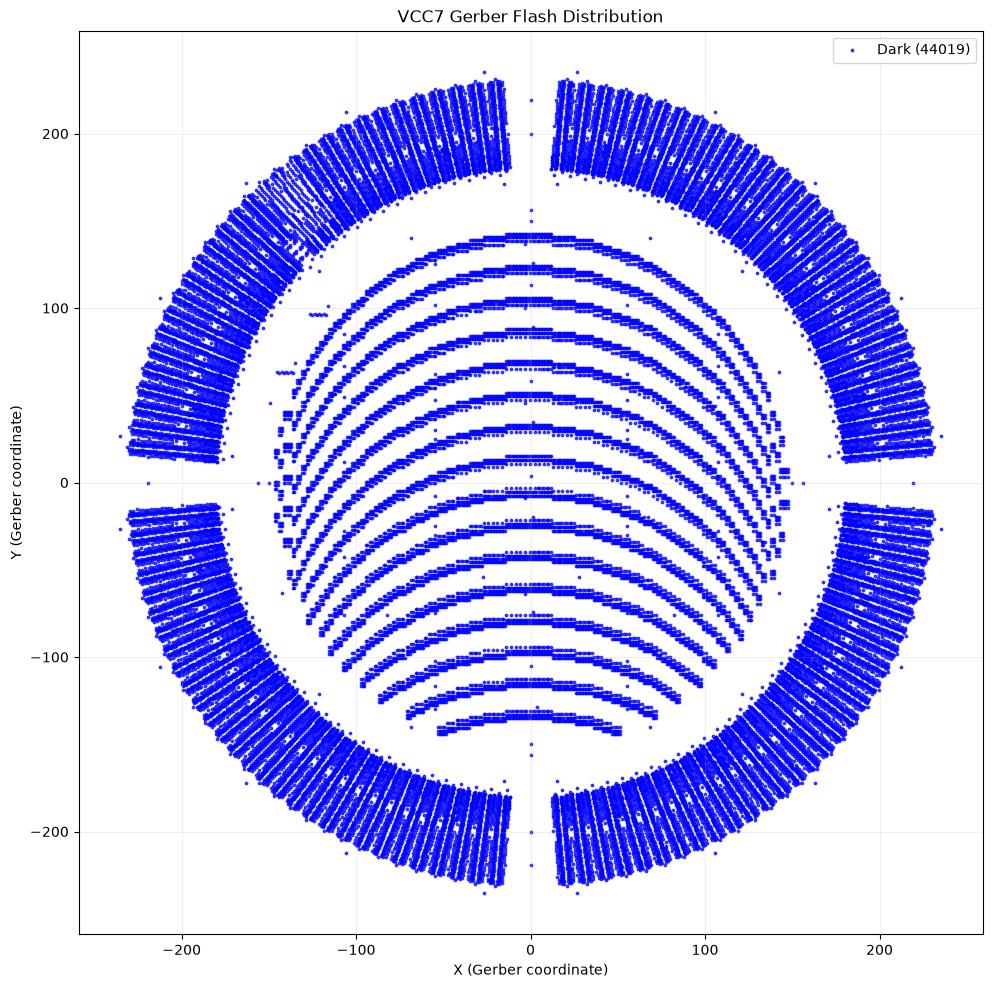

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))

colors = {
    "Dark": "blue",
    "Clear": "red"
}

for polarity, group in df_flash.groupby("polarity"):

    ax.scatter(
        group["x"],
        group["y"],
        s=3,
        c=colors[polarity],
        label=f"{polarity} ({len(group)})",
        alpha=0.7
    )

ax.set_aspect("equal")
ax.set_xlabel("X (Gerber coordinate)")
ax.set_ylabel("Y (Gerber coordinate)")
ax.set_title("VCC7 Gerber Flash Distribution")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [10]:
apertures = {}

for obj in objects:
    ap = getattr(obj, "aperture", None)

    if ap is None:
        continue

    key = id(ap)

    if key not in apertures:
        apertures[key] = {
            "type": type(ap).__name__,
            "diameter": getattr(ap, "diameter", None),
            "width": getattr(ap, "width", None),
            "height": getattr(ap, "height", None),
            "description": str(ap)[:150]
        }

df_apertures = pd.DataFrame(
    apertures.values()
)

print("Unique aperture objects:", len(df_apertures))

display(df_apertures.head(30))

print("\nAperture type counts:")
display(df_apertures["type"].value_counts())

Unique aperture objects: 13


,type,diameter,width,height,description
0,CircleAperture,0.8500,None,None,<circle aperture d=0.85 [mm]>
1,CircleAperture,0.8504,None,None,<circle aperture d=0.85 [mm]>
2,ObroundAperture,NaN,None,None,<obround aperture 4.0x5.0 [mm]>
3,CircleAperture,0.7000,None,None,<circle aperture d=0.7 [mm]>
4,CircleAperture,0.5500,None,None,<circle aperture d=0.55 [mm]>
5,CircleAperture,2.1000,None,None,<circle aperture d=2.1 [mm]>
6,CircleAperture,7.1000,None,None,<circle aperture d=7.1 [mm]>
7,CircleAperture,3.6000,None,None,<circle aperture d=3.6 [mm]>
8,CircleAperture,8.1000,None,None,<circle aperture d=8.1 [mm]>
9,CircleAperture,4.6000,None,None,<circle aperture d=4.6 [mm]>



Aperture type counts:


type
CircleAperture     12
ObroundAperture     1
Name: count, dtype: int64

In [11]:
circle_records = []

for flash in flashes:

    ap = getattr(flash, "aperture", None)

    if ap is None:
        continue

    ap_type = type(ap).__name__

    if ap_type != "CircleAperture":
        continue

    diameter = getattr(ap, "diameter", None)

    if diameter is None:
        continue

    circle_records.append({
        "x": float(flash.x),
        "y": float(flash.y),
        "diameter": float(diameter),
        "polarity": (
            "Dark" if flash.polarity_dark else "Clear"
        )
    })

df_circles = pd.DataFrame(
    circle_records,
    columns=["x", "y", "diameter", "polarity"]
)

print("Circular flash count:", len(df_circles))

display(df_circles.head(20))

if not df_circles.empty:
    print("\nDiameter statistics:")
    display(df_circles["diameter"].describe())

    print("\nMost common diameters:")
    display(df_circles["diameter"].round(6).value_counts().head(20))

Circular flash count: 44018


,x,y,diameter,polarity
0,-179.1797,-26.3353,0.85,Dark
1,-180.7643,-26.5565,0.85,Dark
2,-182.3489,-26.7778,0.85,Dark
3,-183.9335,-26.9991,0.85,Dark
4,-185.5181,-27.2204,0.85,Dark
5,-187.1028,-27.4417,0.85,Dark
6,-178.0070,-28.9482,0.85,Dark
7,-179.5916,-29.1695,0.85,Dark
8,-181.1762,-29.3908,0.85,Dark
9,-182.7609,-29.6121,0.85,Dark



Diameter statistics:


count    44018.000000
mean         0.705321
std          0.339730
min          0.550000
25%          0.550000
50%          0.700000
75%          0.700000
max          8.600000
Name: diameter, dtype: float64


Most common diameters:


diameter
0.7000    29289
0.5500    11438
0.8500     2281
1.9500      580
2.1000      232
0.8504       86
7.1000       44
1.8500       33
8.1000       22
4.6000        5
3.6000        4
8.6000        4
Name: count, dtype: int64

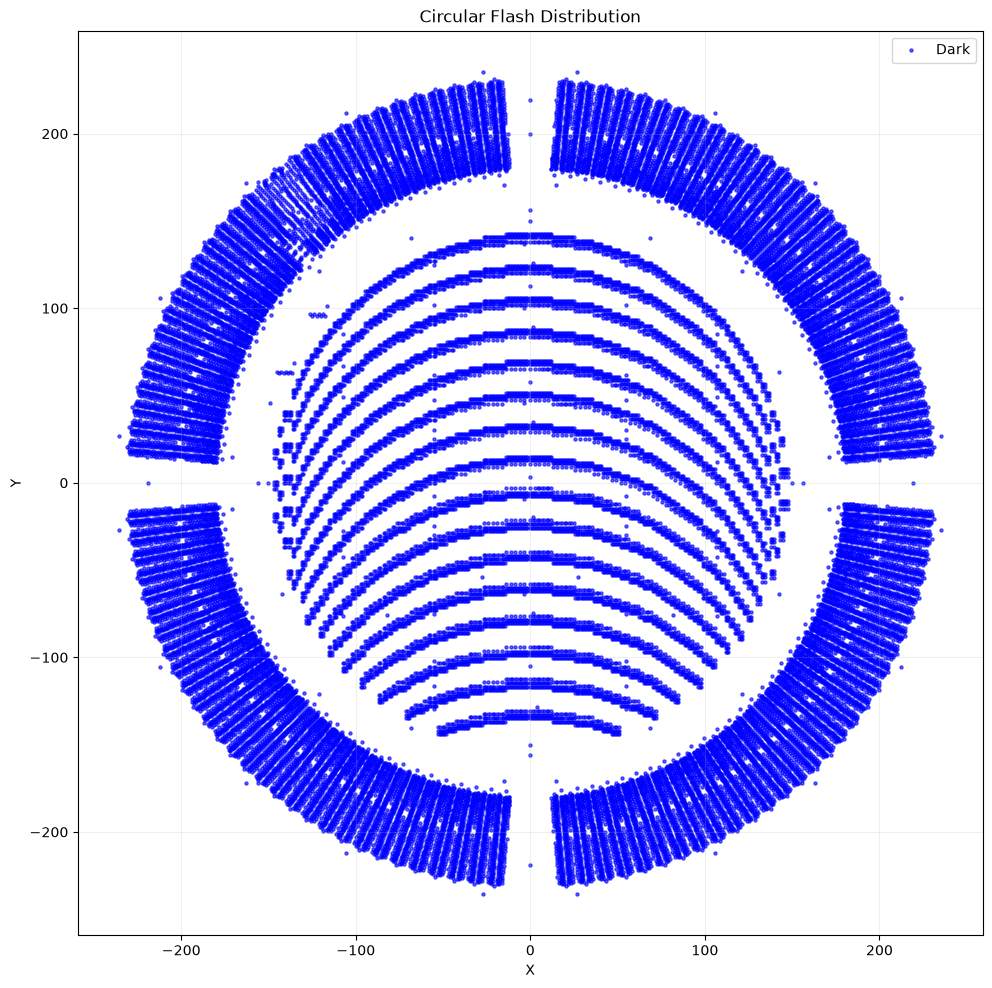

In [12]:
if df_circles.empty:
    print("원형 Flash가 없습니다. Region 또는 다른 도형을 확인해야 합니다.")

else:
    fig, ax = plt.subplots(figsize=(10, 10))

    for polarity, group in df_circles.groupby("polarity"):

        ax.scatter(
            group["x"],
            group["y"],
            s=5,
            alpha=0.6,
            label=polarity,
            color=colors[polarity]
        )

    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title("Circular Flash Distribution")
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

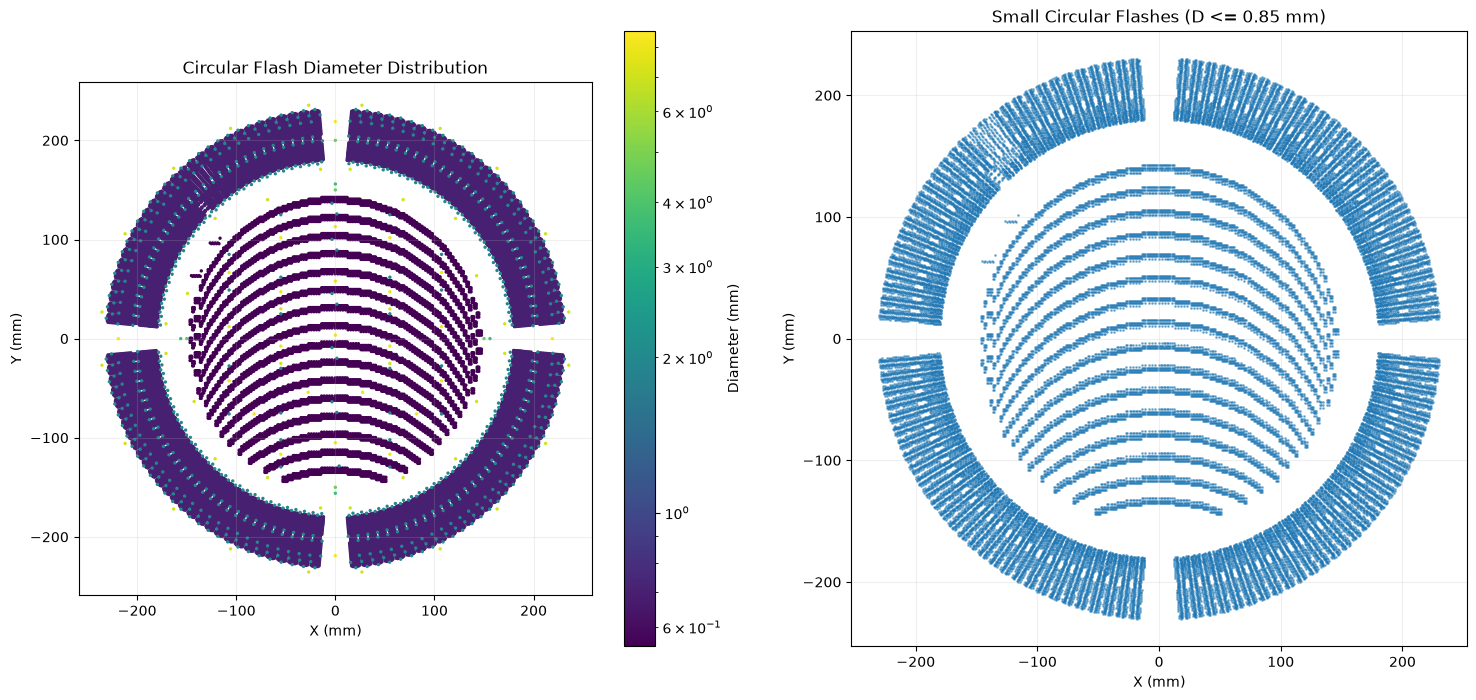

In [13]:
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# 전체 원형 Flash 분포
sc = axes[0].scatter(
    df_circles["x"],
    df_circles["y"],
    c=df_circles["diameter"],
    s=2,
    cmap="viridis",
    norm=LogNorm(
        vmin=df_circles["diameter"].min(),
        vmax=df_circles["diameter"].max()
    )
)

axes[0].set_title("Circular Flash Diameter Distribution")
axes[0].set_aspect("equal")
plt.colorbar(sc, ax=axes[0], label="Diameter (mm)")

# 작은 Flash만 표시
small = df_circles[df_circles["diameter"] <= 0.85]

axes[1].scatter(
    small["x"],
    small["y"],
    s=1,
    alpha=0.5
)

axes[1].set_title("Small Circular Flashes (D <= 0.85 mm)")
axes[1].set_aspect("equal")

for ax in axes:
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

중앙 영역 Flash 수: 1184


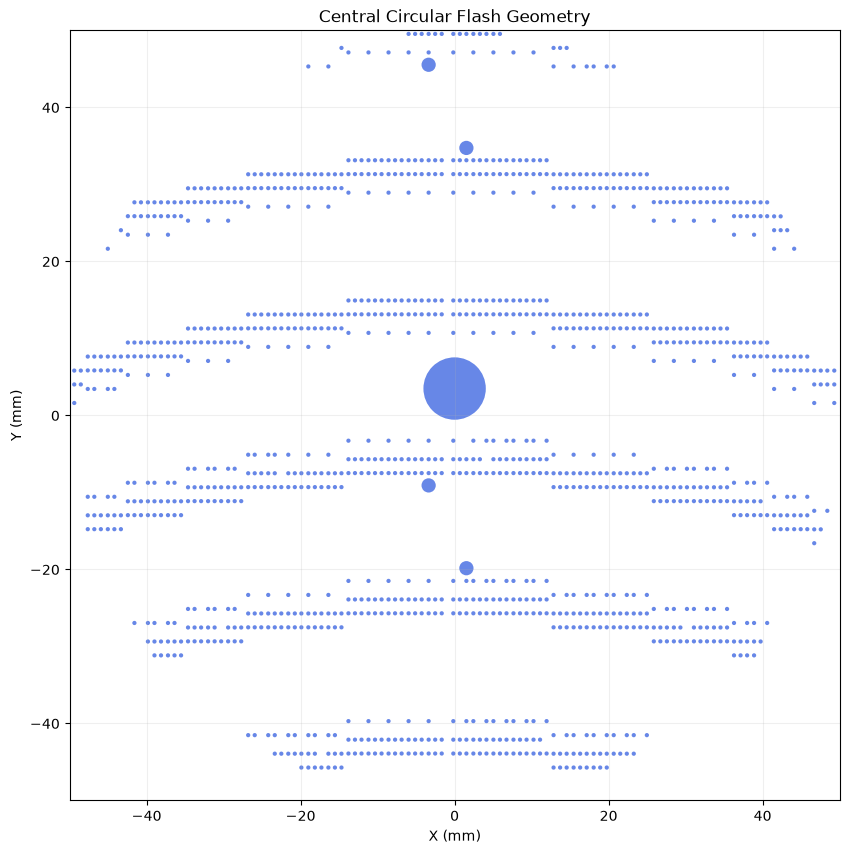

In [14]:
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle

CENTER_X = 0.0
CENTER_Y = 0.0
ROI_RADIUS_MM = 50.0

roi = df_circles[
    (df_circles["x"] - CENTER_X)**2 +
    (df_circles["y"] - CENTER_Y)**2 <= ROI_RADIUS_MM**2
].copy()

print("중앙 영역 Flash 수:", len(roi))

fig, ax = plt.subplots(figsize=(10, 10))

patches = [
    Circle(
        (row.x, row.y),
        radius=row.diameter / 2
    )
    for row in roi.itertuples()
]

if patches:
    collection = PatchCollection(
        patches,
        facecolor="royalblue",
        edgecolor="none",
        alpha=0.8
    )
    ax.add_collection(collection)

ax.set_xlim(CENTER_X - ROI_RADIUS_MM, CENTER_X + ROI_RADIUS_MM)
ax.set_ylim(CENTER_Y - ROI_RADIUS_MM, CENTER_Y + ROI_RADIUS_MM)

ax.set_aspect("equal")
ax.set_title("Central Circular Flash Geometry")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.2)

plt.show()

In [15]:
regions = [
    obj for obj in objects
    if type(obj).__name__ == "Region"
]

print("Region count:", len(regions))

for i, region in enumerate(regions[:10]):
    print(f"\nRegion {i + 1}")
    print("Polarity:", "Dark" if region.polarity_dark else "Clear")
    print("Outline count:", len(getattr(region, "outline", [])))

    try:
        print("Bounding box:", region.bounding_box())
    except Exception as e:
        print("Bounding box error:", e)

Region count: 95

Region 1
Polarity: Dark
Outline count: 5
Bounding box: ((-242.59, -242.59), (242.59, 242.59))

Region 2
Polarity: Clear
Outline count: 52
Bounding box: ((-237.3579, -44.5406), (-111.0, -17.5))

Region 3
Polarity: Clear
Outline count: 45
Bounding box: ((-238.7718, -32.9278), (-111.0, -9.0))

Region 4
Polarity: Clear
Outline count: 38
Bounding box: ((-239.3298, -20.5682), (-91.5, 3.0))

Region 5
Polarity: Clear
Outline count: 8
Bounding box: ((-239.6996, -12.3051), (-180.0, 12.3067))

Region 6
Polarity: Clear
Outline count: 114
Bounding box: ((-239.3296, 3.5), (-107.0, 63.904))

Region 7
Polarity: Clear
Outline count: 205
Bounding box: ((-232.9375, -69.8075), (-132.5, -38.75))

Region 8
Polarity: Clear
Outline count: 182
Bounding box: ((-235.4315, -56.023689862696756), (-91.5, -9.0))

Region 9
Polarity: Clear
Outline count: 156
Bounding box: ((-229.1633, -78.5329), (-114.99999882677844, -38.75))

Region 10
Polarity: Clear
Outline count: 118
Bounding box: ((-230.8904, 3.

In [16]:
from scipy.spatial import cKDTree

if len(roi) < 2:
    print("중앙 ROI에 원형 Flash가 충분하지 않습니다.")

else:
    coords = roi[["x", "y"]].to_numpy()
    diameters = roi["diameter"].to_numpy()

    tree = cKDTree(coords)

    distances, indices = tree.query(coords, k=2)

    nearest_idx = indices[:, 1]
    center_distance = distances[:, 1]

    edge_gap = (
        center_distance
        - diameters / 2
        - diameters[nearest_idx] / 2
    )

    df_gap = roi.reset_index(drop=True).copy()

    df_gap["nearest_center_distance_mm"] = center_distance
    df_gap["nearest_edge_gap_mm"] = edge_gap

    print("=== Nearest Flash Gap Statistics ===")
    display(df_gap["nearest_edge_gap_mm"].describe())

    display(
        df_gap.sort_values(
            "nearest_edge_gap_mm"
        ).head(20)
    )

=== Nearest Flash Gap Statistics ===


count    1184.000000
mean        0.459049
std         0.454777
min         0.300000
25%         0.300000
50%         0.300000
75%         0.300000
max         2.449133
Name: nearest_edge_gap_mm, dtype: float64

,x,y,diameter,polarity,nearest_center_distance_mm,nearest_edge_gap_mm
50,-41.584,25.885,0.55,Dark,0.85,0.3
1084,37.986,-11.143,0.55,Dark,0.85,0.3
1081,37.136,-11.143,0.55,Dark,0.85,0.3
1076,37.136,-12.943,0.55,Dark,0.85,0.3
22,-41.584,-12.943,0.55,Dark,0.85,0.3
38,-44.188,3.446,0.55,Dark,0.85,0.3
37,-45.038,3.446,0.55,Dark,0.85,0.3
1067,37.986,-29.353,0.55,Dark,0.85,0.3
1065,37.136,-29.353,0.55,Dark,0.85,0.3
39,-41.584,9.475,0.55,Dark,0.85,0.3


In [17]:
import pandas as pd

order_records = []

for i, obj in enumerate(objects):
    obj_type = type(obj).__name__

    if obj_type not in ("Flash", "Region"):
        continue

    order_records.append({
        "index": i,
        "type": obj_type,
        "polarity": "Dark" if obj.polarity_dark else "Clear",
        "x": getattr(obj, "x", None),
        "y": getattr(obj, "y", None)
    })

df_order = pd.DataFrame(order_records)

print("=== First 20 objects ===")
display(df_order.head(20))

print("\n=== Last 20 objects ===")
display(df_order.tail(20))

print("\n=== Region positions ===")
display(df_order[df_order["type"] == "Region"])

=== First 20 objects ===


,index,type,polarity,x,y
0,0,Region,Dark,NaN,NaN
1,1,Region,Clear,NaN,NaN
2,2,Region,Clear,NaN,NaN
3,3,Region,Clear,NaN,NaN
4,4,Region,Clear,NaN,NaN
5,5,Region,Clear,NaN,NaN
6,6,Region,Clear,NaN,NaN
7,7,Region,Clear,NaN,NaN
8,8,Region,Clear,NaN,NaN
9,9,Region,Clear,NaN,NaN



=== Last 20 objects ===


,index,type,polarity,x,y
44094,44094,Flash,Dark,209.4953,67.0093
44095,44095,Flash,Dark,211.3193,81.1074
44096,44096,Flash,Dark,215.6318,-68.8271
44097,44097,Flash,Dark,214.8099,-47.2785
44098,44098,Flash,Dark,216.8950,-36.5393
44099,44099,Flash,Dark,217.1296,35.1185
44100,44100,Flash,Dark,215.1149,45.8710
44101,44101,Flash,Dark,215.0907,70.5001
44102,44102,Flash,Dark,218.7873,-58.0205
44103,44103,Flash,Dark,221.4015,-47.0703



=== Region positions ===


,index,type,polarity,x,y
0,0,Region,Dark,NaN,NaN
1,1,Region,Clear,NaN,NaN
2,2,Region,Clear,NaN,NaN
3,3,Region,Clear,NaN,NaN
4,4,Region,Clear,NaN,NaN
...,...,...,...,...,...
90,90,Region,Clear,NaN,NaN
91,91,Region,Clear,NaN,NaN
92,92,Region,Clear,NaN,NaN
93,93,Region,Clear,NaN,NaN


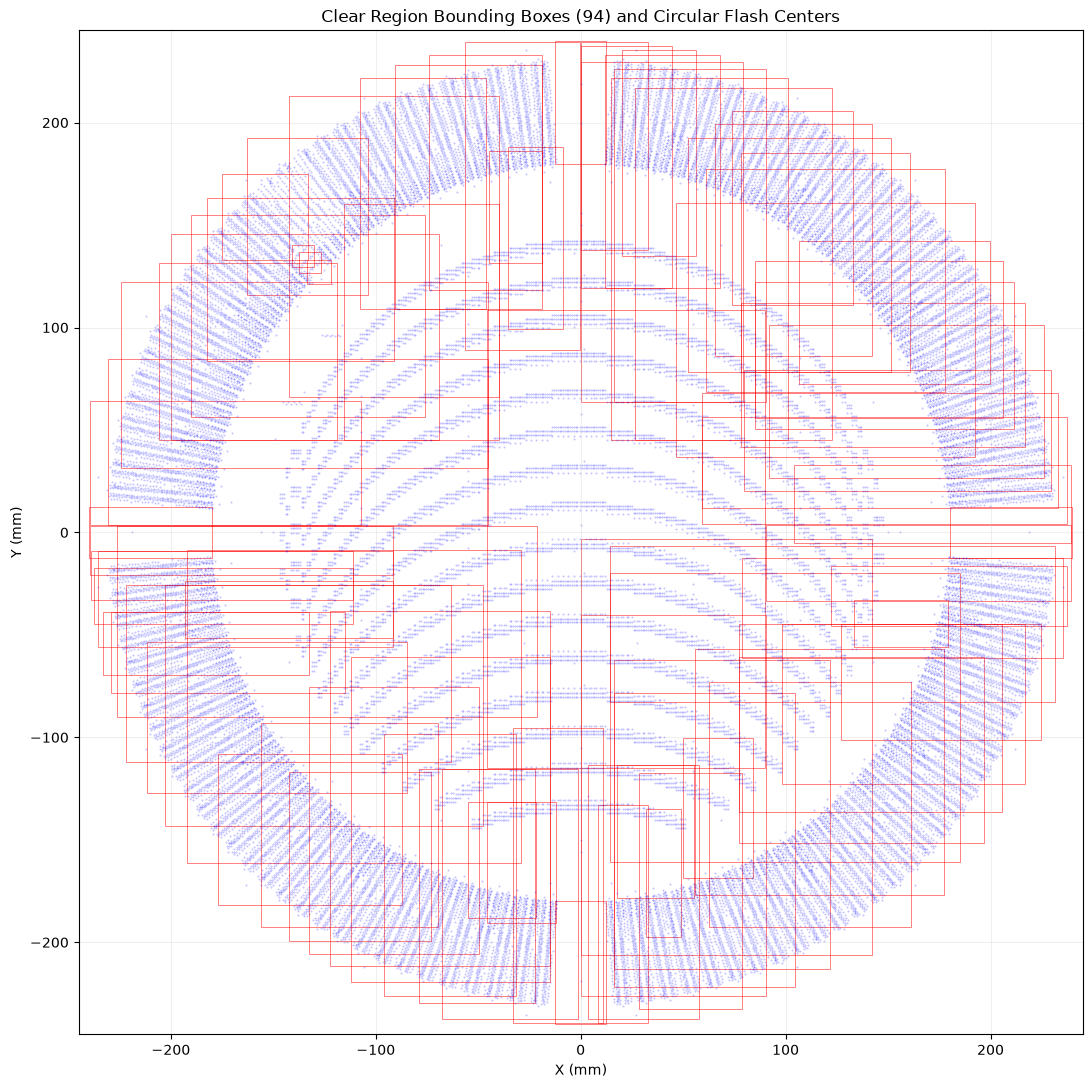

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(11, 11))

clear_count = 0

for region in regions:
    if region.polarity_dark:
        continue

    (xmin, ymin), (xmax, ymax) = region.bounding_box()

    rect = Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="red",
        linewidth=0.7,
        alpha=0.5
    )

    ax.add_patch(rect)
    clear_count += 1

ax.scatter(
    df_circles["x"],
    df_circles["y"],
    s=0.2,
    c="blue",
    alpha=0.25
)

ax.set_xlim(-245, 245)
ax.set_ylim(-245, 245)
ax.set_aspect("equal")
ax.set_title(
    f"Clear Region Bounding Boxes ({clear_count}) "
    "and Circular Flash Centers"
)
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [19]:
import numpy as np

def box_intersects_circle(bbox, cx, cy, radius):
    (xmin, ymin), (xmax, ymax) = bbox

    nearest_x = np.clip(cx, xmin, xmax)
    nearest_y = np.clip(cy, ymin, ymax)

    distance_sq = (
        (nearest_x - cx)**2 +
        (nearest_y - cy)**2
    )

    return distance_sq <= radius**2


central_regions = []

for i, region in enumerate(regions):
    if region.polarity_dark:
        continue

    bbox = region.bounding_box()

    if box_intersects_circle(
        bbox,
        CENTER_X,
        CENTER_Y,
        ROI_RADIUS_MM
    ):
        central_regions.append({
            "region_index": i,
            "region": region,
            "bbox": bbox
        })

print(
    "중앙 ROI와 Bounding Box가 겹치는 Clear Region:",
    len(central_regions)
)

for item in central_regions[:20]:
    print(
        "Region:", item["region_index"],
        "Bounding box:", item["bbox"]
    )

중앙 ROI와 Bounding Box가 겹치는 Clear Region: 10
Region: 9 Bounding box: ((-230.8904, 3.5), (-45.25, 84.6148))
Region: 10 Bounding box: ((-226.3048, -90.2845), (-21.5, 3.0))
Region: 17 Bounding box: ((-192.0334, -161.1478), (-29.0, -8.75))
Region: 31 Bounding box: ((-122.2571, -211.6821), (-14.75, -38.25))
Region: 43 Bounding box: ((-45.5, -114.75), (89.75, 108.75))
Region: 49 Bounding box: ((0.0, -226.2358), (90.6225, -40.25))
Region: 50 Bounding box: ((0.0, -206.1474), (142.2878, -3.25))
Region: 60 Bounding box: ((14.5, -160.9547), (185.2976, -20.0))
Region: 61 Bounding box: ((14.5, -82.8896), (231.5975, -6.5))
Region: 62 Bounding box: ((14.75, 45.0), (101.2805, 221.8478))


In [20]:
# 중앙에 걸쳐 있는 Region 43 조사
region = regions[43]

print("Region type:", type(region).__name__)
print("Polarity:", region.polarity_dark)
print("Bounding box:", region.bounding_box())

print("\nOutline type:", type(region.outline))
print("Outline length:", len(region.outline))

print("\nFirst 10 outline elements:")
for point in region.outline[:10]:
    print(repr(point))

Region type: Region
Polarity: False
Bounding box: ((-45.5, -114.75), (89.75, 108.75))

Outline type: <class 'list'>
Outline length: 318

First 10 outline elements:
(-45.5, 108.75)
(-32.5, 108.75)
(-32.5, 96.25)
(-32.4268, 96.0732)
(-25.1768, 88.8232)
(-25.0, 88.75)
(-0.5, 88.75)
(-0.5, 71.5)
(-0.4268, 71.3232)
(1.2215, 69.6749)


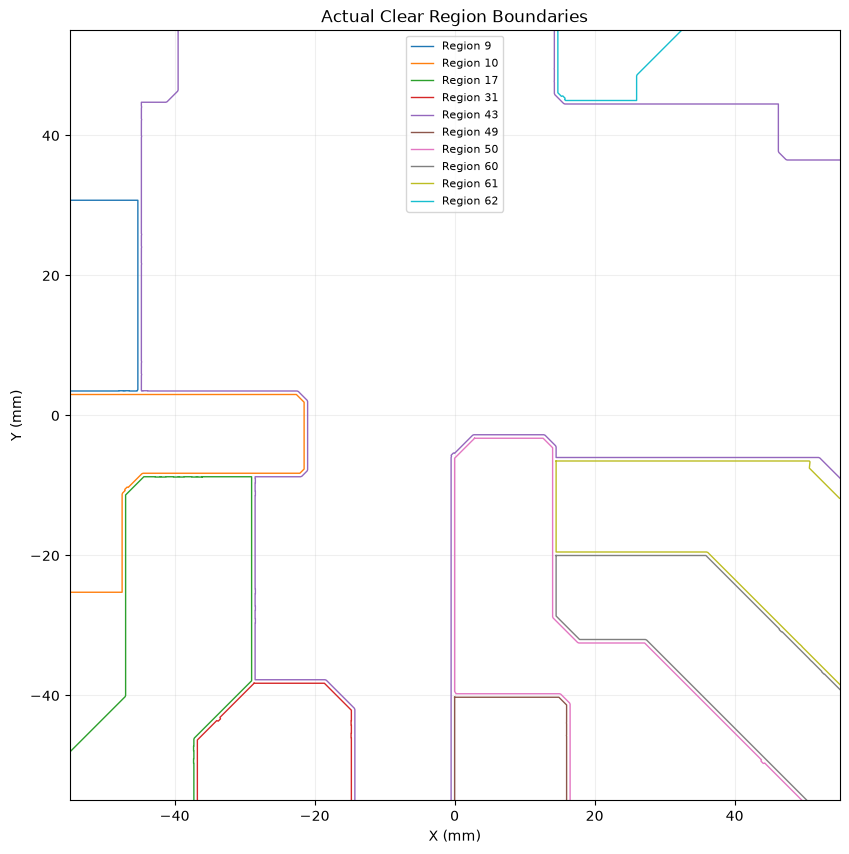

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def get_region_points(region):
    points = []

    for item in region.outline:
        if (
            isinstance(item, (tuple, list, np.ndarray))
            and len(item) >= 2
        ):
            points.append((float(item[0]), float(item[1])))
        else:
            raise TypeError(
                "Region outline이 좌표 목록이 아닙니다. "
                f"실제 항목 형식: {type(item).__name__}"
            )

    return np.asarray(points)


fig, ax = plt.subplots(figsize=(10, 10))

for item in central_regions:
    region = item["region"]

    points = get_region_points(region)

    if len(points) < 3:
        continue

    closed = np.vstack([points, points[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        linewidth=1,
        label=f"Region {item['region_index']}"
    )

ax.set_xlim(-55, 55)
ax.set_ylim(-55, 55)
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("Actual Clear Region Boundaries")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)

plt.show()

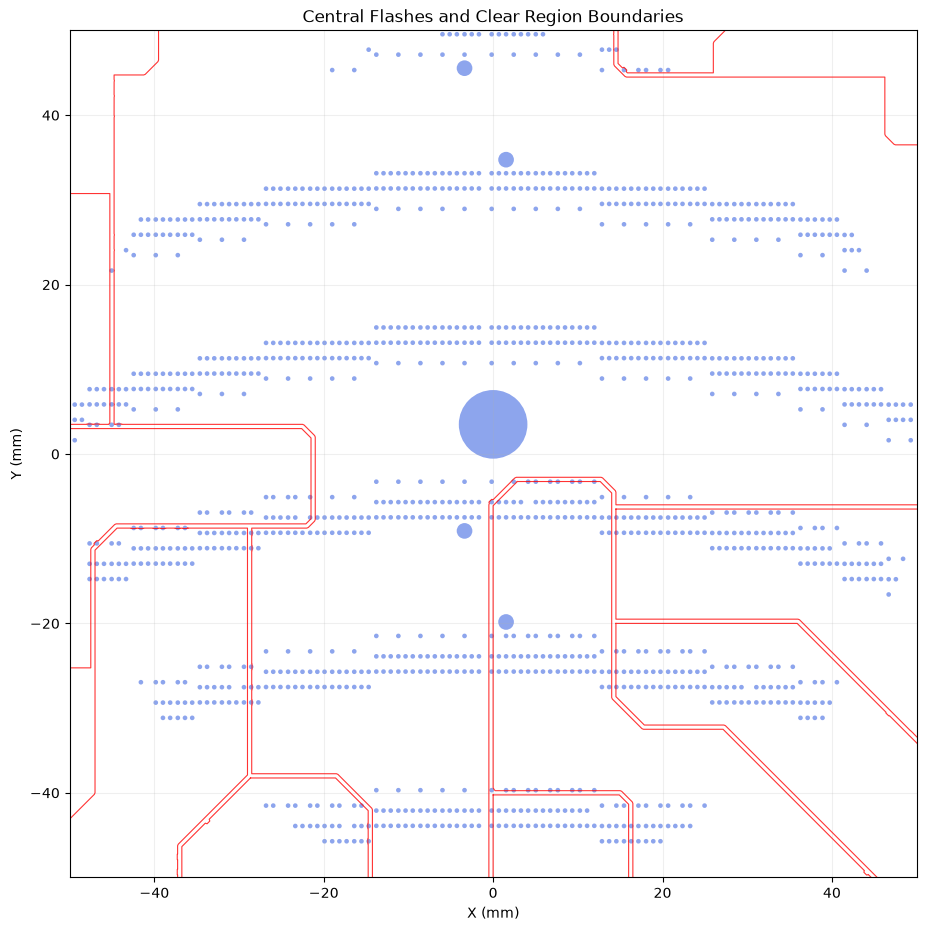

In [22]:
from matplotlib.patches import Circle
from matplotlib.collections import PatchCollection

fig, ax = plt.subplots(figsize=(11, 11))

# Clear Region 실제 경계
for item in central_regions:
    points = get_region_points(item["region"])

    if len(points) < 3:
        continue

    closed = np.vstack([points, points[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        color="red",
        linewidth=0.8,
        alpha=0.8
    )

# 중앙 원형 Flash
patches = [
    Circle(
        (row.x, row.y),
        row.diameter / 2
    )
    for row in roi.itertuples()
]

collection = PatchCollection(
    patches,
    facecolor="royalblue",
    edgecolor="none",
    alpha=0.6
)

ax.add_collection(collection)

ax.set_xlim(-50, 50)
ax.set_ylim(-50, 50)
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("Central Flashes and Clear Region Boundaries")
ax.grid(alpha=0.2)

plt.show()

In [23]:
from shapely.geometry import Polygon, Point, box
from shapely.ops import unary_union

import numpy as np
import matplotlib.pyplot as plt

# 분석 영역: 중심 기준 20 x 20 mm
X_MIN, X_MAX = -10.0, 10.0
Y_MIN, Y_MAX = -10.0, 10.0

analysis_box = box(
    X_MIN, Y_MIN,
    X_MAX, Y_MAX
)

print("ROI bounds:", analysis_box.bounds)
print("ROI area:", analysis_box.area, "mm²")

ROI bounds: (-10.0, -10.0, 10.0, 10.0)
ROI area: 400.0 mm²


In [24]:
def region_to_polygon(region):
    points = get_region_points(region)

    if len(points) < 3:
        return Polygon()

    polygon = Polygon(points)

    if not polygon.is_valid:
        polygon = polygon.buffer(0)

    return polygon


dark_regions = []
clear_regions = []

for region in regions:

    polygon = region_to_polygon(region)

    if polygon.is_empty:
        continue

    if not polygon.intersects(analysis_box):
        continue

    clipped = polygon.intersection(analysis_box)

    if region.polarity_dark:
        dark_regions.append(clipped)
    else:
        clear_regions.append(clipped)

print("Dark Regions in ROI:", len(dark_regions))
print("Clear Regions in ROI:", len(clear_regions))

Dark Regions in ROI: 1
Clear Regions in ROI: 2


In [25]:
flash_polygons = []

for row in df_circles.itertuples():

    x = row.x
    y = row.y
    radius = row.diameter / 2

    # 원이 ROI와 겹치는 경우만 처리
    if (
        x + radius < X_MIN or
        x - radius > X_MAX or
        y + radius < Y_MIN or
        y - radius > Y_MAX
    ):
        continue

    circle = Point(x, y).buffer(
        radius,
        quad_segs=32
    )

    clipped = circle.intersection(analysis_box)

    if not clipped.is_empty:
        flash_polygons.append(clipped)

print("Circular flashes intersecting ROI:", len(flash_polygons))

Circular flashes intersecting ROI: 58


In [26]:
# 1. Dark Region
if dark_regions:
    copper = unary_union(dark_regions)
else:
    copper = Polygon()

# 2. Clear Region 제거
if clear_regions:
    clear_geometry = unary_union(clear_regions)
    copper = copper.difference(clear_geometry)

# 3. Dark Flash 추가
if flash_polygons:
    flash_geometry = unary_union(flash_polygons)
    copper = copper.union(flash_geometry)

print("Copper geometry type:", copper.geom_type)
print("Copper area:", round(copper.area, 4), "mm²")
print(
    "Copper coverage:",
    round(copper.area / analysis_box.area * 100, 2),
    "%"
)

Copper geometry type: MultiPolygon
Copper area: 73.4023 mm²
Copper coverage: 18.35 %


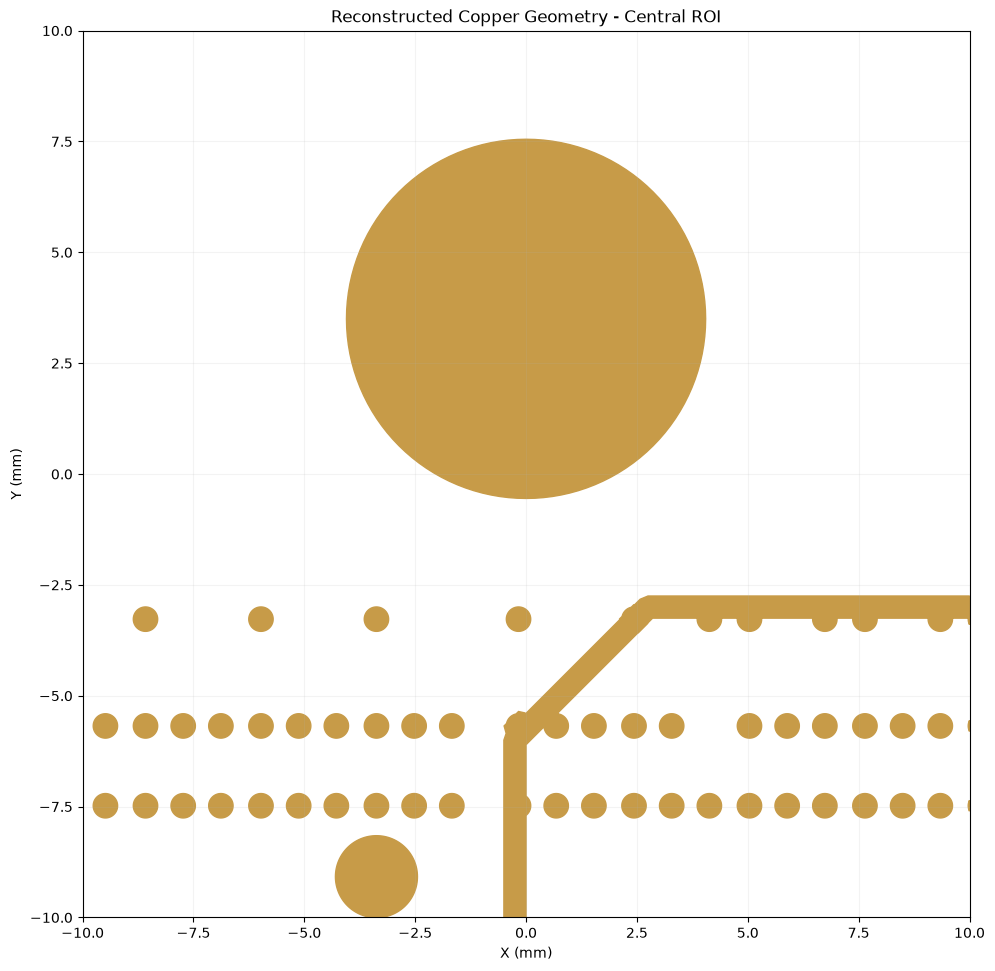

In [27]:
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

def extract_polygons(geometry):

    if geometry.is_empty:
        return []

    if geometry.geom_type == "Polygon":
        return [geometry]

    if hasattr(geometry, "geoms"):
        result = []

        for geom in geometry.geoms:
            result.extend(extract_polygons(geom))

        return result

    return []


fig, ax = plt.subplots(figsize=(10, 10))

for polygon in extract_polygons(copper):

    # 구리 외곽
    x, y = polygon.exterior.xy
    ax.fill(x, y, color="#C79B48")

    # 내부 빈 공간
    for interior in polygon.interiors:
        hx, hy = interior.xy
        ax.fill(hx, hy, color="white")

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_aspect("equal")
ax.set_title("Reconstructed Copper Geometry - Central ROI")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [28]:
components = extract_polygons(copper)

component_data = []

for i, component in enumerate(components):

    component_data.append({
        "component_id": i,
        "area_mm2": component.area,
        "perimeter_mm": component.length,
        "holes": len(component.interiors)
    })

df_components = pd.DataFrame(component_data)

print("Copper connected components:", len(components))

if not df_components.empty:
    display(
        df_components.sort_values(
            "area_mm2",
            ascending=False
        ).head(20)
    )

Copper connected components: 49


,component_id,area_mm2,perimeter_mm,holes
35,35,51.509282,25.444346,0
0,0,8.747689,35.155687,0
1,1,2.686339,5.811022,0
44,44,0.237488,1.727702,0
16,16,0.237488,1.727702,0
38,38,0.237488,1.727702,0
37,37,0.237488,1.727702,0
45,45,0.237488,1.727702,0
6,6,0.237488,1.727702,0
21,21,0.237488,1.727702,0


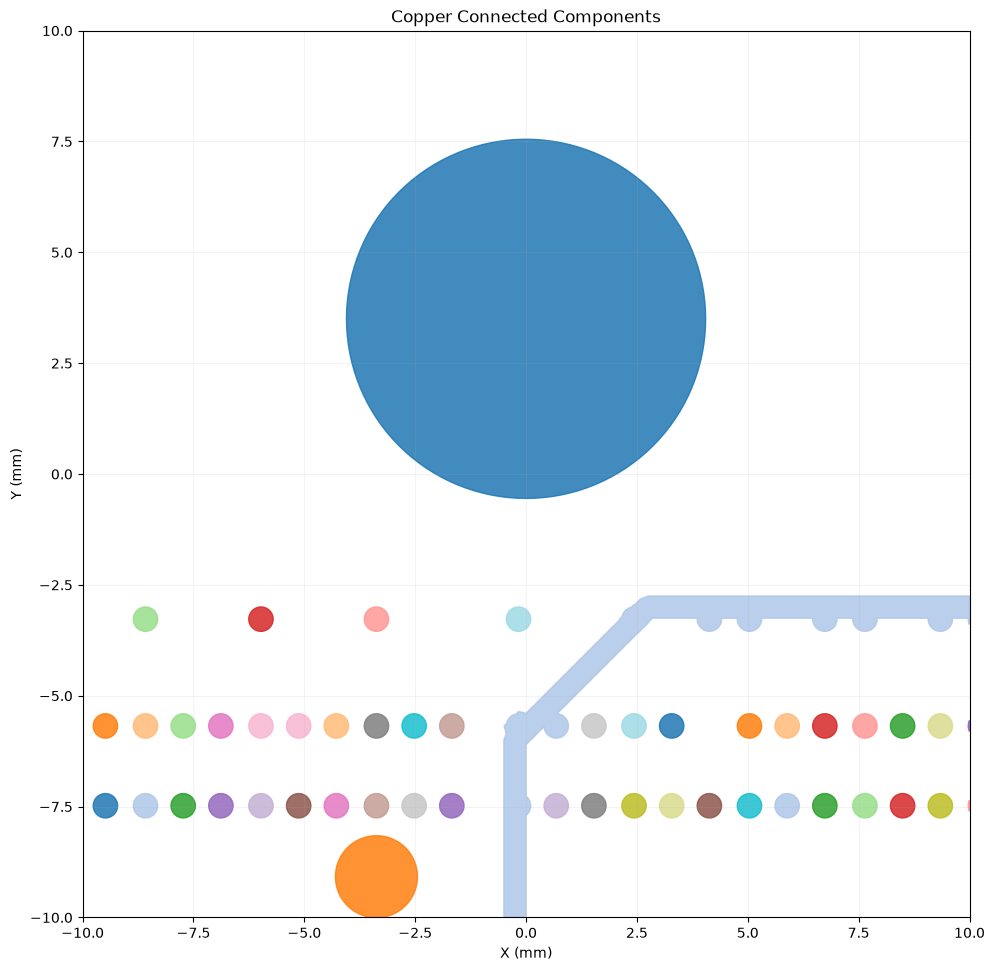

In [30]:
import matplotlib.pyplot as plt

components_sorted = sorted(
    components,
    key=lambda g: g.area,
    reverse=True
)

fig, ax = plt.subplots(figsize=(10, 10))

# Matplotlib 최신 버전 호환
cmap = plt.get_cmap("tab20", 20)

for i, polygon in enumerate(components_sorted):

    color = cmap(i % 20)

    x, y = polygon.exterior.xy

    ax.fill(
        x, y,
        color=color,
        alpha=0.85
    )

    # 구리 내부의 빈 공간 표시
    for interior in polygon.interiors:
        hx, hy = interior.xy

        ax.fill(
            hx, hy,
            color="white"
        )

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_aspect("equal")

ax.set_title("Copper Connected Components")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [31]:
from shapely.geometry import Point

records = []

for i, polygon in enumerate(components_sorted):
    centroid = polygon.centroid

    records.append({
        "rank": i + 1,
        "area_mm2": polygon.area,
        "center_x": centroid.x,
        "center_y": centroid.y,
        "bounds": polygon.bounds
    })

df_component_rank = pd.DataFrame(records)

display(df_component_rank.head(10))

,rank,area_mm2,center_x,center_y,bounds
0,1,51.509282,2.582195e-16,3.500000,"(-4.05, -0.5499999999999998, 4.05, 7.55)"
1,2,8.747689,3.399384e+00,-4.641409,"(-0.5, -10.0, 10.0, -2.75)"
2,3,2.686339,-3.374000e+00,-9.079792,"(-4.299, -10.0, -2.449, -8.155)"
3,4,0.237488,-4.278000e+00,-5.680000,"(-4.553, -5.955, -4.002999999999999, -5.404999..."
4,5,0.237488,6.738000e+00,-7.480000,"(6.463, -7.755000000000001, 7.013000000000001,..."
5,6,0.237488,7.642000e+00,-7.480000,"(7.367, -7.755000000000001, 7.917000000000001,..."
6,7,0.237488,6.738000e+00,-5.680000,"(6.463, -5.955, 7.013000000000001, -5.40499999..."
7,8,0.237488,7.642000e+00,-5.680000,"(7.367, -5.955, 7.917000000000001, -5.40499999..."
8,9,0.237488,-6.882000e+00,-7.480000,"(-7.157, -7.755000000000001, -6.60699999999999..."
9,10,0.237488,-5.978000e+00,-7.480000,"(-6.253, -7.755000000000001, -5.70299999999999..."


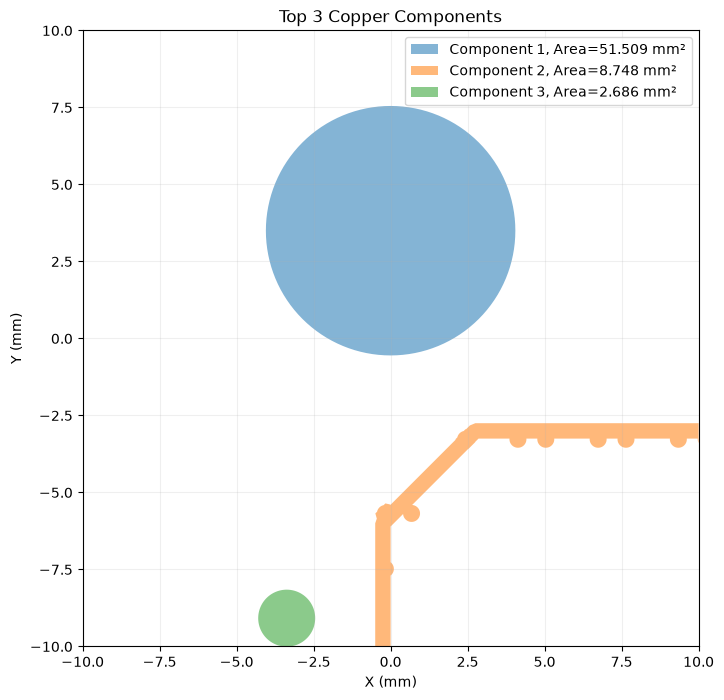

In [32]:
fig, ax = plt.subplots(figsize=(11, 8))

for i, polygon in enumerate(components_sorted[:3]):
    x, y = polygon.exterior.xy

    ax.fill(
        x, y,
        alpha=0.55,
        label=f"Component {i+1}, Area={polygon.area:.3f} mm²"
    )

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("Top 3 Copper Components")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

Target area: 8.747688850544684 mm²
Target bounds: (-0.5, -10.0, 10.0, -2.75)


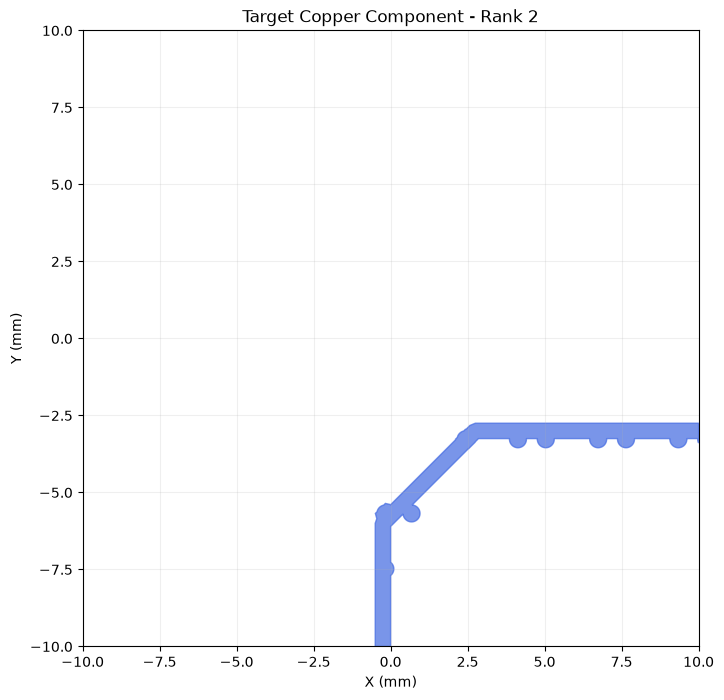

In [33]:
from shapely.geometry import Point
import matplotlib.pyplot as plt

# 면적 순위 2위 연결 성분
target_component = components_sorted[1]

print("Target area:", target_component.area, "mm²")
print("Target bounds:", target_component.bounds)

fig, ax = plt.subplots(figsize=(10, 8))

x, y = target_component.exterior.xy
ax.fill(x, y, color="royalblue", alpha=0.7)

for interior in target_component.interiors:
    hx, hy = interior.xy
    ax.fill(hx, hy, color="white")

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_aspect("equal")
ax.set_title("Target Copper Component - Rank 2")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.2)

plt.show()

In [34]:
from shapely import contains_xy
from scipy.ndimage import distance_transform_edt

GRID_MM = 0.02

xmin, ymin, xmax, ymax = target_component.bounds

x_coords = np.arange(xmin, xmax + GRID_MM / 2, GRID_MM)
y_coords = np.arange(ymin, ymax + GRID_MM / 2, GRID_MM)

XX, YY = np.meshgrid(x_coords, y_coords)

copper_mask = contains_xy(
    target_component,
    XX,
    YY
)

# ROI 바깥으로 이어지는 경계에서의 거리 왜곡을 방지하기 위해
# 격자 외곽을 비전도 영역으로 처리
padded_mask = np.pad(
    copper_mask,
    pad_width=1,
    mode="constant",
    constant_values=False
)

distance_mm = distance_transform_edt(
    padded_mask,
    sampling=GRID_MM
)[1:-1, 1:-1]

print("Grid shape:", copper_mask.shape)
print("Grid resolution:", GRID_MM, "mm")
print("Copper pixels:", copper_mask.sum())

Grid shape: (363, 526)
Grid resolution: 0.02 mm
Copper pixels: 21720


In [35]:
from skimage.morphology import skeletonize

skeleton = skeletonize(copper_mask)

local_width_mm = 2.0 * distance_mm

skeleton_widths = local_width_mm[skeleton]

print("Skeleton pixels:", skeleton.sum())

if len(skeleton_widths) > 0:
    print("Minimum estimated width:", skeleton_widths.min(), "mm")
    print("Median estimated width:", np.median(skeleton_widths), "mm")
    print("Maximum estimated width:", skeleton_widths.max(), "mm")

Skeleton pixels: 795
Minimum estimated width: 0.04 mm
Median estimated width: 0.52 mm
Maximum estimated width: 0.6835202996254025 mm


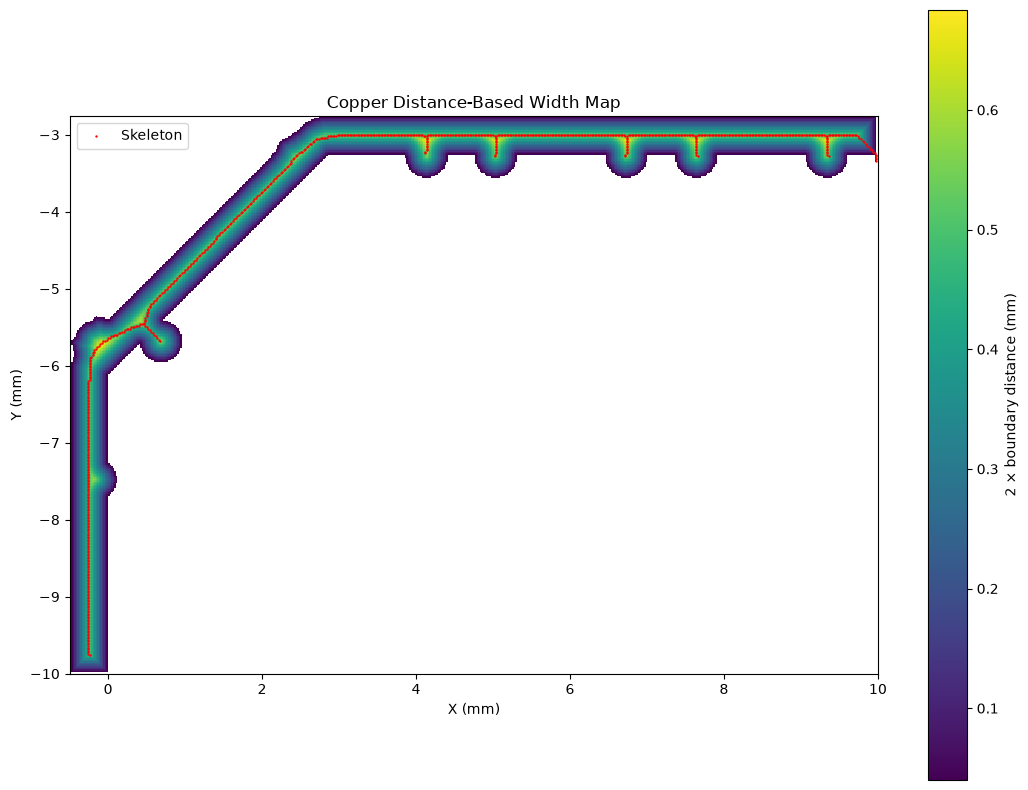

In [36]:
fig, ax = plt.subplots(figsize=(11, 8))

width_map = np.where(
    copper_mask,
    local_width_mm,
    np.nan
)

im = ax.imshow(
    width_map,
    origin="lower",
    extent=[
        x_coords[0], x_coords[-1],
        y_coords[0], y_coords[-1]
    ],
    cmap="viridis",
    interpolation="nearest"
)

sy, sx = np.where(skeleton)

ax.scatter(
    x_coords[sx],
    y_coords[sy],
    s=0.5,
    c="red",
    label="Skeleton"
)

ax.set_aspect("equal")
ax.set_title("Copper Distance-Based Width Map")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")

plt.colorbar(im, ax=ax, label="2 × boundary distance (mm)")
ax.legend()

plt.tight_layout()
plt.show()

In [37]:
EDGE_MARGIN_MM = 0.5

valid_skeleton = skeleton.copy()

valid_skeleton &= XX > X_MIN + EDGE_MARGIN_MM
valid_skeleton &= XX < X_MAX - EDGE_MARGIN_MM
valid_skeleton &= YY > Y_MIN + EDGE_MARGIN_MM
valid_skeleton &= YY < Y_MAX - EDGE_MARGIN_MM

ys, xs = np.where(valid_skeleton)

df_width = pd.DataFrame({
    "x_mm": x_coords[xs],
    "y_mm": y_coords[ys],
    "estimated_width_mm": local_width_mm[ys, xs]
})

print("Valid skeleton points:", len(df_width))

display(
    df_width.sort_values(
        "estimated_width_mm"
    ).head(20)
)

Valid skeleton points: 752


,x_mm,y_mm,estimated_width_mm
414,2.84,-3.04,0.441814
179,-0.24,-5.90,0.441814
413,2.82,-3.04,0.447214
232,0.50,-5.36,0.447214
178,-0.24,-5.92,0.447214
235,0.52,-5.30,0.447214
210,0.56,-5.56,0.452548
233,0.50,-5.34,0.456070
177,-0.24,-5.94,0.456070
219,0.34,-5.50,0.456070


In [38]:
WIDTH_THRESHOLD_MM = 0.47

df_narrow = df_width[
    df_width["estimated_width_mm"] <= WIDTH_THRESHOLD_MM
].copy()

print("Narrow skeleton points:", len(df_narrow))

display(
    df_narrow.sort_values("estimated_width_mm").head(20)
)

Narrow skeleton points: 23


,x_mm,y_mm,estimated_width_mm
179,-0.24,-5.90,0.441814
414,2.84,-3.04,0.441814
232,0.50,-5.36,0.447214
178,-0.24,-5.92,0.447214
413,2.82,-3.04,0.447214
235,0.52,-5.30,0.447214
210,0.56,-5.56,0.452548
219,0.34,-5.50,0.456070
412,2.80,-3.04,0.456070
233,0.50,-5.34,0.456070


In [39]:
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

coords = df_narrow[["x_mm", "y_mm"]].to_numpy()

CLUSTER_RADIUS_MM = 0.12

if len(coords) == 0:
    df_neck_regions = pd.DataFrame()
    print("설정한 폭 임계값 이하의 후보가 없습니다.")

else:
    tree = cKDTree(coords)
    pairs = list(tree.query_pairs(CLUSTER_RADIUS_MM))

    rows = list(range(len(coords)))
    cols = list(range(len(coords)))

    for i, j in pairs:
        rows.extend([i, j])
        cols.extend([j, i])

    graph = coo_matrix(
        (
            np.ones(len(rows)),
            (rows, cols)
        ),
        shape=(len(coords), len(coords))
    ).tocsr()

    n_clusters, labels = connected_components(
        graph,
        directed=False
    )

    df_narrow["cluster"] = labels

    results = []

    for cluster_id, group in df_narrow.groupby("cluster"):

        narrowest = group.loc[
            group["estimated_width_mm"].idxmin()
        ]

        results.append({
            "cluster": cluster_id,
            "point_count": len(group),
            "x_mm": narrowest["x_mm"],
            "y_mm": narrowest["y_mm"],
            "min_width_mm": narrowest["estimated_width_mm"]
        })

    df_neck_regions = pd.DataFrame(results).sort_values(
        "min_width_mm"
    ).reset_index(drop=True)

    print("Independent neck candidate clusters:", n_clusters)

    display(df_neck_regions)

Independent neck candidate clusters: 6


,cluster,point_count,x_mm,y_mm,min_width_mm
0,0,4,-0.24,-5.90,0.441814
1,5,5,2.84,-3.04,0.441814
2,4,5,0.50,-5.36,0.447214
3,2,5,0.56,-5.56,0.452548
4,3,3,0.34,-5.50,0.456070
5,1,1,0.08,-5.60,0.468188


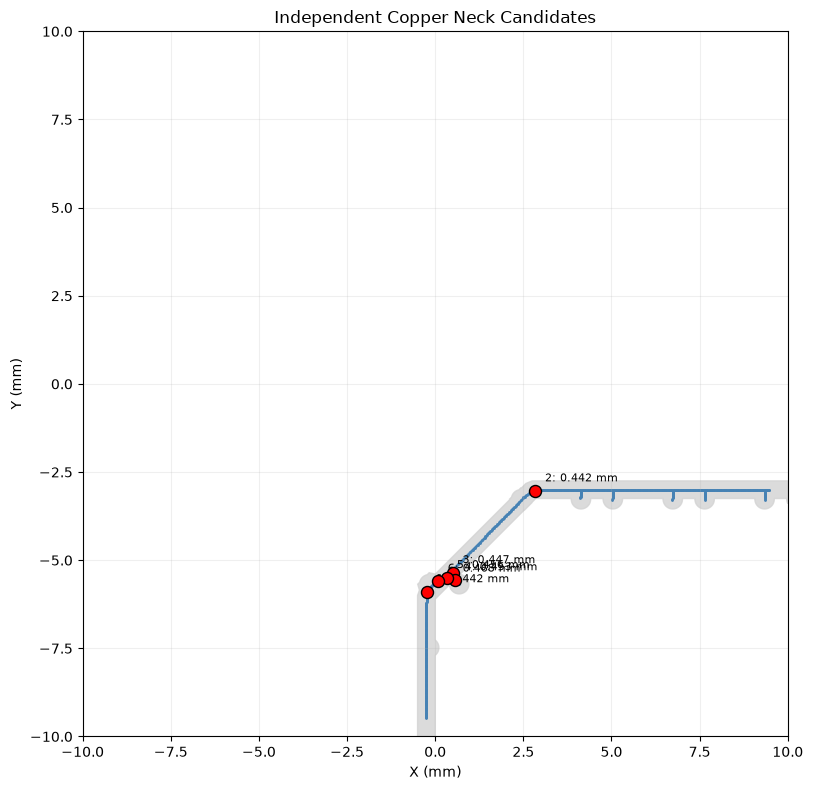

In [40]:
fig, ax = plt.subplots(figsize=(12, 8))

# 원본 Polygon 경계
x, y = target_component.exterior.xy
ax.fill(x, y, color="lightgray", alpha=0.8)

for interior in target_component.interiors:
    hx, hy = interior.xy
    ax.fill(hx, hy, color="white")

# 전체 중심선
sy, sx = np.where(valid_skeleton)

ax.scatter(
    x_coords[sx],
    y_coords[sy],
    s=1,
    c="steelblue",
    label="Skeleton"
)

# 병목 후보 대표 좌표
for rank, row in enumerate(df_neck_regions.itertuples(), start=1):

    ax.scatter(
        row.x_mm,
        row.y_mm,
        s=75,
        c="red",
        edgecolors="black",
        zorder=5
    )

    ax.annotate(
        f"{rank}: {row.min_width_mm:.3f} mm",
        (row.x_mm, row.y_mm),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_aspect("equal")

ax.set_title("Independent Copper Neck Candidates")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [41]:
from scipy.spatial import cKDTree
from shapely.geometry import Point, LineString
import numpy as np
import pandas as pd

# ROI 경계를 제외한 중심선 좌표
skeleton_xy = df_width[["x_mm", "y_mm"]].to_numpy()
skeleton_tree = cKDTree(skeleton_xy)

def estimate_tangent(x, y, radius=0.20):
    """
    병목 주변 중심선 점들의 PCA로
    배선 진행 방향을 추정한다.
    """
    indices = skeleton_tree.query_ball_point(
        [x, y], r=radius
    )

    if len(indices) < 3:
        return None

    pts = skeleton_xy[indices]
    centered = pts - pts.mean(axis=0)

    # PCA
    _, _, vh = np.linalg.svd(
        centered, full_matrices=False
    )

    tangent = vh[0]
    tangent = tangent / np.linalg.norm(tangent)

    return tangent


for row in df_neck_regions.itertuples():
    tangent = estimate_tangent(row.x_mm, row.y_mm)

    print(
        f"({row.x_mm:.2f}, {row.y_mm:.2f})",
        "Tangent:", tangent
    )

(-0.24, -5.90) Tangent: [0.2947742  0.95556694]
(2.84, -3.04) Tangent: [0.97468019 0.22360349]
(0.50, -5.36) Tangent: [0.35142796 0.93621493]
(0.56, -5.56) Tangent: [-0.70441322  0.70979013]
(0.34, -5.50) Tangent: [0.93863491 0.34491232]
(0.08, -5.60) Tangent: [0.89209678 0.45184437]


In [42]:
def extract_lines(geometry):
    """교차 결과에서 LineString만 추출"""
    if geometry.is_empty:
        return []

    if geometry.geom_type == "LineString":
        return [geometry]

    if hasattr(geometry, "geoms"):
        result = []
        for g in geometry.geoms:
            result.extend(extract_lines(g))
        return result

    return []


def measure_cross_section(
    polygon, x, y, tangent, half_length=2.0
):
    """
    중심선 방향에 수직인 선을 만들고,
    해당 지점을 포함하는 구리 단면 길이를 측정.
    """
    normal = np.array([
        -tangent[1],
        tangent[0]
    ])

    center = np.array([x, y])

    p1 = center - half_length * normal
    p2 = center + half_length * normal

    section_line = LineString([p1, p2])

    intersection = polygon.intersection(section_line)

    segments = extract_lines(intersection)

    center_point = Point(x, y)

    # 측정 중심을 포함하는 구리 구간 선택
    containing = [
        seg for seg in segments
        if seg.distance(center_point) < 1e-6
    ]

    if not containing:
        return np.nan, section_line

    width = max(seg.length for seg in containing)

    return width, section_line

In [43]:
validation_results = []
section_lines = []

for rank, row in enumerate(
    df_neck_regions.itertuples(), start=1
):
    x = row.x_mm
    y = row.y_mm

    tangent = estimate_tangent(x, y)

    if tangent is None:
        measured_width = np.nan
        section = None
    else:
        measured_width, section = measure_cross_section(
            target_component,
            x, y,
            tangent
        )

    validation_results.append({
        "rank": rank,
        "x_mm": x,
        "y_mm": y,
        "grid_width_mm": row.min_width_mm,
        "polygon_width_mm": measured_width,
        "difference_mm": (
            measured_width - row.min_width_mm
        )
    })

    section_lines.append(section)

df_validation = pd.DataFrame(validation_results)

display(df_validation.round(4))

,rank,x_mm,y_mm,grid_width_mm,polygon_width_mm,difference_mm
0,1,-0.24,-5.90,0.4418,0.5769,0.1351
1,2,2.84,-3.04,0.4418,0.5130,0.0712
2,3,0.50,-5.36,0.4472,0.7815,0.3343
3,4,0.56,-5.56,0.4525,0.4326,-0.0200
4,5,0.34,-5.50,0.4561,0.7293,0.2733
5,6,0.08,-5.60,0.4682,0.5533,0.0852


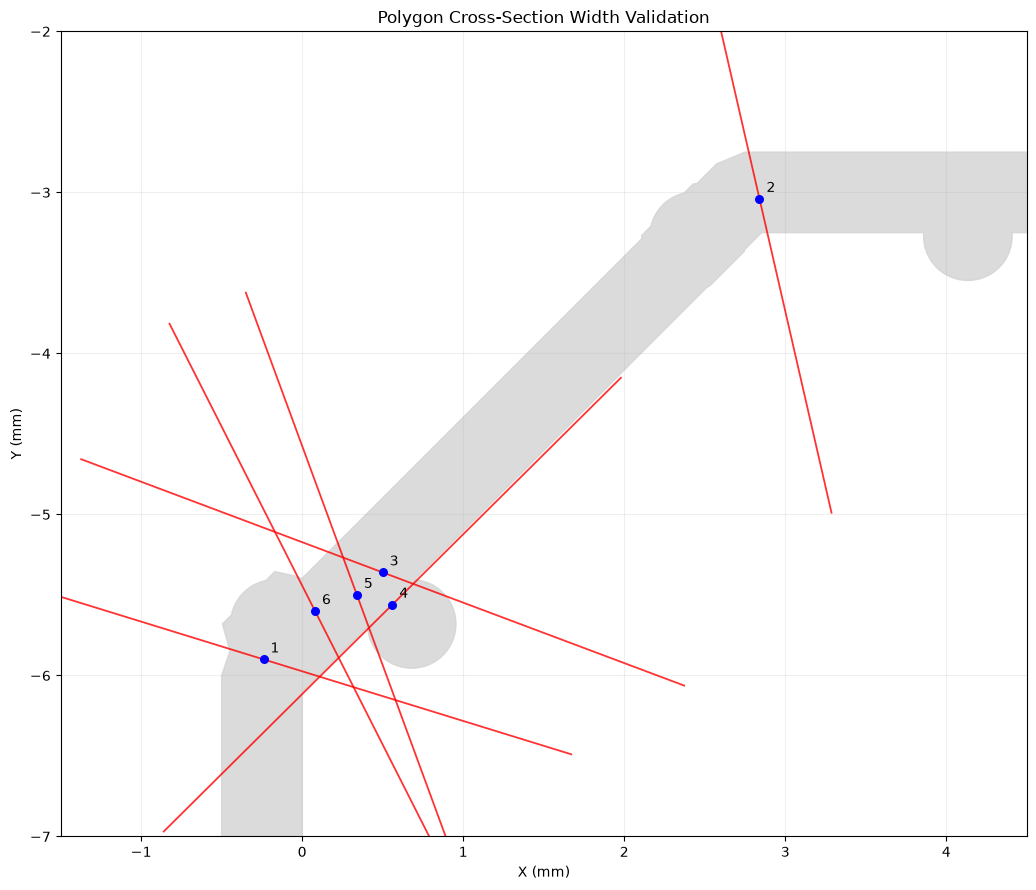

In [44]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

# 구리 형상
x, y = target_component.exterior.xy
ax.fill(x, y, color="lightgray", alpha=0.8)

for interior in target_component.interiors:
    hx, hy = interior.xy
    ax.fill(hx, hy, color="white")

# 병목 단면
for i, (row, section) in enumerate(
    zip(df_validation.itertuples(), section_lines)
):
    if section is None:
        continue

    sx, sy = section.xy

    ax.plot(
        sx, sy,
        color="red",
        linewidth=1.3,
        alpha=0.8
    )

    ax.scatter(
        row.x_mm, row.y_mm,
        color="blue",
        s=30,
        zorder=5
    )

    ax.annotate(
        str(row.rank),
        (row.x_mm, row.y_mm),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlim(-1.5, 4.5)
ax.set_ylim(-7.0, -2.0)
ax.set_aspect("equal")

ax.set_title("Polygon Cross-Section Width Validation")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [45]:
PCA_RADII = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]

sensitivity_records = []

for rank, row in enumerate(
    df_neck_regions.itertuples(), start=1
):
    for radius in PCA_RADII:

        tangent = estimate_tangent(
            row.x_mm,
            row.y_mm,
            radius=radius
        )

        if tangent is None:
            width = np.nan
            angle = np.nan
        else:
            width, _ = measure_cross_section(
                target_component,
                row.x_mm,
                row.y_mm,
                tangent,
                half_length=3.0
            )

            angle = np.degrees(
                np.arctan2(tangent[1], tangent[0])
            ) % 180

        sensitivity_records.append({
            "candidate": rank,
            "pca_radius_mm": radius,
            "width_mm": width,
            "tangent_angle_deg": angle
        })

df_sensitivity = pd.DataFrame(sensitivity_records)

display(
    df_sensitivity.pivot(
        index="candidate",
        columns="pca_radius_mm",
        values="width_mm"
    ).round(4)
)

pca_radius_mm,0.10,0.15,0.20,0.25,0.30,0.40
candidate,,,,,,
1,0.5760,0.5767,0.5769,0.5773,0.5758,0.5764
2,0.5070,0.5090,0.5130,0.5147,0.5170,0.5201
3,0.7707,0.7501,0.7815,0.8121,0.8254,0.8693
4,0.4326,0.4326,0.4326,0.4326,0.4326,0.9565
5,0.7182,0.5653,0.7293,0.7588,0.7815,0.7765
6,0.5433,0.5482,0.5533,0.5568,0.5586,0.5616


In [46]:
df_stability = (
    df_sensitivity
    .groupby("candidate")
    .agg(
        valid_measurements=("width_mm", "count"),
        min_width_mm=("width_mm", "min"),
        max_width_mm=("width_mm", "max"),
        mean_width_mm=("width_mm", "mean"),
        std_width_mm=("width_mm", "std")
    )
    .reset_index()
)

df_stability["width_range_mm"] = (
    df_stability["max_width_mm"]
    - df_stability["min_width_mm"]
)

display(
    df_stability.sort_values(
        "width_range_mm"
    ).round(4)
)

,candidate,valid_measurements,min_width_mm,max_width_mm,mean_width_mm,std_width_mm,width_range_mm
0,1,6,0.5758,0.5773,0.5765,0.0005,0.0015
1,2,6,0.5070,0.5201,0.5135,0.0049,0.0131
5,6,6,0.5433,0.5616,0.5536,0.0068,0.0183
2,3,6,0.7501,0.8693,0.8015,0.0431,0.1192
4,5,6,0.5653,0.7815,0.7216,0.0806,0.2162
3,4,6,0.4326,0.9565,0.5199,0.2139,0.5239


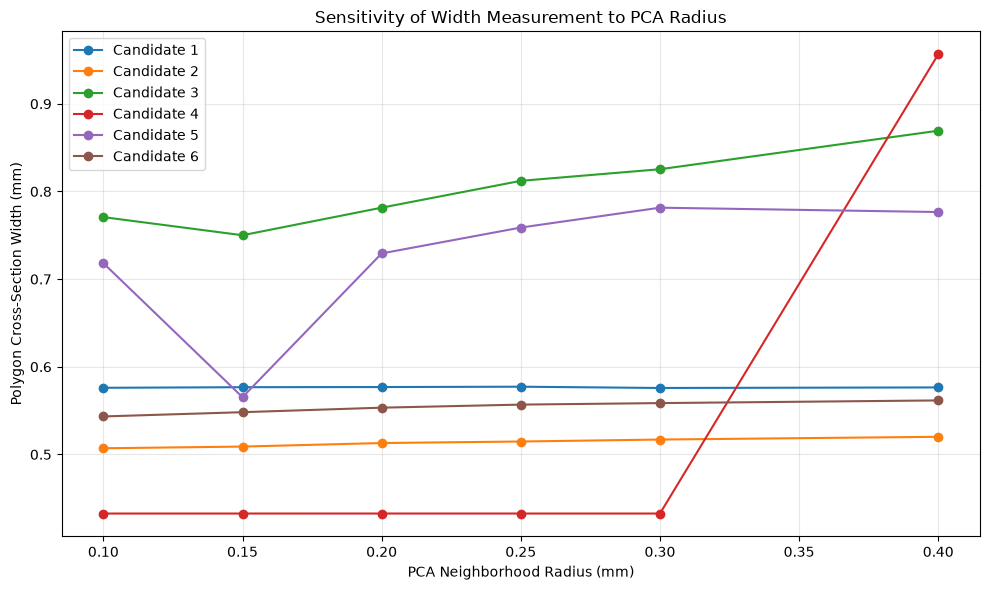

In [47]:
fig, ax = plt.subplots(figsize=(10, 6))

for candidate, group in df_sensitivity.groupby("candidate"):
    ax.plot(
        group["pca_radius_mm"],
        group["width_mm"],
        marker="o",
        label=f"Candidate {candidate}"
    )

ax.set_xlabel("PCA Neighborhood Radius (mm)")
ax.set_ylabel("Polygon Cross-Section Width (mm)")
ax.set_title("Sensitivity of Width Measurement to PCA Radius")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

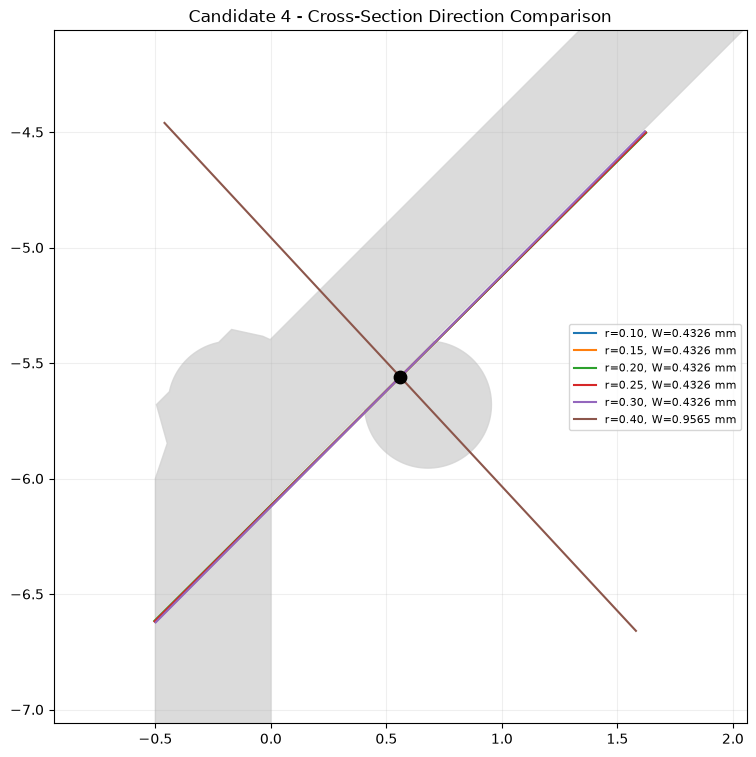

In [48]:
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt

candidate = df_neck_regions.iloc[3]

cx = float(candidate["x_mm"])
cy = float(candidate["y_mm"])

fig, ax = plt.subplots(figsize=(10, 9))

# 실제 구리 Polygon
px, py = target_component.exterior.xy
ax.fill(px, py, color="lightgray", alpha=0.8)

for interior in target_component.interiors:
    hx, hy = interior.xy
    ax.fill(hx, hy, color="white")

colors = plt.get_cmap("tab10")

for i, radius in enumerate(PCA_RADII):
    tangent = estimate_tangent(cx, cy, radius=radius)

    if tangent is None:
        continue

    width, section = measure_cross_section(
        target_component, cx, cy, tangent,
        half_length=1.5
    )

    sx, sy = section.xy

    ax.plot(
        sx, sy,
        color=colors(i),
        linewidth=1.5,
        label=f"r={radius:.2f}, W={width:.4f} mm"
    )

ax.scatter(cx, cy, c="black", s=80, zorder=10)

ax.set_xlim(cx - 1.5, cx + 1.5)
ax.set_ylim(cy - 1.5, cy + 1.5)
ax.set_aspect("equal")
ax.set_title("Candidate 4 - Cross-Section Direction Comparison")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)

plt.show()

In [49]:
angle_results = []

for radius in PCA_RADII:
    tangent = estimate_tangent(cx, cy, radius=radius)

    if tangent is None:
        continue

    angle = np.degrees(
        np.arctan2(tangent[1], tangent[0])
    ) % 180

    width, _ = measure_cross_section(
        target_component,
        cx, cy, tangent,
        half_length=3.0
    )

    angle_results.append({
        "pca_radius_mm": radius,
        "tangent_angle_deg": angle,
        "width_mm": width
    })

df_angle = pd.DataFrame(angle_results)

display(df_angle.round(4))

,pca_radius_mm,tangent_angle_deg,width_mm
0,0.10,135.0000,0.4326
1,0.15,135.0000,0.4326
2,0.20,134.7822,0.4326
3,0.25,134.8710,0.4326
4,0.30,135.1039,0.4326
5,0.40,42.8651,0.9565


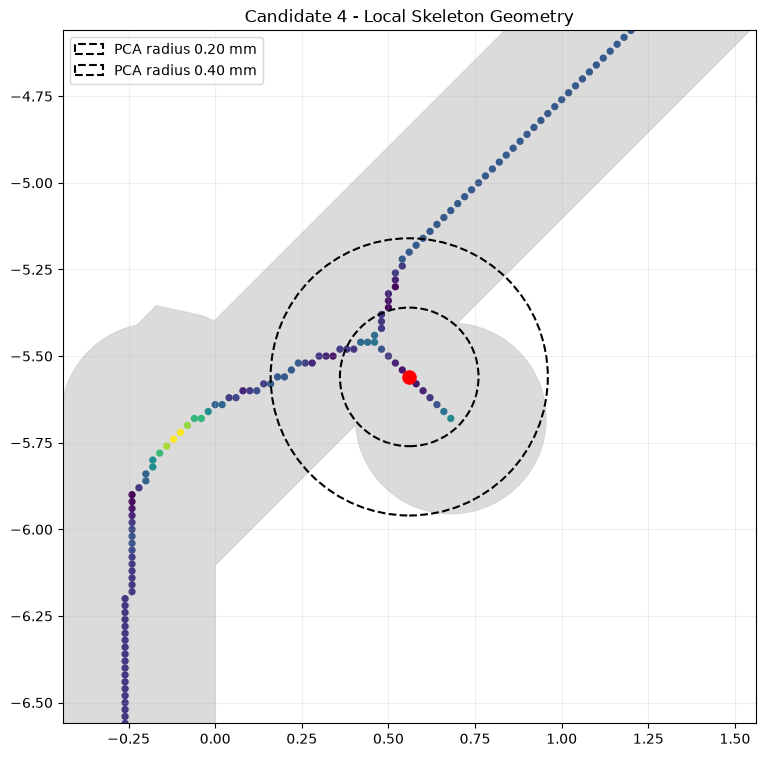

In [50]:
fig, ax = plt.subplots(figsize=(9, 9))

px, py = target_component.exterior.xy
ax.fill(px, py, color="lightgray", alpha=0.8)

nearby = df_width[
    (df_width["x_mm"] - cx).abs() <= 1.0
].copy()

nearby = nearby[
    (nearby["y_mm"] - cy).abs() <= 1.0
]

ax.scatter(
    nearby["x_mm"],
    nearby["y_mm"],
    c=nearby["estimated_width_mm"],
    cmap="viridis",
    s=18
)

ax.scatter(cx, cy, color="red", s=90, zorder=5)

for radius in [0.20, 0.40]:
    ax.add_patch(
        Circle(
            (cx, cy),
            radius,
            fill=False,
            linestyle="--",
            linewidth=1.5,
            label=f"PCA radius {radius:.2f} mm"
        )
    )

ax.set_xlim(cx - 1, cx + 1)
ax.set_ylim(cy - 1, cy + 1)
ax.set_aspect("equal")
ax.set_title("Candidate 4 - Local Skeleton Geometry")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

,tangent_angle_deg,width_mm
68,136,0.432720
67,134,0.432720
69,138,0.432940
66,132,0.432940
22,44,0.956323
23,46,0.956323
21,42,0.956628
24,48,0.956628
20,40,0.957242
25,50,0.957242


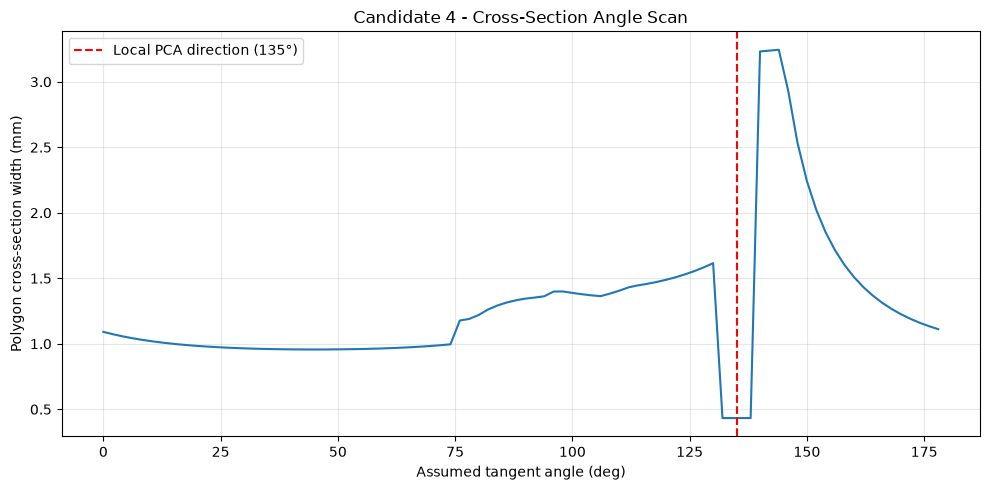

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 후보 4 좌표는 이전 셀의 cx, cy 사용
angles = np.arange(0, 180, 2)

angle_scan = []

for angle in angles:
    rad = np.deg2rad(angle)

    tangent = np.array([
        np.cos(rad),
        np.sin(rad)
    ])

    width, section = measure_cross_section(
        target_component,
        cx, cy,
        tangent,
        half_length=3.0
    )

    angle_scan.append({
        "tangent_angle_deg": angle,
        "width_mm": width
    })

df_angle_scan = pd.DataFrame(angle_scan)

display(
    df_angle_scan.nsmallest(10, "width_mm")
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df_angle_scan["tangent_angle_deg"],
    df_angle_scan["width_mm"]
)

ax.axvline(
    135,
    color="red",
    linestyle="--",
    label="Local PCA direction (135°)"
)

ax.set_xlabel("Assumed tangent angle (deg)")
ax.set_ylabel("Polygon cross-section width (mm)")
ax.set_title("Candidate 4 - Cross-Section Angle Scan")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
local_angles = np.arange(125, 146, 1)

local_results = []

for angle in local_angles:
    rad = np.deg2rad(angle)

    tangent = np.array([
        np.cos(rad),
        np.sin(rad)
    ])

    width, _ = measure_cross_section(
        target_component,
        cx, cy,
        tangent,
        half_length=3.0
    )

    local_results.append({
        "angle_deg": angle,
        "width_mm": width
    })

df_local_angles = pd.DataFrame(local_results)

display(df_local_angles.round(4))

print(
    "125~145° 범위 최소 폭:",
    df_local_angles["width_mm"].min()
)

print(
    "125~145° 범위 최대 폭:",
    df_local_angles["width_mm"].max()
)

,angle_deg,width_mm
0,125,1.5418
1,126,1.5547
2,127,1.5685
3,128,1.5832
4,129,1.5987
5,130,1.6153
6,131,1.6330
7,132,0.4329
8,133,0.4328
9,134,0.4327


125~145° 범위 최소 폭: 0.4325735642055034
125~145° 범위 최대 폭: 3.24778012818003


In [53]:
from shapely.geometry import Point, LineString
import numpy as np
import pandas as pd

def inspect_cross_section(polygon, cx, cy, angle_deg, half_length=5.0):

    rad = np.deg2rad(angle_deg)

    tangent = np.array([np.cos(rad), np.sin(rad)])
    normal = np.array([-tangent[1], tangent[0]])

    center = np.array([cx, cy])

    p1 = center - half_length * normal
    p2 = center + half_length * normal

    line = LineString([p1, p2])
    intersection = polygon.intersection(line)

    segments = extract_lines(intersection)
    center_point = Point(cx, cy)

    records = []

    for i, segment in enumerate(segments):
        records.append({
            "angle_deg": angle_deg,
            "segment": i,
            "length_mm": segment.length,
            "distance_to_center_mm": segment.distance(center_point),
            "start": tuple(segment.coords[0]),
            "end": tuple(segment.coords[-1])
        })

    return line, segments, pd.DataFrame(records)


for angle in [130, 132, 135, 138, 139, 145]:

    line, segments, df_segments = inspect_cross_section(
        target_component, cx, cy, angle
    )

    print(f"\n=== Angle {angle}° ===")
    display(df_segments)


=== Angle 130° ===


,angle_deg,segment,length_mm,distance_to_center_mm,start,end
0,130,0,0.777862,3.593722e+00,"(3.9088275951898432, -2.75)","(3.3129507988927385, -3.25)"
1,130,1,1.615333,2.577387e-16,"(0.7374165002665929, -5.411129880061633)","(-0.5, -6.449445609048012)"



=== Angle 132° ===


,angle_deg,segment,length_mm,distance_to_center_mm,start,end
0,132,0,0.747238,3.452241e+00,"(3.680821166670138, -2.75)","(3.125514909255542, -3.25)"
1,132,1,0.432940,3.846569e-16,"(0.727467756372678, -5.409211354872651)","(0.4057304145670296, -5.698904958636094)"
2,132,2,1.204792,2.215790e-01,"(0.39533467915966725, -5.708265320840333)","(-0.5, -6.514428286955806)"



=== Angle 135° ===


,angle_deg,segment,length_mm,distance_to_center_mm,start,end
0,135,0,0.707107,3.266833e+00,"(3.3700000000000956, -2.75)","(2.8700000000000956, -3.25)"
1,135,1,0.432574,4.812287e-17,"(0.7129378503059209, -5.407062149694174)","(0.407062149694175, -5.712937850305921)"
2,135,2,0.707107,7.919596e-01,"(0.0, -6.120000000000095)","(-0.5, -6.620000000000095)"


... (2 outputs left out)


=== Angle 139° ===


,angle_deg,segment,length_mm,distance_to_center_mm,start,end
0,139,0,3.951805,2.247526e-16,"(3.00269573326368, -2.75)","(0.4100784595404743, -5.732465003706641)"
1,139,1,0.762127,8.535817e-01,"(0.0, -6.204206308043861)","(-0.5, -6.779390511654365)"



=== Angle 145° ===


,angle_deg,segment,length_mm,distance_to_center_mm,start,end
0,145,0,3.358061,0.00000,"(2.343983847553004, -3.012207024057144)","(0.4178791570798938, -5.762969598532955)"
1,145,1,0.871723,0.97633,"(0.0, -6.35976288377568)","(-0.5, -7.073836887146737)"


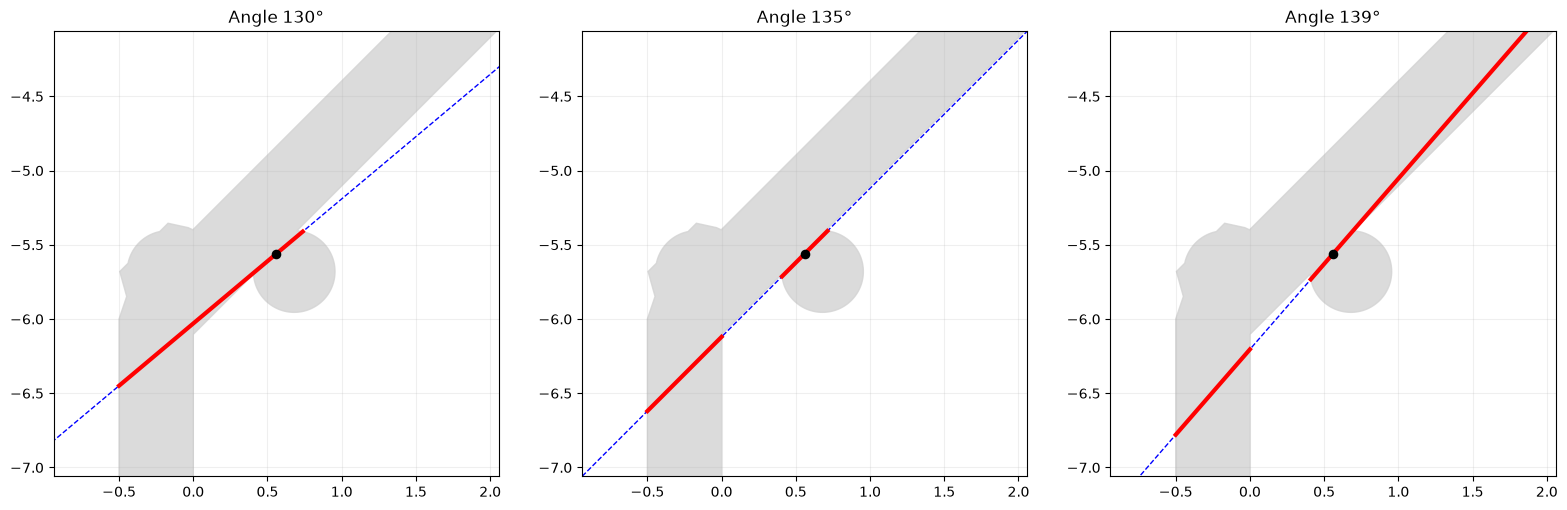

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, angle in zip(axes, [130, 135, 139]):

    px, py = target_component.exterior.xy
    ax.fill(px, py, color="lightgray", alpha=0.8)

    for interior in target_component.interiors:
        hx, hy = interior.xy
        ax.fill(hx, hy, color="white")

    line, segments, _ = inspect_cross_section(
        target_component, cx, cy, angle
    )

    lx, ly = line.xy
    ax.plot(lx, ly, "--", color="blue", linewidth=1)

    for segment in segments:
        sx, sy = segment.xy

        ax.plot(
            sx, sy,
            color="red",
            linewidth=3
        )

    ax.scatter(cx, cy, color="black", s=35, zorder=5)

    ax.set_xlim(cx - 1.5, cx + 1.5)
    ax.set_ylim(cy - 1.5, cy + 1.5)
    ax.set_aspect("equal")
    ax.set_title(f"Angle {angle}°")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

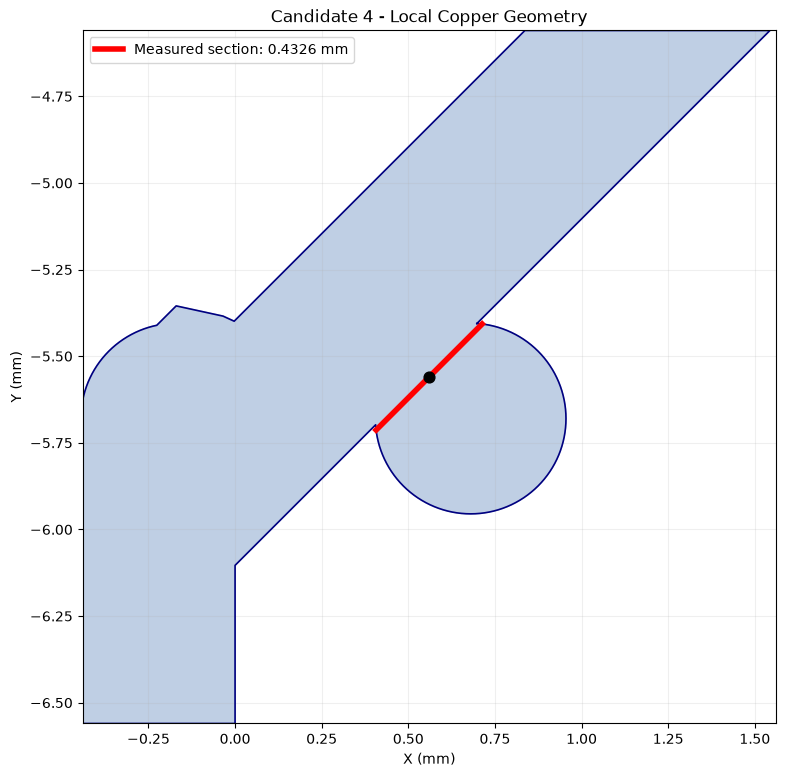

In [55]:
from shapely.geometry import box
import matplotlib.pyplot as plt

ZOOM_MM = 1.0

zoom_box = box(
    cx - ZOOM_MM, cy - ZOOM_MM,
    cx + ZOOM_MM, cy + ZOOM_MM
)

local_copper = target_component.intersection(zoom_box)

fig, ax = plt.subplots(figsize=(9, 9))

# 구리 형상 표시
if not local_copper.is_empty:
    polygons = (
        [local_copper]
        if local_copper.geom_type == "Polygon"
        else [
            g for g in getattr(local_copper, "geoms", [])
            if g.geom_type == "Polygon"
        ]
    )

    for poly in polygons:
        x, y = poly.exterior.xy
        ax.fill(x, y, color="lightsteelblue", alpha=0.8)
        ax.plot(x, y, color="navy", linewidth=1.2)

        for ring in poly.interiors:
            hx, hy = ring.xy
            ax.fill(hx, hy, color="white")

# 135도에서 실제 구리와 겹치는 단면
_, segments, df_segments = inspect_cross_section(
    target_component, cx, cy, 135
)

for seg in segments:
    if seg.distance(Point(cx, cy)) < 1e-6:
        sx, sy = seg.xy
        ax.plot(
            sx, sy,
            color="red",
            linewidth=4,
            label=f"Measured section: {seg.length:.4f} mm"
        )

ax.scatter(cx, cy, color="black", s=60, zorder=5)

ax.set_xlim(cx - ZOOM_MM, cx + ZOOM_MM)
ax.set_ylim(cy - ZOOM_MM, cy + ZOOM_MM)
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("Candidate 4 - Local Copper Geometry")
ax.grid(alpha=0.2)
ax.legend()

plt.show()

In [56]:
from shapely.geometry import LineString
from shapely.ops import split
import numpy as np

# 후보 4에서 135도에 수직인 단면선
angle = np.deg2rad(135)

normal = np.array([
    -np.sin(angle),
    np.cos(angle)
])

center = np.array([cx, cy])

# 충분히 긴 절단선
cut_half_length = 5.0

cut_line = LineString([
    center - cut_half_length * normal,
    center + cut_half_length * normal
])

# 전체 연결 성분에 대한 절단 시험
split_result = split(target_component, cut_line)

split_polygons = [
    g for g in split_result.geoms
    if g.geom_type == "Polygon" and g.area > 1e-8
]

print("Original component count: 1")
print("After split component count:", len(split_polygons))

for i, poly in enumerate(
    sorted(split_polygons, key=lambda p: p.area, reverse=True),
    start=1
):
    print(f"Part {i}: {poly.area:.6f} mm²")

Original component count: 1
After split component count: 4
Part 1: 4.097168 mm²
Part 2: 2.598161 mm²
Part 3: 1.846618 mm²
Part 4: 0.205742 mm²


In [57]:
from shapely.geometry import Point, LineString
import matplotlib.pyplot as plt

# 후보 4에서 실제 측정된 135도 단면
_, segments, _ = inspect_cross_section(
    target_component, cx, cy, 135
)

center_point = Point(cx, cy)

center_segments = [
    seg for seg in segments
    if seg.distance(center_point) < 1e-6
]

neck_segment = min(
    center_segments,
    key=lambda seg: seg.length
)

print("Measured neck section:", neck_segment.length, "mm")

# 측정 단면 주변에 매우 얇은 제거 영역 생성
CUT_WIDTH_MM = 0.02

cut_strip = neck_segment.buffer(
    CUT_WIDTH_MM / 2,
    cap_style=2,
    join_style=2
)

copper_after_cut = target_component.difference(cut_strip)

def get_polygons(geometry):
    if geometry.is_empty:
        return []

    if geometry.geom_type == "Polygon":
        return [geometry]

    if hasattr(geometry, "geoms"):
        result = []
        for g in geometry.geoms:
            result.extend(get_polygons(g))
        return result

    return []

cut_components = [
    p for p in get_polygons(copper_after_cut)
    if p.area > 1e-8
]

cut_components.sort(
    key=lambda p: p.area,
    reverse=True
)

print("After local cut:", len(cut_components), "components")

for i, p in enumerate(cut_components, start=1):
    print(f"Component {i}: {p.area:.6f} mm²")

Measured neck section: 0.4325735642055041 mm
After local cut: 2 components
Component 1: 8.537701 mm²
Component 2: 0.201416 mm²


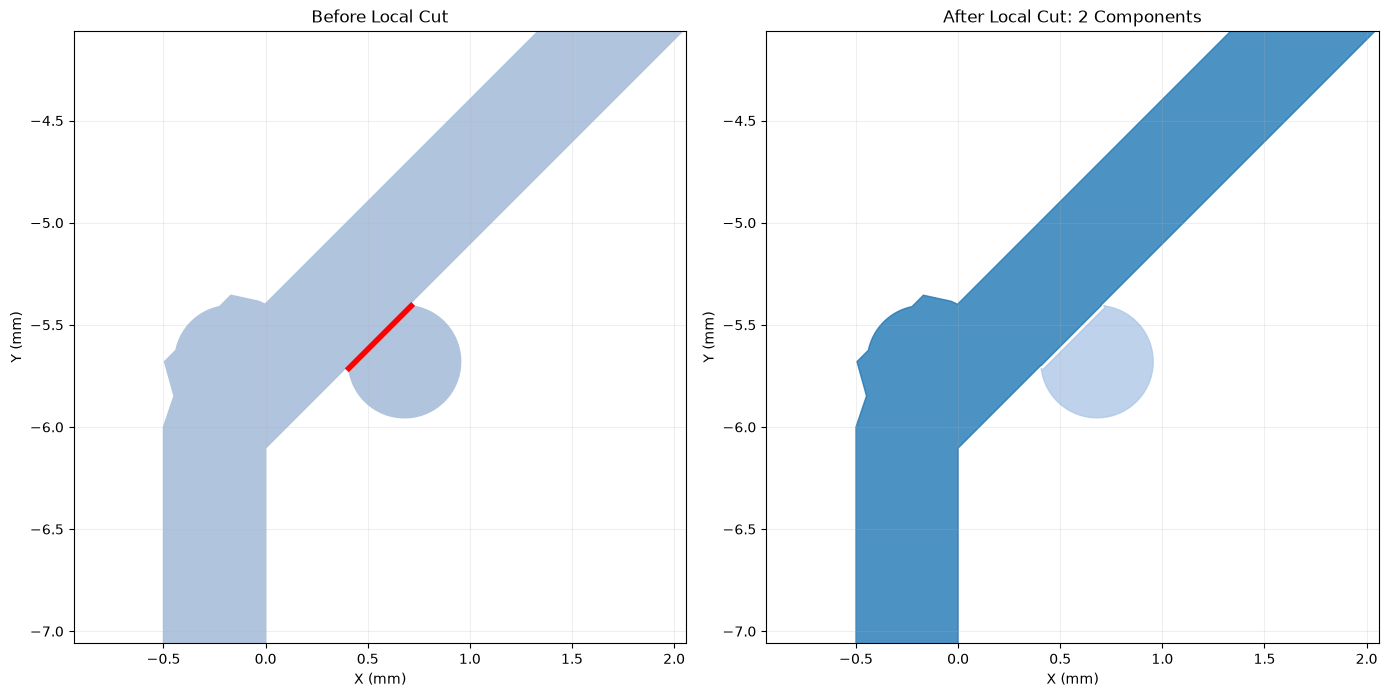

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# 절단 전
x, y = target_component.exterior.xy
axes[0].fill(x, y, color="lightsteelblue")

sx, sy = neck_segment.xy
axes[0].plot(
    sx, sy,
    color="red",
    linewidth=4
)

axes[0].set_title("Before Local Cut")

# 절단 후
colors = plt.get_cmap("tab20")

for i, poly in enumerate(cut_components):
    x, y = poly.exterior.xy

    axes[1].fill(
        x, y,
        color=colors(i % 20),
        alpha=0.8
    )

    for ring in poly.interiors:
        hx, hy = ring.xy
        axes[1].fill(hx, hy, color="white")

axes[1].set_title(
    f"After Local Cut: {len(cut_components)} Components"
)

for ax in axes:
    ax.set_xlim(cx - 1.5, cx + 1.5)
    ax.set_ylim(cy - 1.5, cy + 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [59]:
# 후보 2: 기존 병목 후보 표의 두 번째 행
candidate2 = df_neck_regions.iloc[1]

c2x = float(candidate2["x_mm"])
c2y = float(candidate2["y_mm"])

# 기존 PCA 방향 추정
tangent2 = estimate_tangent(
    c2x, c2y, radius=0.20
)

width2, section2 = measure_cross_section(
    target_component,
    c2x, c2y,
    tangent2,
    half_length=3.0
)

# 실제 중심점을 포함하는 교차 구간
segments2 = extract_lines(
    target_component.intersection(section2)
)

center2 = Point(c2x, c2y)

neck2 = min(
    [
        seg for seg in segments2
        if seg.distance(center2) < 1e-6
    ],
    key=lambda seg: seg.length
)

# 동일한 절단 두께 적용
cut_strip2 = neck2.buffer(
    0.01,
    cap_style=2,
    join_style=2
)

copper_after_cut2 = target_component.difference(cut_strip2)

components2 = [
    p for p in get_polygons(copper_after_cut2)
    if p.area > 1e-8
]

components2.sort(key=lambda p: p.area, reverse=True)

print("Candidate 2 width:", round(neck2.length, 6), "mm")
print("After cut:", len(components2), "components")

total_area2 = sum(p.area for p in components2)

for i, p in enumerate(components2, start=1):
    print(
        f"Component {i}: "
        f"{p.area:.6f} mm² "
        f"({100*p.area/total_area2:.2f}%)"
    )

Candidate 2 width: 0.512989 mm
After cut: 2 components
Component 1: 4.500815 mm² (51.51%)
Component 2: 4.236637 mm² (48.49%)


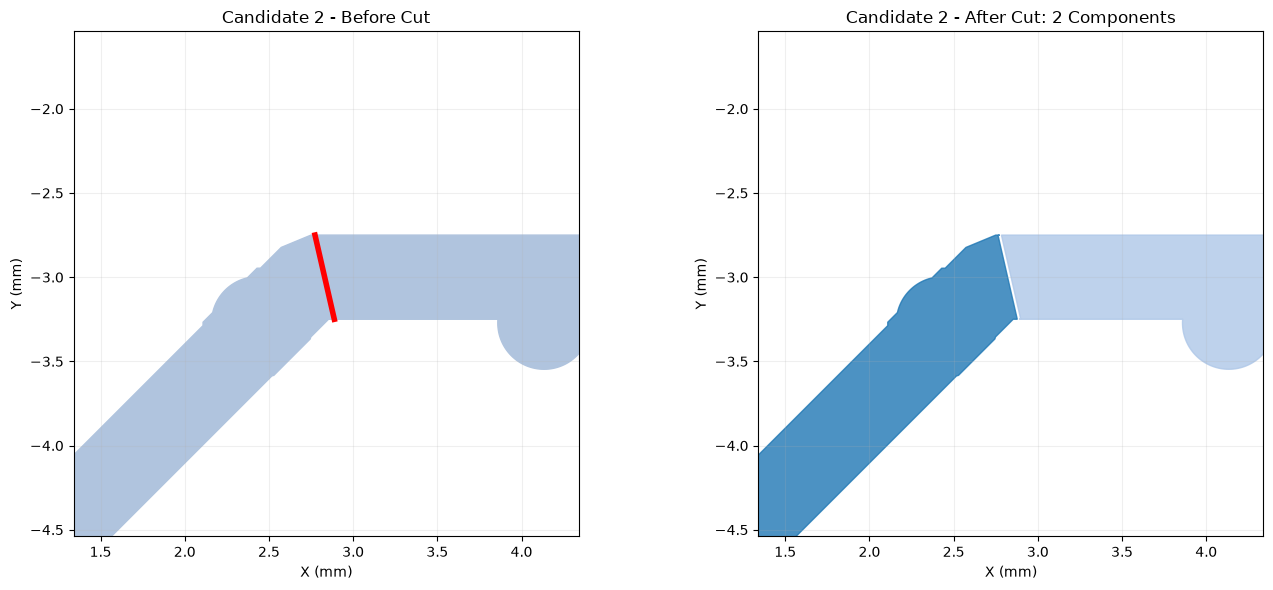

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 절단 전
px, py = target_component.exterior.xy
axes[0].fill(px, py, color="lightsteelblue")

sx, sy = neck2.xy
axes[0].plot(sx, sy, color="red", linewidth=4)

axes[0].set_title("Candidate 2 - Before Cut")

# 절단 후
cmap = plt.get_cmap("tab20")

for i, poly in enumerate(components2):
    px, py = poly.exterior.xy
    axes[1].fill(
        px, py,
        color=cmap(i % 20),
        alpha=0.8
    )

    for ring in poly.interiors:
        hx, hy = ring.xy
        axes[1].fill(hx, hy, color="white")

axes[1].set_title(
    f"Candidate 2 - After Cut: {len(components2)} Components"
)

for ax in axes:
    ax.set_xlim(c2x - 1.5, c2x + 1.5)
    ax.set_ylim(c2y - 1.5, c2y + 1.5)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")

plt.tight_layout()
plt.show()

In [61]:
CUT_WIDTHS_MM = [0.005, 0.01, 0.02, 0.04, 0.08]

cut_test_results = []

for candidate_name, segment in [
    ("Candidate 2", neck2),
    ("Candidate 4", neck_segment)
]:
    for cut_width in CUT_WIDTHS_MM:

        strip = segment.buffer(
            cut_width / 2,
            cap_style=2,
            join_style=2
        )

        remaining = target_component.difference(strip)

        parts = sorted(
            [
                p for p in get_polygons(remaining)
                if p.area > 1e-8
            ],
            key=lambda p: p.area,
            reverse=True
        )

        total_area = sum(p.area for p in parts)

        cut_test_results.append({
            "candidate": candidate_name,
            "cut_width_mm": cut_width,
            "component_count": len(parts),
            "largest_area_pct": (
                100 * parts[0].area / total_area
                if parts else np.nan
            ),
            "second_area_pct": (
                100 * parts[1].area / total_area
                if len(parts) > 1 else 0
            )
        })

df_cut_robustness = pd.DataFrame(cut_test_results)

display(df_cut_robustness.round(4))

,candidate,cut_width_mm,component_count,largest_area_pct,second_area_pct
0,Candidate 2,0.005,2,51.5104,48.4896
1,Candidate 2,0.010,2,51.5109,48.4891
2,Candidate 2,0.020,2,51.5118,48.4882
3,Candidate 2,0.040,2,51.5135,48.4865
4,Candidate 2,0.080,2,51.5169,48.4831
5,Candidate 4,0.005,2,97.6598,2.3402
6,Candidate 4,0.010,2,97.6716,2.3284
7,Candidate 4,0.020,2,97.6952,2.3048
8,Candidate 4,0.040,2,97.7425,2.2575
9,Candidate 4,0.080,2,97.8373,2.1627


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import label
from scipy.spatial import cKDTree

required = [
    "target_component",
    "copper_mask",
    "skeleton",
    "distance_mm",
    "x_coords",
    "y_coords"
]

for name in required:
    if name not in globals():
        raise NameError(f"Missing variable: {name}")

GRID_MM = float(np.mean(np.diff(x_coords)))

print("Grid resolution:", GRID_MM, "mm")
print("Copper area:", target_component.area, "mm²")
print("Skeleton pixels:", int(skeleton.sum()))

# 구리 폭이 일정하게 유지되는 구간을 비교하기 위한 기준
WIDTH_LIMIT_MM = 0.8

# 서로 다른 구간을 동일한 길이로 비교
WINDOW_LENGTH_MM = 1.0

Grid resolution: 0.020000000000000018 mm
Copper area: 8.747688850544684 mm²
Skeleton pixels: 795


In [63]:
local_width_mm = 2.0 * distance_mm

# ROI 경계 부근 제외
margin_mm = 0.5

XX, YY = np.meshgrid(x_coords, y_coords)

valid_skeleton = (
    skeleton
    & (XX > X_MIN + margin_mm)
    & (XX < X_MAX - margin_mm)
    & (YY > Y_MIN + margin_mm)
    & (YY < Y_MAX - margin_mm)
)

width_values = local_width_mm[valid_skeleton]

print("Valid skeleton points:", len(width_values))
print("Minimum width:", width_values.min(), "mm")
print("Median width:", np.median(width_values), "mm")
print("Maximum width:", width_values.max(), "mm")

Valid skeleton points: 752
Minimum width: 0.44181444068749043 mm
Median width: 0.52 mm
Maximum width: 0.6835202996254025 mm


In [64]:
import networkx as nx

ys, xs = np.where(valid_skeleton)

pixel_set = set(zip(ys, xs))

G = nx.Graph()

for y, x in pixel_set:

    G.add_node(
        (y, x),
        width_mm=float(local_width_mm[y, x]),
        x_mm=float(x_coords[x]),
        y_mm=float(y_coords[y])
    )

    for dy, dx in [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1), (0, 1),
        (1, -1), (1, 0), (1, 1)
    ]:

        neighbor = (y + dy, x + dx)

        if neighbor not in pixel_set:
            continue

        length = GRID_MM * np.hypot(dx, dy)

        G.add_edge(
            (y, x),
            neighbor,
            length_mm=length
        )

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
print(
    "Connected skeleton components:",
    nx.number_connected_components(G)
)

Graph nodes: 752
Graph edges: 757
Connected skeleton components: 1


In [65]:
degree = dict(G.degree())

critical_nodes = {
    node for node, deg in degree.items()
    if deg != 2
}

visited_edges = set()
paths = []

def edge_key(a, b):
    return frozenset((a, b))

for start in critical_nodes:

    for neighbor in G.neighbors(start):

        ek = edge_key(start, neighbor)

        if ek in visited_edges:
            continue

        path = [start, neighbor]
        visited_edges.add(ek)

        prev = start
        current = neighbor

        while current not in critical_nodes:

            next_nodes = [
                n for n in G.neighbors(current)
                if n != prev
            ]

            if not next_nodes:
                break

            nxt = next_nodes[0]

            ek = edge_key(current, nxt)

            if ek in visited_edges:
                break

            visited_edges.add(ek)

            path.append(nxt)

            prev, current = current, nxt

        paths.append(path)

print("Extracted paths:", len(paths))

Extracted paths: 31


In [66]:
path_records = []

for path_id, path in enumerate(paths):

    if len(path) < 2:
        continue

    total_length = 0.0
    resistance_score = 0.0
    widths = []

    for a, b in zip(path[:-1], path[1:]):

        ds = G.edges[a, b]["length_mm"]

        wa = G.nodes[a]["width_mm"]
        wb = G.nodes[b]["width_mm"]

        w_avg = (wa + wb) / 2

        if w_avg <= 0:
            continue

        total_length += ds
        resistance_score += ds / w_avg

        widths.extend([wa, wb])

    if total_length == 0:
        continue

    coords = np.array([
        [
            G.nodes[node]["x_mm"],
            G.nodes[node]["y_mm"]
        ]
        for node in path
    ])

    path_records.append({
        "path_id": path_id,
        "length_mm": total_length,
        "min_width_mm": min(widths),
        "mean_width_mm": np.mean(widths),
        "relative_resistance": resistance_score,
        "center_x_mm": coords[:, 0].mean(),
        "center_y_mm": coords[:, 1].mean(),
        "node_count": len(path)
    })

df_paths = pd.DataFrame(path_records)

display(
    df_paths.sort_values(
        "relative_resistance",
        ascending=False
    ).head(20).round(4)
)

,path_id,length_mm,min_width_mm,mean_width_mm,relative_resistance,center_x_mm,center_y_mm,node_count
22,22,4.7844,0.4418,0.5104,9.3825,2.2211,-3.7815,193
9,9,4.4740,0.4418,0.4880,9.1640,-0.1997,-7.3457,216
6,6,1.6966,0.5200,0.5205,3.2586,8.4800,-3.0005,85
20,20,1.6966,0.5200,0.5205,3.2586,5.8800,-3.0005,85
5,5,0.8966,0.5200,0.5209,1.7201,4.5800,-3.0009,45
1,1,0.8966,0.5200,0.5209,1.7201,7.1800,-3.0009,45
15,15,0.3111,0.4525,0.4868,0.6414,0.5700,-5.5700,12
30,30,0.2483,0.5122,0.5949,0.4208,6.7369,-3.1600,13
27,27,0.2483,0.5122,0.5949,0.4208,5.0369,-3.1600,13
17,17,0.2483,0.5122,0.5980,0.4184,9.3415,-3.1600,13


In [67]:
df_paths["resistance_per_mm"] = (
    df_paths["relative_resistance"]
    / df_paths["length_mm"]
)

# 너무 짧은 중심선 조각은 제외
MIN_PATH_LENGTH_MM = 0.20

df_ranked = df_paths[
    df_paths["length_mm"] >= MIN_PATH_LENGTH_MM
].copy()

df_ranked = df_ranked.sort_values(
    "resistance_per_mm",
    ascending=False
).reset_index(drop=True)

df_ranked["rank"] = np.arange(
    1, len(df_ranked) + 1
)

display(
    df_ranked[
        [
            "rank",
            "path_id",
            "center_x_mm",
            "center_y_mm",
            "length_mm",
            "min_width_mm",
            "mean_width_mm",
            "relative_resistance",
            "resistance_per_mm"
        ]
    ].head(20).round(4)
)

,rank,path_id,center_x_mm,center_y_mm,length_mm,min_width_mm,mean_width_mm,relative_resistance,resistance_per_mm
0,1,15,0.5700,-5.5700,0.3111,0.4525,0.4868,0.6414,2.0615
1,2,9,-0.1997,-7.3457,4.4740,0.4418,0.4880,9.1640,2.0483
2,3,22,2.2211,-3.7815,4.7844,0.4418,0.5104,9.3825,1.9611
3,4,6,8.4800,-3.0005,1.6966,0.5200,0.5205,3.2586,1.9207
4,5,20,5.8800,-3.0005,1.6966,0.5200,0.5205,3.2586,1.9207
5,6,5,4.5800,-3.0009,0.8966,0.5200,0.5209,1.7201,1.9186
6,7,1,7.1800,-3.0009,0.8966,0.5200,0.5209,1.7201,1.9186
7,8,27,5.0369,-3.1600,0.2483,0.5122,0.5949,0.4208,1.6948
8,9,30,6.7369,-3.1600,0.2483,0.5122,0.5949,0.4208,1.6948
9,10,12,7.6415,-3.1600,0.2483,0.5122,0.5980,0.4184,1.6851


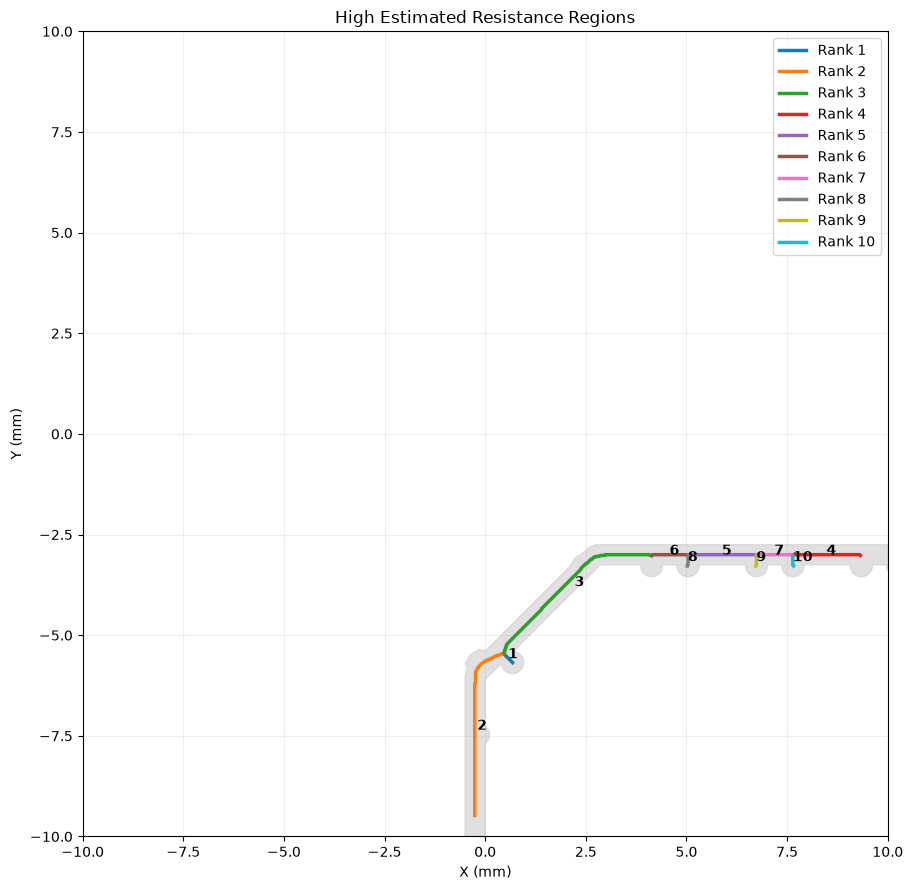

In [68]:
fig, ax = plt.subplots(figsize=(12, 9))

px, py = target_component.exterior.xy

ax.fill(
    px, py,
    color="lightgray",
    alpha=0.7
)

for ring in target_component.interiors:
    hx, hy = ring.xy
    ax.fill(hx, hy, color="white")

top_paths = df_ranked.head(10)

colors = plt.get_cmap("tab10")

for i, row in enumerate(top_paths.itertuples()):

    path = paths[int(row.path_id)]

    coords = np.array([
        [
            G.nodes[node]["x_mm"],
            G.nodes[node]["y_mm"]
        ]
        for node in path
    ])

    ax.plot(
        coords[:, 0],
        coords[:, 1],
        color=colors(i % 10),
        linewidth=2.5,
        label=f"Rank {i+1}"
    )

    ax.text(
        row.center_x_mm,
        row.center_y_mm,
        str(i+1),
        fontsize=10,
        weight="bold"
    )

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("High Estimated Resistance Regions")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [69]:
final_columns = [
    "rank",
    "path_id",
    "center_x_mm",
    "center_y_mm",
    "length_mm",
    "min_width_mm",
    "mean_width_mm",
    "relative_resistance",
    "resistance_per_mm"
]

df_final_candidates = df_ranked[
    final_columns
].head(10).copy()

df_final_candidates.to_csv(
    "VCC7_high_resistance_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Top 10 high-resistance candidates")
display(df_final_candidates.round(4))

print("Saved: VCC7_high_resistance_candidates.csv")

Top 10 high-resistance candidates


,rank,path_id,center_x_mm,center_y_mm,length_mm,min_width_mm,mean_width_mm,relative_resistance,resistance_per_mm
0,1,15,0.5700,-5.5700,0.3111,0.4525,0.4868,0.6414,2.0615
1,2,9,-0.1997,-7.3457,4.4740,0.4418,0.4880,9.1640,2.0483
2,3,22,2.2211,-3.7815,4.7844,0.4418,0.5104,9.3825,1.9611
3,4,6,8.4800,-3.0005,1.6966,0.5200,0.5205,3.2586,1.9207
4,5,20,5.8800,-3.0005,1.6966,0.5200,0.5205,3.2586,1.9207
5,6,5,4.5800,-3.0009,0.8966,0.5200,0.5209,1.7201,1.9186
6,7,1,7.1800,-3.0009,0.8966,0.5200,0.5209,1.7201,1.9186
7,8,27,5.0369,-3.1600,0.2483,0.5122,0.5949,0.4208,1.6948
8,9,30,6.7369,-3.1600,0.2483,0.5122,0.5949,0.4208,1.6948
9,10,12,7.6415,-3.1600,0.2483,0.5122,0.5980,0.4184,1.6851


Saved: VCC7_high_resistance_candidates.csv


=== VCC7 Gerber ===
Objects: 44114
Bounds: (-242.59, -242.59, 242.59, 242.59)
Dark regions: 1
Clear regions: 94
Circular flashes: 44018
Unsupported objects: {'ObroundAperture': 1}

=== Full VCC7 scan started ===
Total tiles: 441
20/441 tiles (4.5%) | Candidates: 2144 | Elapsed: 2.2s
40/441 tiles (9.1%) | Candidates: 5574 | Elapsed: 3.6s
60/441 tiles (13.6%) | Candidates: 10674 | Elapsed: 5.2s
80/441 tiles (18.1%) | Candidates: 16792 | Elapsed: 6.8s
100/441 tiles (22.7%) | Candidates: 23721 | Elapsed: 8.6s
120/441 tiles (27.2%) | Candidates: 31321 | Elapsed: 10.4s
140/441 tiles (31.7%) | Candidates: 38519 | Elapsed: 12.2s
160/441 tiles (36.3%) | Candidates: 46456 | Elapsed: 14.1s
180/441 tiles (40.8%) | Candidates: 55259 | Elapsed: 15.9s
200/441 tiles (45.4%) | Candidates: 62576 | Elapsed: 17.4s
220/441 tiles (49.9%) | Candidates: 71468 | Elapsed: 18.8s
240/441 tiles (54.4%) | Candidates: 79398 | Elapsed: 20.4s
260/441 tiles (59.0%) | Candidates: 89526 | Elapsed: 22.4s
280/441 tiles (63

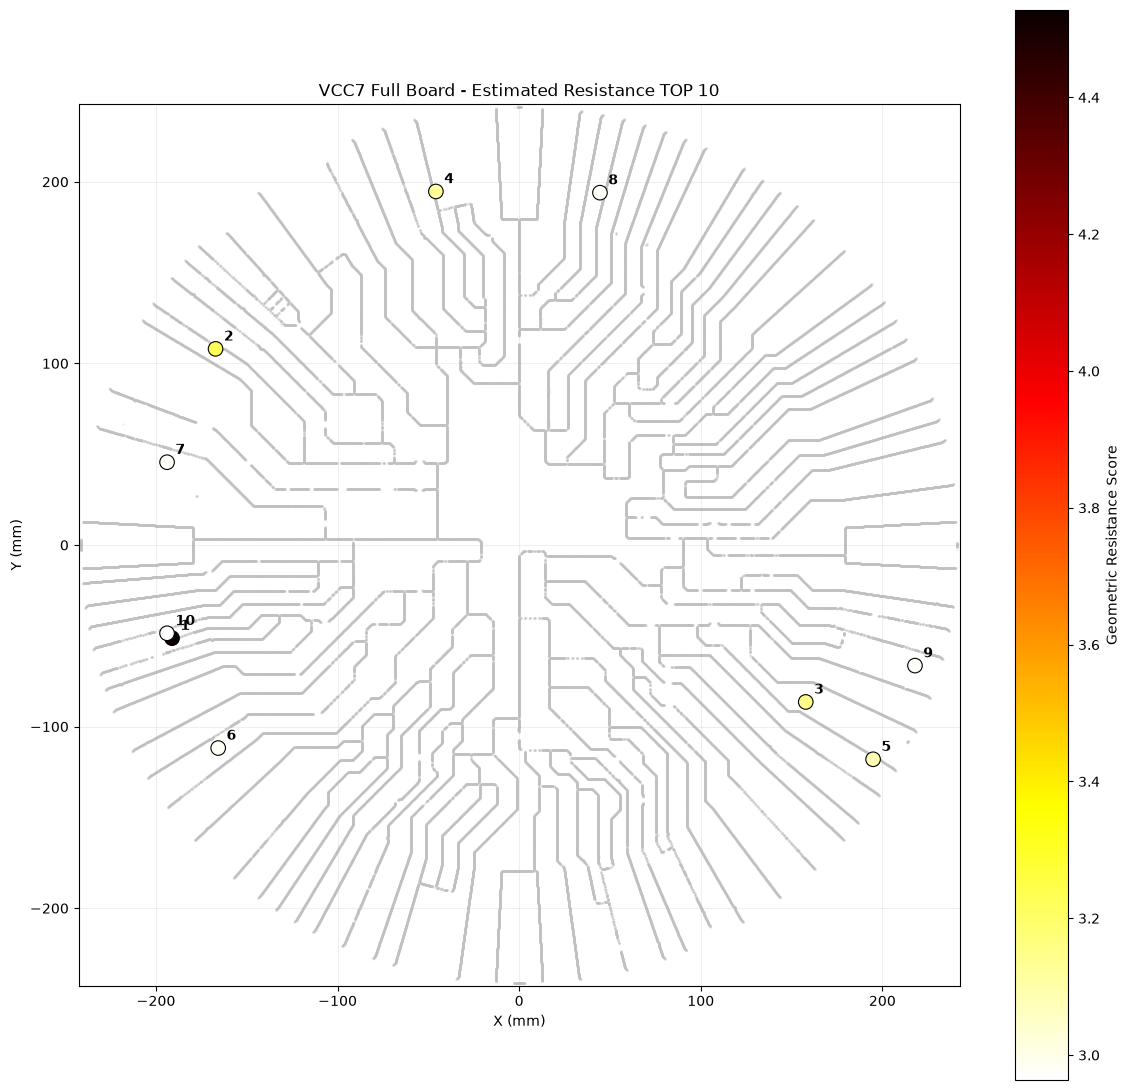

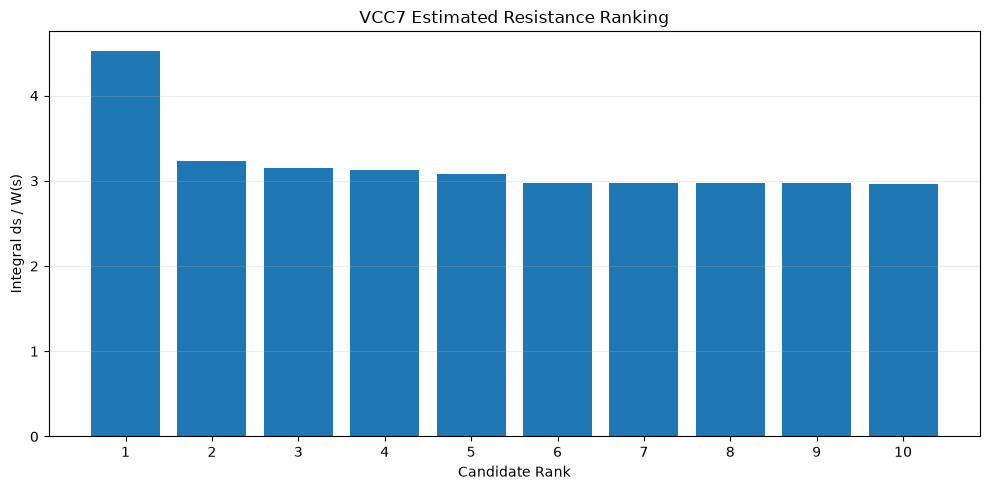


=== Analysis completed ===
Elapsed: 39.8 seconds

Saved files:
1. VCC7_TOP10_estimated_resistance.csv
2. VCC7_all_resistance_candidates.csv
3. VCC7_TOP10_estimated_resistance.png
4. VCC7_TOP10_resistance_ranking.png


In [75]:
# ============================================================
# VCC7 전체 Gerber - 예상 저항이 높은 1 mm 배선 구간 TOP 10
# 하나의 Jupyter 셀에서 실행
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gerbonara import GerberFile
from shapely.geometry import Polygon, box
from shapely import contains_xy
from scipy.ndimage import distance_transform_edt
from scipy.spatial import cKDTree
from skimage.morphology import skeletonize

# ============================================================
# 1. 설정
# ============================================================

FILE_PATH = Path("VCC7.art")

GRID_MM = 0.08
TILE_MM = 24.0
HALO_MM = 2.0

WINDOW_MM = 1.0
MIN_WIDTH_MM = 0.16
MAX_WIDTH_MM = 3.0

TOP_N = 10
MIN_SEPARATION_MM = 1.0

# 폭이 일정하지 않은 구간의 기하학적 저항 지표:
# S = integral(ds / W)
#
# 실제 저항:
# R = (rho / thickness) * S
#
# 주의: 중심선 근사이며 실제 2단자 저항은 아님.

start_time = time.time()

# ============================================================
# 2. Gerber 읽기
# ============================================================

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"{FILE_PATH} 파일을 찾지 못했습니다. "
        "Notebook과 같은 폴더에 배치하세요."
    )

gerber = GerberFile.open(FILE_PATH)
objects = list(gerber.objects)

(xmin, ymin), (xmax, ymax) = gerber.bounding_box()

print("=== VCC7 Gerber ===")
print("Objects:", len(objects))
print("Bounds:", (xmin, ymin, xmax, ymax))

# ============================================================
# 3. Region 및 Circular Flash 추출
# ============================================================

dark_regions = []
clear_regions = []

flash_records = []
unsupported = {}

for obj in objects:

    obj_type = type(obj).__name__

    if obj_type == "Region":

        points = np.asarray(
            [(float(p[0]), float(p[1])) for p in obj.outline],
            dtype=float
        )

        if len(points) < 3:
            continue

        poly = Polygon(points)

        if not poly.is_valid:
            poly = poly.buffer(0)

        if poly.is_empty:
            continue

        if obj.polarity_dark:
            dark_regions.append(poly)
        else:
            clear_regions.append(poly)

    elif obj_type == "Flash":

        ap = getattr(obj, "aperture", None)

        if type(ap).__name__ == "CircleAperture":

            flash_records.append((
                float(obj.x),
                float(obj.y),
                float(ap.diameter) / 2,
                bool(obj.polarity_dark)
            ))

        else:
            key = type(ap).__name__
            unsupported[key] = unsupported.get(key, 0) + 1

    else:
        unsupported[obj_type] = unsupported.get(obj_type, 0) + 1

flashes = np.asarray(flash_records, dtype=float)

if len(flashes) == 0:
    raise ValueError("원형 Flash가 없습니다.")

flash_tree = cKDTree(flashes[:, :2])
max_radius = float(flashes[:, 2].max())

print("Dark regions:", len(dark_regions))
print("Clear regions:", len(clear_regions))
print("Circular flashes:", len(flashes))
print("Unsupported objects:", unsupported)

if unsupported:
    print(
        "WARNING: 지원되지 않는 객체가 있어 "
        "일부 구리 형상이 누락될 수 있습니다."
    )

# ============================================================
# 4. 타일별 Copper Raster 생성
# ============================================================

def rasterize_tile(x0, y0):

    left = x0 - HALO_MM
    bottom = y0 - HALO_MM

    right = min(x0 + TILE_MM + HALO_MM, xmax)
    top = min(y0 + TILE_MM + HALO_MM, ymax)

    xs = np.arange(left, right, GRID_MM) + GRID_MM / 2
    ys = np.arange(bottom, top, GRID_MM) + GRID_MM / 2

    XX, YY = np.meshgrid(xs, ys)

    tile_box = box(left, bottom, right, top)

    mask = np.zeros(XX.shape, dtype=bool)

    # Dark Region
    for poly in dark_regions:
        if poly.intersects(tile_box):
            mask |= contains_xy(poly, XX, YY)

    # Clear Region
    for poly in clear_regions:
        if poly.intersects(tile_box):
            mask &= ~contains_xy(poly, XX, YY)

    # Circular Flash
    center = (
        (left + right) / 2,
        (bottom + top) / 2
    )

    search_radius = (
        np.hypot(right - left, top - bottom) / 2
        + max_radius
    )

    indices = flash_tree.query_ball_point(
        center, search_radius
    )

    for idx in indices:

        fx, fy, radius, polarity = flashes[idx]

        ix0 = max(
            0,
            int(np.floor((fx - radius - left) / GRID_MM))
        )
        ix1 = min(
            len(xs),
            int(np.ceil((fx + radius - left) / GRID_MM)) + 1
        )

        iy0 = max(
            0,
            int(np.floor((fy - radius - bottom) / GRID_MM))
        )
        iy1 = min(
            len(ys),
            int(np.ceil((fy + radius - bottom) / GRID_MM)) + 1
        )

        if ix0 >= ix1 or iy0 >= iy1:
            continue

        local_x = XX[iy0:iy1, ix0:ix1]
        local_y = YY[iy0:iy1, ix0:ix1]

        circle = (
            (local_x - fx) ** 2 +
            (local_y - fy) ** 2
            <= radius ** 2
        )

        submask = mask[iy0:iy1, ix0:ix1]

        if bool(polarity):
            submask |= circle
        else:
            submask &= ~circle

    return mask, xs, ys


# ============================================================
# 5. Skeleton에서 배선 경로 추출
# ============================================================

def extract_paths(skel):

    pixels = set(
        zip(*np.where(skel))
    )

    if len(pixels) < 2:
        return []

    neighbors = {}

    directions = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    for p in pixels:

        y, x = p

        neighbors[p] = [
            (y + dy, x + dx)
            for dy, dx in directions
            if (y + dy, x + dx) in pixels
        ]

    critical = {
        p for p, ns in neighbors.items()
        if len(ns) != 2
    }

    visited = set()
    paths = []

    def edge_key(a, b):
        return frozenset((a, b))

    def walk(start, nxt):

        path = [start, nxt]

        visited.add(edge_key(start, nxt))

        prev = start
        curr = nxt

        while True:

            if curr in critical:
                break

            options = [
                p for p in neighbors[curr]
                if p != prev
                and edge_key(curr, p) not in visited
            ]

            if not options:
                break

            following = options[0]

            visited.add(edge_key(curr, following))
            path.append(following)

            prev, curr = curr, following

            if curr == start:
                break

        return path

    # 끝점과 분기점 사이 경로
    for start in critical:

        for nxt in neighbors[start]:

            if edge_key(start, nxt) not in visited:
                paths.append(walk(start, nxt))

    # 닫힌 루프 등 남은 경로
    for start in pixels:

        for nxt in neighbors[start]:

            if edge_key(start, nxt) not in visited:
                paths.append(walk(start, nxt))

    return paths


# ============================================================
# 6. 타일 내 1 mm 구간 저항 점수 계산
# ============================================================

def analyze_tile(x0, y0):

    mask, xs, ys = rasterize_tile(x0, y0)

    if not np.any(mask):
        return []

    distance = distance_transform_edt(mask) * GRID_MM
    skeleton = skeletonize(mask)

    paths = extract_paths(skeleton)

    results = []

    for path in paths:

        if len(path) < 3:
            continue

        coords = np.array([
            (xs[p[1]], ys[p[0]])
            for p in path
        ])

        widths = np.array([
            2 * distance[p]
            for p in path
        ])

        ds = np.linalg.norm(
            np.diff(coords, axis=0),
            axis=1
        )

        mean_edge_width = (
            widths[:-1] + widths[1:]
        ) / 2

        dR = ds / np.maximum(
            mean_edge_width, GRID_MM
        )

        cumulative_s = np.r_[
            0, np.cumsum(ds)
        ]

        cumulative_R = np.r_[
            0, np.cumsum(dR)
        ]

        path_length = cumulative_s[-1]

        if path_length < WINDOW_MM:
            continue

        # 각 시작점에서 정확히 1 mm 길이 평가
        for i in range(len(path) - 1):

            start_s = cumulative_s[i]
            end_s = start_s + WINDOW_MM

            if end_s > path_length:
                break

            end_R = np.interp(
                end_s,
                cumulative_s,
                cumulative_R
            )

            score = end_R - cumulative_R[i]

            mid_s = start_s + WINDOW_MM / 2

            mid_x = np.interp(
                mid_s,
                cumulative_s,
                coords[:, 0]
            )

            mid_y = np.interp(
                mid_s,
                cumulative_s,
                coords[:, 1]
            )

            # 타일의 실제 담당 영역에 속하는 후보만 채택
            if not (
                x0 <= mid_x < x0 + TILE_MM
                and y0 <= mid_y < y0 + TILE_MM
            ):
                continue

            j = min(
                np.searchsorted(cumulative_s, end_s),
                len(path) - 1
            )

            segment_widths = widths[i:j + 1]

            if len(segment_widths) == 0:
                continue

            min_w = float(segment_widths.min())
            mean_w = float(segment_widths.mean())

            if not (
                MIN_WIDTH_MM <= min_w <= MAX_WIDTH_MM
            ):
                continue

            # 경계 절단에 따른 가짜 폭 감소를 완화
            if (
                min(coords[i:j + 1, 0]) < xs[0] + GRID_MM
                or max(coords[i:j + 1, 0]) > xs[-1] - GRID_MM
                or min(coords[i:j + 1, 1]) < ys[0] + GRID_MM
                or max(coords[i:j + 1, 1]) > ys[-1] - GRID_MM
            ):
                continue

            results.append({
                "x_mm": float(mid_x),
                "y_mm": float(mid_y),
                "start_x_mm": float(coords[i, 0]),
                "start_y_mm": float(coords[i, 1]),
                "min_width_mm": min_w,
                "mean_width_mm": mean_w,
                "resistance_score": float(score)
            })

    return results


# ============================================================
# 7. 전체 VCC7 분석
# ============================================================

tile_xs = np.arange(xmin, xmax, TILE_MM)
tile_ys = np.arange(ymin, ymax, TILE_MM)

total_tiles = len(tile_xs) * len(tile_ys)

all_results = []
completed = 0

print("\n=== Full VCC7 scan started ===")
print("Total tiles:", total_tiles)

for x0 in tile_xs:

    for y0 in tile_ys:

        result = analyze_tile(
            float(x0),
            float(y0)
        )

        all_results.extend(result)
        completed += 1

        if (
            completed % 20 == 0
            or completed == total_tiles
        ):
            elapsed = time.time() - start_time

            print(
                f"{completed}/{total_tiles} tiles "
                f"({100 * completed / total_tiles:.1f}%) "
                f"| Candidates: {len(all_results)} "
                f"| Elapsed: {elapsed:.1f}s"
            )

# ============================================================
# 8. 전체 후보 정리
# ============================================================

df_all = pd.DataFrame(all_results)

if df_all.empty:
    raise RuntimeError(
        "검출된 후보가 없습니다. "
        "GRID_MM 또는 폭 조건을 확인하세요."
    )

df_all = df_all.sort_values(
    "resistance_score",
    ascending=False
).reset_index(drop=True)

print("\nTotal candidate windows:", len(df_all))

# ============================================================
# 9. 중복 위치 제거 후 TOP 10
# ============================================================

selected = []
selected_xy = []

for row in df_all.itertuples():

    xy = np.array([row.x_mm, row.y_mm])

    if selected_xy:

        distances = np.linalg.norm(
            np.asarray(selected_xy) - xy,
            axis=1
        )

        if distances.min() < MIN_SEPARATION_MM:
            continue

    selected.append({
        "rank": len(selected) + 1,
        "x_mm": row.x_mm,
        "y_mm": row.y_mm,
        "start_x_mm": row.start_x_mm,
        "start_y_mm": row.start_y_mm,
        "length_mm": WINDOW_MM,
        "min_width_mm": row.min_width_mm,
        "mean_width_mm": row.mean_width_mm,
        "resistance_score": row.resistance_score
    })

    selected_xy.append(xy)

    if len(selected) == TOP_N:
        break

df_top10 = pd.DataFrame(selected)

print("\n=== VCC7 Estimated Resistance TOP 10 ===")
print(df_top10.round(4).to_string(index=False))

# ============================================================
# 10. CSV 저장
# ============================================================

df_top10.to_csv(
    "VCC7_TOP10_estimated_resistance.csv",
    index=False,
    encoding="utf-8-sig"
)

df_all.to_csv(
    "VCC7_all_resistance_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 11. 전체 보드 위치 시각화
# ============================================================

fig, ax = plt.subplots(figsize=(12, 11))

# Region 윤곽선 표시
for poly in dark_regions:

    polygons = (
        [poly]
        if poly.geom_type == "Polygon"
        else [
            p for p in getattr(poly, "geoms", [])
            if p.geom_type == "Polygon"
        ]
    )

    for p in polygons:
        xx, yy = p.exterior.xy
        ax.plot(
            xx, yy,
            color="gray",
            linewidth=0.5,
            alpha=0.6
        )

# 전체 후보를 배경으로 표시
ax.scatter(
    df_all["x_mm"],
    df_all["y_mm"],
    s=1,
    c="silver",
    alpha=0.15,
    rasterized=True
)

# TOP 10
sc = ax.scatter(
    df_top10["x_mm"],
    df_top10["y_mm"],
    c=df_top10["resistance_score"],
    cmap="hot_r",
    s=110,
    edgecolors="black",
    linewidths=0.8,
    zorder=5
)

for row in df_top10.itertuples():

    ax.annotate(
        str(row.rank),
        (row.x_mm, row.y_mm),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_title(
    "VCC7 Full Board - Estimated Resistance TOP 10"
)

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.2)

plt.colorbar(
    sc,
    ax=ax,
    label="Geometric Resistance Score"
)

plt.tight_layout()

plt.savefig(
    "VCC7_TOP10_estimated_resistance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. 순위 그래프
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    df_top10["rank"].astype(str),
    df_top10["resistance_score"]
)

ax.set_title("VCC7 Estimated Resistance Ranking")
ax.set_xlabel("Candidate Rank")
ax.set_ylabel("Integral ds / W(s)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "VCC7_TOP10_resistance_ranking.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. 종료
# ============================================================

print("\n=== Analysis completed ===")
print(f"Elapsed: {time.time() - start_time:.1f} seconds")

print("\nSaved files:")
print("1. VCC7_TOP10_estimated_resistance.csv")
print("2. VCC7_all_resistance_candidates.csv")
print("3. VCC7_TOP10_estimated_resistance.png")
print("4. VCC7_TOP10_resistance_ranking.png")

=== VCC7 TOP 10 정밀 재분석 결과 ===


,refined_rank,rank,x_mm,y_mm,original_score,refined_score,refined_min_width_mm,status
0,1,1,-191.1893,-51.2527,4.5278,6.2853,0.08,OK
1,2,2,-167.1904,108.0104,3.2283,NaN,NaN,No nearby window
2,3,3,157.8036,-86.4236,3.1488,NaN,NaN,No candidate
3,4,4,-45.8538,194.6738,3.1222,NaN,NaN,No nearby window
4,5,5,194.8896,-117.9896,3.0836,NaN,NaN,No nearby window
5,6,6,-165.7270,-111.8070,2.9789,NaN,NaN,No candidate
6,7,7,-193.8870,45.5870,2.9745,NaN,NaN,No candidate
7,8,8,44.4904,194.0104,2.9723,NaN,NaN,No candidate
8,9,9,217.9530,-66.4130,2.9721,NaN,NaN,No candidate
9,10,10,-193.8870,-48.6070,2.9636,NaN,NaN,No nearby window


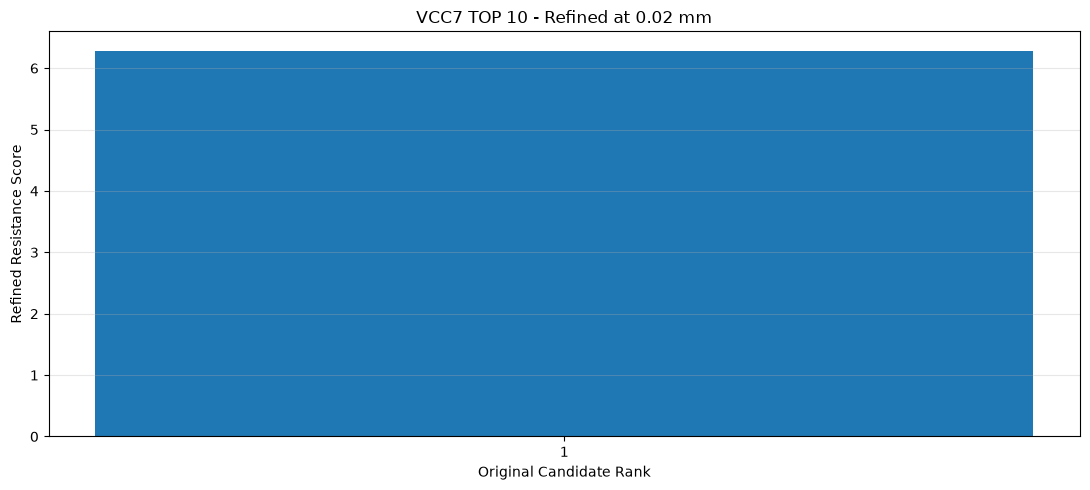

Saved: VCC7_TOP10_refined.csv


In [76]:
# ============================================================
# VCC7 TOP 10 정밀 재분석
# 0.08 mm -> 0.02 mm
# 기존 df_top10, rasterize_tile, analyze_tile 재사용
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 기존 설정 보관
old_grid = GRID_MM
old_tile = TILE_MM
old_halo = HALO_MM
old_min_width = MIN_WIDTH_MM

refined_results = []

try:
    GRID_MM = 0.02
    TILE_MM = 4.0
    HALO_MM = 2.0
    MIN_WIDTH_MM = 0.04

    for row in df_top10.itertuples():

        x = float(row.x_mm)
        y = float(row.y_mm)

        # 후보를 4 x 4 mm 타일의 중앙에 배치
        x0 = x - TILE_MM / 2
        y0 = y - TILE_MM / 2

        candidates = analyze_tile(x0, y0)

        if not candidates:
            refined_results.append({
                "rank": row.rank,
                "x_mm": x,
                "y_mm": y,
                "original_score": row.resistance_score,
                "refined_score": np.nan,
                "refined_min_width_mm": np.nan,
                "status": "No candidate"
            })
            continue

        df_local = pd.DataFrame(candidates)

        # 원래 후보 주변 1 mm 이내에서 탐색
        distances = np.hypot(
            df_local["x_mm"] - x,
            df_local["y_mm"] - y
        )

        nearby = df_local[distances <= 1.0]

        if nearby.empty:
            refined_results.append({
                "rank": row.rank,
                "x_mm": x,
                "y_mm": y,
                "original_score": row.resistance_score,
                "refined_score": np.nan,
                "refined_min_width_mm": np.nan,
                "status": "No nearby window"
            })
            continue

        best = nearby.loc[
            nearby["resistance_score"].idxmax()
        ]

        refined_results.append({
            "rank": row.rank,
            "x_mm": best["x_mm"],
            "y_mm": best["y_mm"],
            "original_score": row.resistance_score,
            "refined_score": best["resistance_score"],
            "refined_min_width_mm": best["min_width_mm"],
            "status": "OK"
        })

finally:
    # 원래 분석 설정 복원
    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo
    MIN_WIDTH_MM = old_min_width

df_refined = pd.DataFrame(refined_results)

df_refined = df_refined.sort_values(
    "refined_score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

df_refined.insert(
    0,
    "refined_rank",
    np.arange(1, len(df_refined) + 1)
)

print("=== VCC7 TOP 10 정밀 재분석 결과 ===")
display(df_refined.round(4))

# 정밀 점수 그래프
valid = df_refined.dropna(subset=["refined_score"])

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    valid["rank"].astype(str),
    valid["refined_score"]
)

ax.set_xlabel("Original Candidate Rank")
ax.set_ylabel("Refined Resistance Score")
ax.set_title("VCC7 TOP 10 - Refined at 0.02 mm")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

df_refined.to_csv(
    "VCC7_TOP10_refined.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved: VCC7_TOP10_refined.csv")

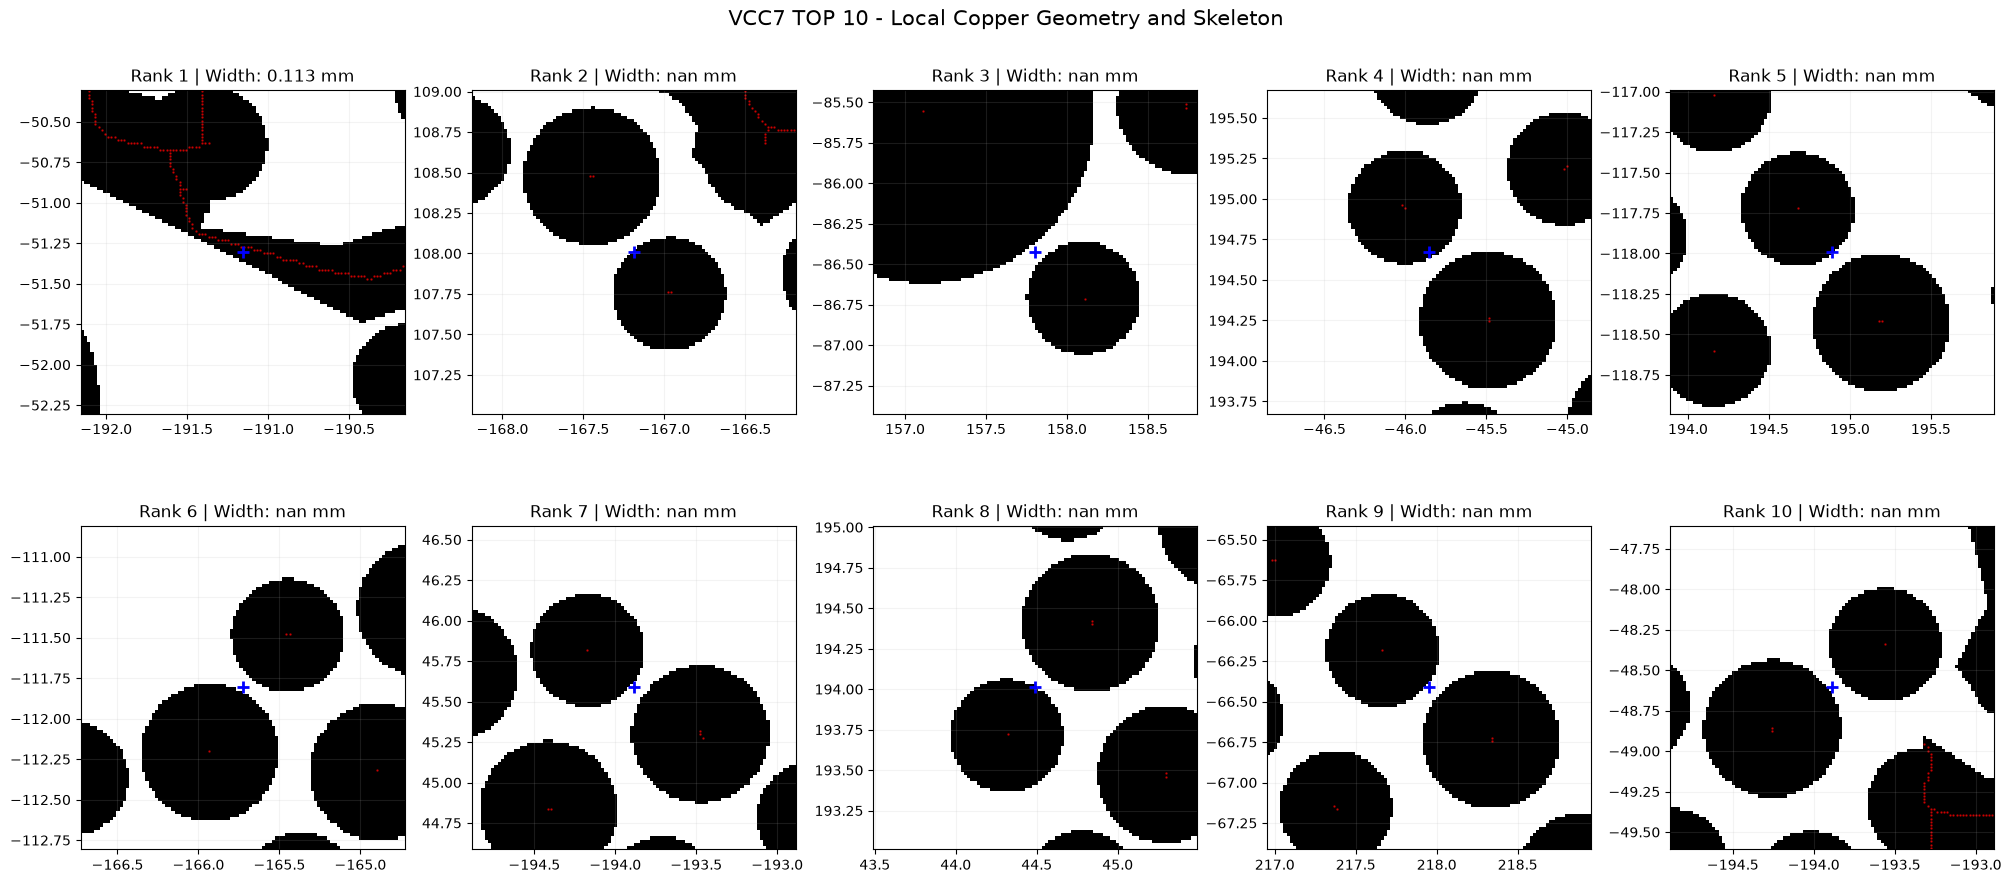

=== TOP 10 Local Geometry Diagnostics ===


,rank,x_mm,y_mm,center_is_copper,local_min_width_mm,local_components,skeleton_pixels_nearby
0,1,-191.1573,-51.3027,True,0.1131,6,19
1,2,-167.1904,108.0104,False,NaN,9,0
2,3,157.8036,-86.4236,False,NaN,7,0
3,4,-45.8538,194.6738,True,NaN,13,0
4,5,194.8896,-117.9896,True,NaN,15,0
5,6,-165.7270,-111.8070,False,NaN,14,0
6,7,-193.8870,45.5870,False,NaN,11,0
7,8,44.4904,194.0104,True,NaN,15,0
8,9,217.9530,-66.4130,False,NaN,12,0
9,10,-193.8870,-48.6070,False,NaN,9,0


In [77]:
# ============================================================
# VCC7 TOP 10 국부 형상 진단
# 기존 df_top10, rasterize_tile 함수 사용
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import distance_transform_edt, label
from skimage.morphology import skeletonize

# 설정 보관
_old_grid = GRID_MM
_old_tile = TILE_MM
_old_halo = HALO_MM

diagnostics = []

try:
    GRID_MM = 0.02
    TILE_MM = 2.0
    HALO_MM = 1.0

    fig, axes = plt.subplots(
        2, 5,
        figsize=(20, 9),
        constrained_layout=True
    )

    for idx, row in enumerate(df_top10.itertuples()):

        ax = axes.flat[idx]

        x = float(row.x_mm)
        y = float(row.y_mm)

        mask, xs, ys = rasterize_tile(
            x - TILE_MM / 2,
            y - TILE_MM / 2
        )

        distance = distance_transform_edt(mask) * GRID_MM
        skel = skeletonize(mask)

        # 후보 주변 0.2 mm 안의 Skeleton 폭
        XX, YY = np.meshgrid(xs, ys)

        near = (
            (XX - x)**2 + (YY - y)**2 <= 0.2**2
        )

        near_skel = skel & near

        local_widths = 2 * distance[near_skel]

        min_width = (
            float(local_widths.min())
            if local_widths.size
            else np.nan
        )

        # 중심점이 구리 내부인지 확인
        ix = np.argmin(np.abs(xs - x))
        iy = np.argmin(np.abs(ys - y))

        center_is_copper = bool(mask[iy, ix])

        # 중심점 주변 구리 연결 성분 개수
        components, count = label(
            mask,
            structure=np.ones((3, 3), dtype=int)
        )

        diagnostics.append({
            "rank": int(row.rank),
            "x_mm": x,
            "y_mm": y,
            "center_is_copper": center_is_copper,
            "local_min_width_mm": min_width,
            "local_components": int(count),
            "skeleton_pixels_nearby": int(near_skel.sum())
        })

        # 구리 형상 표시
        ax.imshow(
            mask,
            extent=[
                xs[0] - GRID_MM/2,
                xs[-1] + GRID_MM/2,
                ys[0] - GRID_MM/2,
                ys[-1] + GRID_MM/2
            ],
            origin="lower",
            cmap="Greys",
            interpolation="nearest"
        )

        # Skeleton 표시
        sy, sx = np.where(skel)

        ax.scatter(
            xs[sx],
            ys[sy],
            s=0.5,
            c="red",
            alpha=0.65
        )

        # 기존 후보 위치
        ax.scatter(
            [x], [y],
            s=80,
            marker="+",
            c="blue",
            linewidths=2
        )

        ax.set_xlim(x - 1.0, x + 1.0)
        ax.set_ylim(y - 1.0, y + 1.0)
        ax.set_aspect("equal")

        ax.set_title(
            f"Rank {int(row.rank)} | "
            f"Width: {min_width:.3f} mm"
        )

        ax.grid(alpha=0.15)

    plt.suptitle(
        "VCC7 TOP 10 - Local Copper Geometry and Skeleton",
        fontsize=15
    )

    plt.savefig(
        "VCC7_TOP10_local_diagnostics.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

finally:
    GRID_MM = _old_grid
    TILE_MM = _old_tile
    HALO_MM = _old_halo

import pandas as pd

df_diagnostics = pd.DataFrame(diagnostics)

print("=== TOP 10 Local Geometry Diagnostics ===")
display(df_diagnostics.round(4))

df_diagnostics.to_csv(
    "VCC7_TOP10_local_diagnostics.csv",
    index=False,
    encoding="utf-8-sig"
)

In [78]:
# ============================================================
# VCC7 기존 TOP 10 후보 유효성 평가
# Notebook 마지막 셀에서 실행
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_validation = df_top10.merge(
    df_diagnostics[
        [
            "rank",
            "center_is_copper",
            "local_min_width_mm",
            "skeleton_pixels_nearby"
        ]
    ],
    on="rank",
    how="left"
)

# 유효 후보 조건:
# 1. 중심점이 구리 내부
# 2. 주변에 Skeleton 존재
# 3. 측정된 구리 폭 존재

df_validation["valid_geometry"] = (
    df_validation["center_is_copper"].fillna(False)
    & (df_validation["skeleton_pixels_nearby"] > 0)
    & df_validation["local_min_width_mm"].notna()
)

df_validation["status"] = np.where(
    df_validation["valid_geometry"],
    "추가 정밀 검증 대상",
    "기존 순위에서 제외"
)

columns = [
    "rank",
    "x_mm",
    "y_mm",
    "resistance_score",
    "local_min_width_mm",
    "center_is_copper",
    "skeleton_pixels_nearby",
    "status"
]

print("=== VCC7 기존 TOP 10 유효성 평가 ===")
display(df_validation[columns].round(4))

print("\n추가 검증 대상:")
display(
    df_validation.loc[
        df_validation["valid_geometry"],
        columns
    ].round(4)
)

print(
    "\n추가 검증 대상 수:",
    int(df_validation["valid_geometry"].sum())
)

df_validation.to_csv(
    "VCC7_TOP10_geometry_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

=== VCC7 기존 TOP 10 유효성 평가 ===


,rank,x_mm,y_mm,resistance_score,local_min_width_mm,center_is_copper,skeleton_pixels_nearby,status
0,1,-191.1573,-51.3027,4.5278,0.1131,True,19,추가 정밀 검증 대상
1,2,-167.1904,108.0104,3.2283,NaN,False,0,기존 순위에서 제외
2,3,157.8036,-86.4236,3.1488,NaN,False,0,기존 순위에서 제외
3,4,-45.8538,194.6738,3.1222,NaN,True,0,기존 순위에서 제외
4,5,194.8896,-117.9896,3.0836,NaN,True,0,기존 순위에서 제외
5,6,-165.7270,-111.8070,2.9789,NaN,False,0,기존 순위에서 제외
6,7,-193.8870,45.5870,2.9745,NaN,False,0,기존 순위에서 제외
7,8,44.4904,194.0104,2.9723,NaN,True,0,기존 순위에서 제외
8,9,217.9530,-66.4130,2.9721,NaN,False,0,기존 순위에서 제외
9,10,-193.8870,-48.6070,2.9636,NaN,False,0,기존 순위에서 제외



추가 검증 대상:


,rank,x_mm,y_mm,resistance_score,local_min_width_mm,center_is_copper,skeleton_pixels_nearby,status
0,1,-191.1573,-51.3027,4.5278,0.1131,True,19,추가 정밀 검증 대상



추가 검증 대상 수: 1


검증 대상: 1500
Accepted 1/10: (-191.157, -51.303) mm | width=0.1649 mm | score=4.5278
Accepted 2/10: (-37.109, -190.390) mm | width=0.3441 mm | score=2.8075
Accepted 3/10: (-26.847, 187.907) mm | width=0.3124 mm | score=2.7891
Accepted 4/10: (78.343, -168.870) mm | width=0.3298 mm | score=2.5925
Accepted 5/10: (176.433, -55.887) mm | width=0.3688 mm | score=2.5732
Accepted 6/10: (42.787, -197.087) mm | width=0.3774 mm | score=2.5544
Accepted 7/10: (-96.254, 160.274) mm | width=0.4118 mm | score=2.3662
Accepted 8/10: (-64.493, -139.453) mm | width=0.5091 mm | score=2.2505
Accepted 9/10: (-45.773, -124.687) mm | width=0.5091 mm | score=2.2505
Accepted 10/10: (-46.093, -65.053) mm | width=0.5091 mm | score=2.2505

=== VCC7 High-Resolution Geometry-Validated Candidates ===
Checked: 24
Accepted: 10
Rejections: {'Outside copper': 8, 'Far from skeleton': 6}


,rank,x_mm,y_mm,skeleton_x_mm,skeleton_y_mm,coarse_score,width_at_skeleton_mm,nearby_min_width_mm,nearby_mean_width_mm,component_span_x_mm,component_span_y_mm,distance_to_skeleton_mm
0,1,-191.1573,-51.3027,-191.1673,-51.2727,4.5278,0.1649,0.1131,0.1611,4.98,2.92,0.0316
1,2,-37.1094,-190.3900,-37.0994,-190.4200,2.8075,0.3441,0.3225,0.3344,3.92,3.44,0.0316
2,3,-26.8470,187.9070,-26.8370,187.9170,2.7891,0.3124,0.2884,0.3071,3.40,3.62,0.0141
3,4,78.3431,-168.8700,78.3531,-168.8800,2.5925,0.3298,0.3298,0.3374,4.66,2.82,0.0141
4,5,176.4330,-55.8870,176.4230,-55.8970,2.5732,0.3688,0.3578,0.3660,4.08,3.22,0.0141
5,6,42.7870,-197.0870,42.8170,-197.0770,2.5544,0.3774,0.3578,0.3698,4.12,3.34,0.0316
6,7,-96.2538,160.2738,-96.2238,160.2838,2.3662,0.4118,0.3940,0.4063,4.60,3.10,0.0316
7,8,-64.4930,-139.4530,-64.4830,-139.4830,2.2505,0.5091,0.5091,0.5091,4.98,4.98,0.0316
8,9,-45.7730,-124.6870,-45.8030,-124.6970,2.2505,0.5091,0.5091,0.5091,3.24,4.98,0.0316
9,10,-46.0930,-65.0530,-46.0630,-65.0630,2.2505,0.5091,0.5091,0.5091,4.98,4.98,0.0316


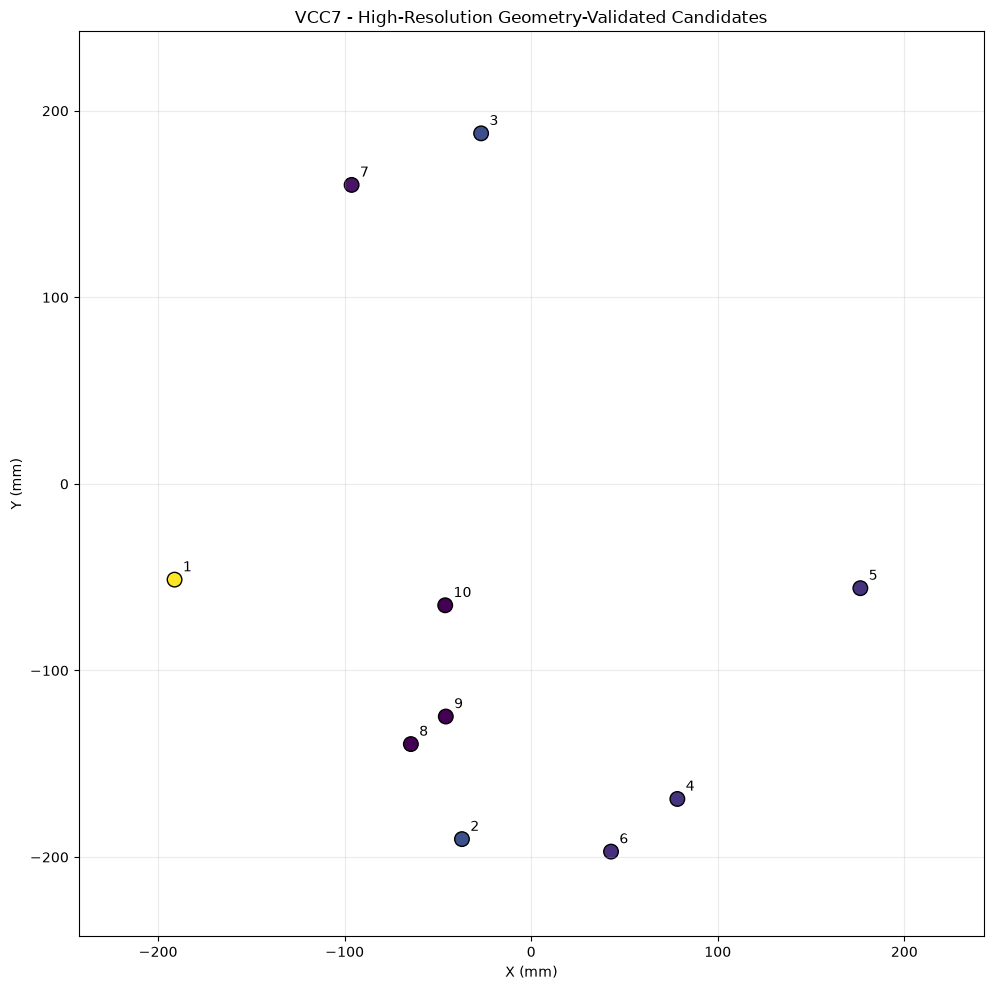

In [79]:
# ============================================================
# VCC7 전체 후보 재검증
# 기존 df_all 활용 / 0.02 mm 고해상도
# 기존 순위와 구별되는 검증 후보 TOP 10 생성
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import distance_transform_edt, label
from scipy.spatial import cKDTree
from skimage.morphology import skeletonize

TOP_N = 10
MAX_CHECK = 1500
SEPARATION_MM = 2.0
NEAR_SKELETON_MM = 0.15

# 기존 설정 저장
saved_settings = {
    "GRID_MM": GRID_MM,
    "TILE_MM": TILE_MM,
    "HALO_MM": HALO_MM
}

validated = []
checked = 0
rejection_counts = {}

try:
    GRID_MM = 0.02
    TILE_MM = 2.0
    HALO_MM = 1.5

    candidates = df_all.sort_values(
        "resistance_score",
        ascending=False
    ).reset_index(drop=True)

    # 같은 위치에 몰린 후보는 미리 제거
    preselected = []
    preselected_xy = []

    for row in candidates.itertuples():
        xy = np.array([row.x_mm, row.y_mm])

        if preselected_xy:
            distances = np.linalg.norm(
                np.asarray(preselected_xy) - xy,
                axis=1
            )
            if distances.min() < SEPARATION_MM:
                continue

        preselected.append(row)
        preselected_xy.append(xy)

        if len(preselected) >= MAX_CHECK:
            break

    print("검증 대상:", len(preselected))

    for row in preselected:
        checked += 1

        x = float(row.x_mm)
        y = float(row.y_mm)

        mask, xs, ys = rasterize_tile(
            x - TILE_MM / 2,
            y - TILE_MM / 2
        )

        ix = np.argmin(np.abs(xs - x))
        iy = np.argmin(np.abs(ys - y))

        if not mask[iy, ix]:
            reason = "Outside copper"
            rejection_counts[reason] = (
                rejection_counts.get(reason, 0) + 1
            )
            continue

        dist = distance_transform_edt(mask) * GRID_MM
        skel = skeletonize(mask)

        sy, sx = np.where(skel)

        if len(sx) == 0:
            reason = "No skeleton"
            rejection_counts[reason] = (
                rejection_counts.get(reason, 0) + 1
            )
            continue

        skel_coords = np.column_stack([
            xs[sx], ys[sy]
        ])

        tree = cKDTree(skel_coords)

        nearest_dist, nearest_idx = tree.query([x, y])

        if nearest_dist > NEAR_SKELETON_MM:
            reason = "Far from skeleton"
            rejection_counts[reason] = (
                rejection_counts.get(reason, 0) + 1
            )
            continue

        py = sy[nearest_idx]
        px = sx[nearest_idx]

        # Skeleton이 속한 구리 연결 성분 확인
        components, _ = label(
            mask,
            structure=np.ones((3, 3), dtype=int)
        )

        component_id = components[py, px]

        if component_id == 0:
            continue

        component_mask = components == component_id

        cy, cx = np.where(component_mask)

        # 고립된 작은 구리 패턴 제외:
        # 연결 성분의 공간적 크기가 1 mm 이상이어야 함
        span_x = (cx.max() - cx.min()) * GRID_MM
        span_y = (cy.max() - cy.min()) * GRID_MM

        if np.hypot(span_x, span_y) < 1.0:
            reason = "Small isolated component"
            rejection_counts[reason] = (
                rejection_counts.get(reason, 0) + 1
            )
            continue

        # 실제 고해상도 중심선 폭
        width = float(2 * dist[py, px])

        # 주변 0.2 mm 이내 중심선 폭의 분포
        local_distance = np.linalg.norm(
            skel_coords - skel_coords[nearest_idx],
            axis=1
        )

        nearby = local_distance <= 0.2

        nearby_widths = (
            2 * dist[sy[nearby], sx[nearby]]
        )

        validated.append({
            "rank": len(validated) + 1,
            "x_mm": x,
            "y_mm": y,
            "skeleton_x_mm": float(xs[px]),
            "skeleton_y_mm": float(ys[py]),
            "coarse_score": float(row.resistance_score),
            "width_at_skeleton_mm": width,
            "nearby_min_width_mm": float(
                nearby_widths.min()
            ),
            "nearby_mean_width_mm": float(
                nearby_widths.mean()
            ),
            "component_span_x_mm": float(span_x),
            "component_span_y_mm": float(span_y),
            "distance_to_skeleton_mm": float(nearest_dist)
        })

        print(
            f"Accepted {len(validated)}/{TOP_N}: "
            f"({x:.3f}, {y:.3f}) mm | "
            f"width={width:.4f} mm | "
            f"score={row.resistance_score:.4f}"
        )

        if len(validated) >= TOP_N:
            break

finally:
    GRID_MM = saved_settings["GRID_MM"]
    TILE_MM = saved_settings["TILE_MM"]
    HALO_MM = saved_settings["HALO_MM"]

df_validated_top10 = pd.DataFrame(validated)

print("\n=== VCC7 High-Resolution Geometry-Validated Candidates ===")
print("Checked:", checked)
print("Accepted:", len(df_validated_top10))
print("Rejections:", rejection_counts)

display(df_validated_top10.round(4))

if not df_validated_top10.empty:

    df_validated_top10.to_csv(
        "VCC7_validated_candidates.csv",
        index=False,
        encoding="utf-8-sig"
    )

    fig, ax = plt.subplots(figsize=(11, 10))

    ax.scatter(
        df_validated_top10["x_mm"],
        df_validated_top10["y_mm"],
        c=df_validated_top10["coarse_score"],
        cmap="viridis",
        s=110,
        edgecolors="black"
    )

    for row in df_validated_top10.itertuples():
        ax.annotate(
            str(row.rank),
            (row.x_mm, row.y_mm),
            xytext=(6, 6),
            textcoords="offset points"
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.set_title(
        "VCC7 - High-Resolution Geometry-Validated Candidates"
    )
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

Candidate 1: score=6.2785, min_width=0.0800 mm
Candidate 2: score=2.9899, min_width=0.3200 mm
Candidate 3: score=3.2327, min_width=0.2800 mm
Candidate 4: score=2.7667, min_width=0.3200 mm
Candidate 5: score=2.7386, min_width=0.3441 mm
Candidate 6: score=2.7052, min_width=0.3298 mm
Candidate 7: score=2.4877, min_width=0.3418 mm
Candidate 8: score=1.9661, min_width=0.4665 mm
Candidate 9: score=2.0066, min_width=0.4308 mm
Candidate 10: score=1.9922, min_width=0.4308 mm

=== VCC7 0.02 mm Refined Resistance Results ===


,refined_rank,original_rank,x_mm,y_mm,coarse_score,refined_score,min_width_mm,effective_width_mm,status
0,1,1,-191.1673,-51.2727,4.5278,6.2785,0.0800,0.1593,OK
1,2,3,-26.8370,187.9170,2.7891,3.2327,0.2800,0.3093,OK
2,3,2,-37.0994,-190.4200,2.8075,2.9899,0.3200,0.3345,OK
3,4,4,78.3531,-168.8800,2.5925,2.7667,0.3200,0.3614,OK
4,5,5,176.4230,-55.8970,2.5732,2.7386,0.3441,0.3651,OK
5,6,6,42.8170,-197.0770,2.5544,2.7052,0.3298,0.3697,OK
6,7,7,-96.2238,160.2838,2.3662,2.4877,0.3418,0.4020,OK
7,8,9,-45.8030,-124.6970,2.2505,2.0066,0.4308,0.4983,OK
8,9,10,-46.0630,-65.0630,2.2505,1.9922,0.4308,0.5020,OK
9,10,8,-64.4830,-139.4830,2.2505,1.9661,0.4665,0.5086,OK


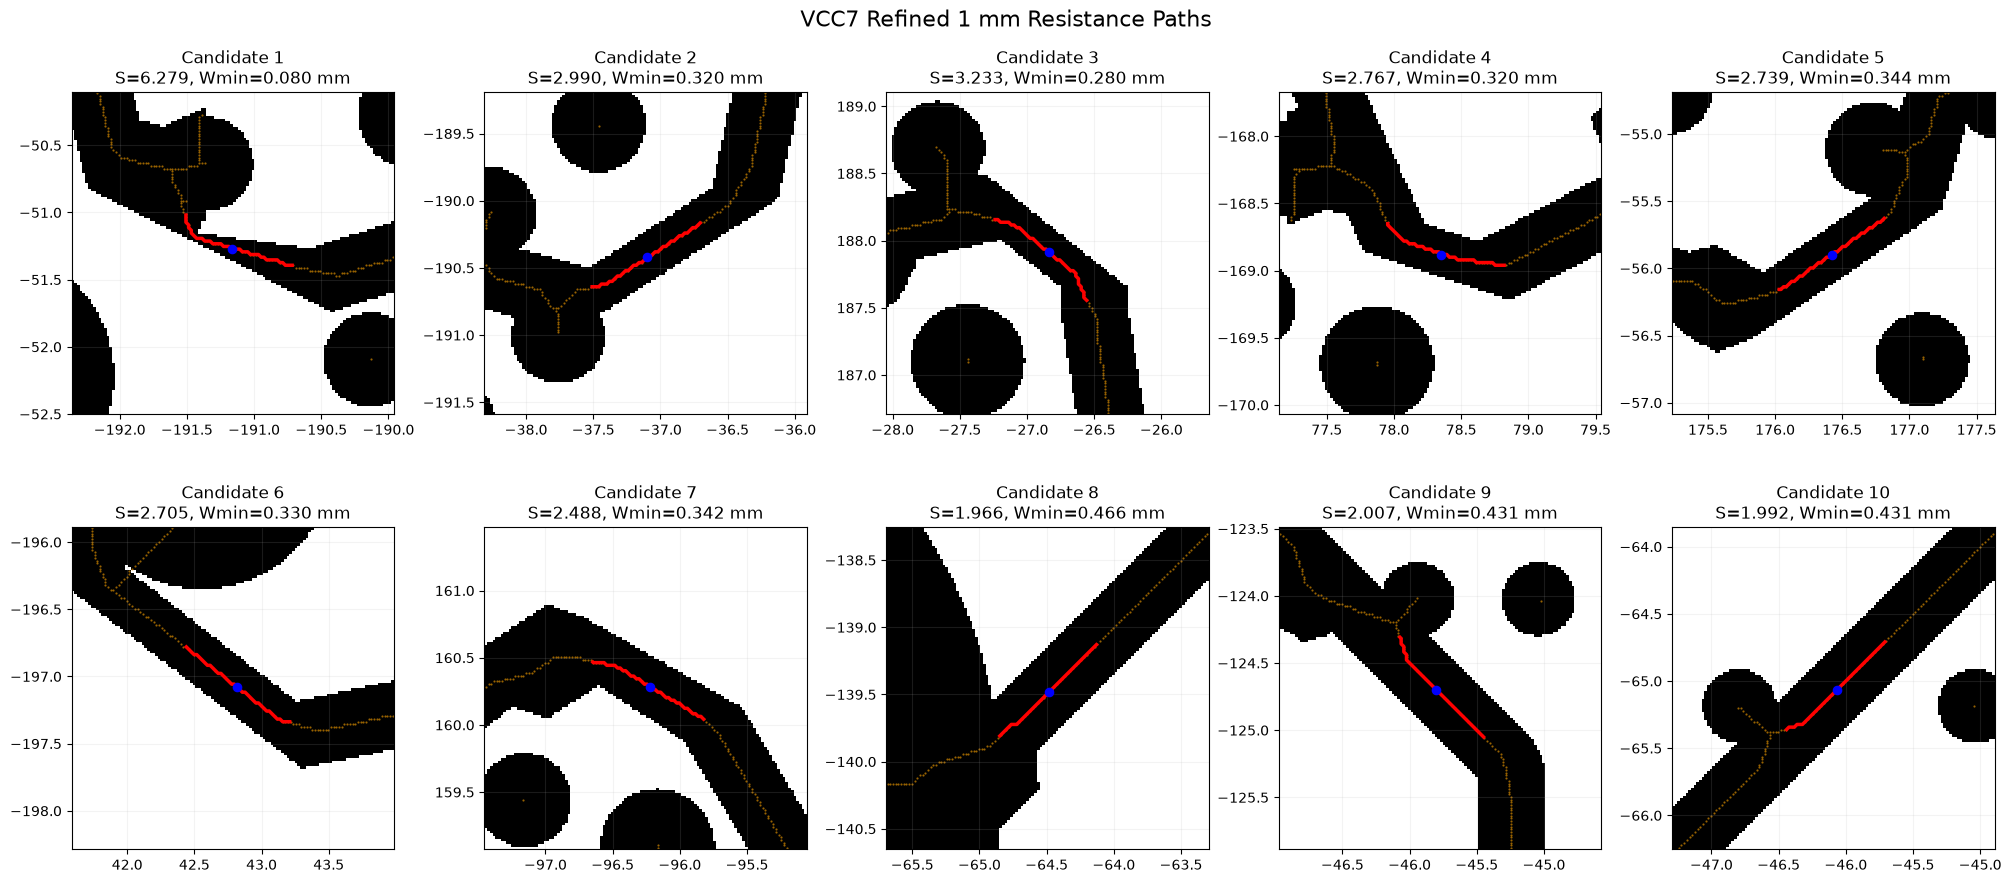

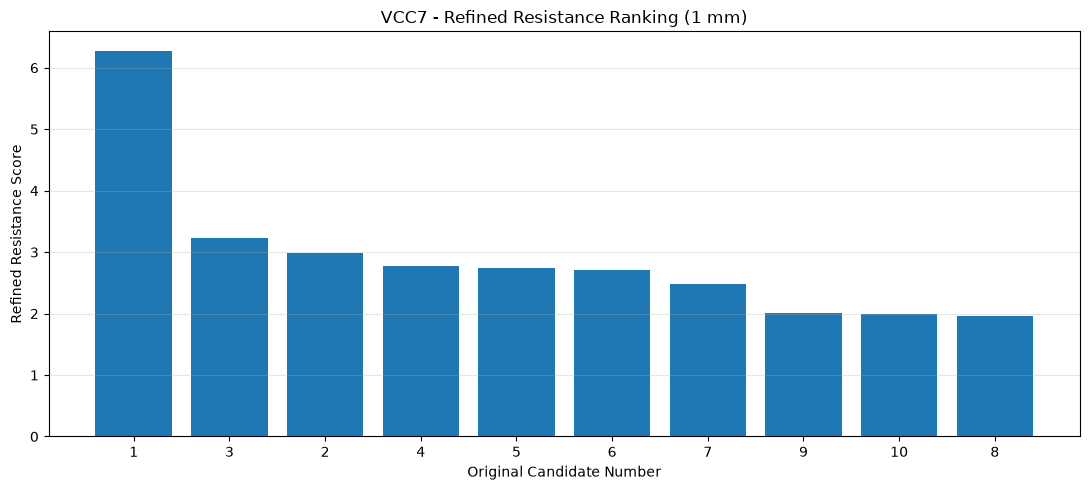


Saved:
VCC7_TOP10_refined_resistance.csv
VCC7_refined_1mm_paths.png
VCC7_refined_resistance_ranking.png


In [80]:
# ============================================================
# VCC7 검증 후보 10개 - 0.02 mm 정밀 저항 재계산
# 분기점 통과 허용 / 1 mm 중심선 경로 분석
# 한 셀에서 전체 실행
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.ndimage import distance_transform_edt, label
from scipy.spatial import cKDTree
from skimage.morphology import skeletonize

# ------------------------------------------------------------
# 1. 설정
# ------------------------------------------------------------

FINE_GRID = 0.02
LOCAL_TILE = 3.0
LOCAL_HALO = 1.5

PATH_LENGTH = 1.0
HALF_LENGTH = PATH_LENGTH / 2

# 양쪽 경로가 반대 방향으로 뻗어야 함
MAX_DIRECTION_DOT = -0.35

# 1 mm 구간이 너무 심하게 돌아가는 경로 제외
MIN_ENDPOINT_DISTANCE = 0.60

# 원래 후보와 Skeleton 사이 최대 허용 거리
MAX_ANCHOR_DISTANCE = 0.15

# 결과 및 시각화용
results = []
plot_data = []

old_grid = GRID_MM
old_tile = TILE_MM
old_halo = HALO_MM

# ------------------------------------------------------------
# 2. Skeleton 그래프 생성
# ------------------------------------------------------------

def build_skeleton_graph(skel, dist, xs, ys, grid):

    G = nx.Graph()

    py, px = np.where(skel)

    pixels = set(zip(py, px))

    directions = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    for y, x in pixels:

        G.add_node(
            (y, x),
            pos=(float(xs[x]), float(ys[y])),
            width=float(2 * dist[y, x])
        )

    for y, x in pixels:

        for dy, dx in directions:

            q = (y + dy, x + dx)

            if q not in pixels:
                continue

            if q <= (y, x):
                continue

            length = grid * np.hypot(dx, dy)

            w1 = max(2 * dist[y, x], grid)
            w2 = max(2 * dist[q], grid)

            mean_w = (w1 + w2) / 2

            G.add_edge(
                (y, x),
                q,
                length=length,
                resistance=length / mean_w
            )

    return G


# ------------------------------------------------------------
# 3. 경로 길이 및 저항 계산
# ------------------------------------------------------------

def integrate_path(G, path, target_length):

    total_length = 0.0
    total_score = 0.0

    min_width = np.inf
    max_width = 0.0

    sampled_coords = []

    if not path:
        return None

    sampled_coords.append(G.nodes[path[0]]["pos"])

    for a, b in zip(path[:-1], path[1:]):

        edge = G[a][b]

        ds = edge["length"]
        dR = edge["resistance"]

        remaining = target_length - total_length

        if remaining <= 0:
            break

        fraction = min(1.0, remaining / ds)

        total_length += ds * fraction
        total_score += dR * fraction

        wa = G.nodes[a]["width"]
        wb = G.nodes[b]["width"]

        min_width = min(min_width, wa, wb)
        max_width = max(max_width, wa, wb)

        pa = np.array(G.nodes[a]["pos"])
        pb = np.array(G.nodes[b]["pos"])

        point = pa + fraction * (pb - pa)

        sampled_coords.append(tuple(point))

        if fraction < 1:
            break

    if total_length < target_length - 1e-6:
        return None

    return {
        "length": total_length,
        "score": total_score,
        "min_width": min_width,
        "max_width": max_width,
        "coords": np.asarray(sampled_coords)
    }


# ------------------------------------------------------------
# 4. 후보 중심 양방향 1 mm 경로 탐색
# ------------------------------------------------------------

def refine_candidate(x, y):

    global GRID_MM, TILE_MM, HALO_MM

    GRID_MM = FINE_GRID
    TILE_MM = LOCAL_TILE
    HALO_MM = LOCAL_HALO

    mask, xs, ys = rasterize_tile(
        x - LOCAL_TILE / 2,
        y - LOCAL_TILE / 2
    )

    if not mask.any():
        return None, (mask, xs, ys, None)

    # 연결 성분을 기준으로 내부 거리 계산
    dist = distance_transform_edt(mask) * FINE_GRID
    skel = skeletonize(mask)

    sy, sx = np.where(skel)

    if len(sx) == 0:
        return None, (mask, xs, ys, skel)

    coords = np.column_stack((xs[sx], ys[sy]))

    tree = cKDTree(coords)

    anchor_dist, anchor_idx = tree.query([x, y])

    if anchor_dist > MAX_ANCHOR_DISTANCE:
        return None, (mask, xs, ys, skel)

    anchor = (
        int(sy[anchor_idx]),
        int(sx[anchor_idx])
    )

    G = build_skeleton_graph(
        skel, dist, xs, ys, FINE_GRID
    )

    if anchor not in G:
        return None, (mask, xs, ys, skel)

    # 후보에서 0.5 mm 이상 도달 가능한 경로 탐색
    # 분기점에서 끊지 않고 그래프 최단경로 사용
    lengths, paths = nx.single_source_dijkstra(
        G,
        anchor,
        cutoff=HALF_LENGTH + 0.12,
        weight="length"
    )

    endpoints = [
        node for node, length in lengths.items()
        if length >= HALF_LENGTH
    ]

    if len(endpoints) < 2:
        return None, (mask, xs, ys, skel)

    anchor_pos = np.array(G.nodes[anchor]["pos"])

    arms = []

    for node in endpoints:

        path = paths[node]

        arm = integrate_path(
            G, path, HALF_LENGTH
        )

        if arm is None:
            continue

        end_pos = arm["coords"][-1]

        vector = end_pos - anchor_pos

        norm = np.linalg.norm(vector)

        if norm < 1e-9:
            continue

        arms.append({
            "node": node,
            "path": path,
            "arm": arm,
            "vector": vector / norm,
            "end": end_pos
        })

    if len(arms) < 2:
        return None, (mask, xs, ys, skel)

    best = None

    # --------------------------------------------------------
    # 양방향 조합 중 저항 점수가 가장 높은 경로 선택
    # --------------------------------------------------------

    for i in range(len(arms)):

        for j in range(i + 1, len(arms)):

            a = arms[i]
            b = arms[j]

            direction_dot = np.dot(
                a["vector"],
                b["vector"]
            )

            if direction_dot > MAX_DIRECTION_DOT:
                continue

            endpoint_distance = np.linalg.norm(
                a["end"] - b["end"]
            )

            if endpoint_distance < MIN_ENDPOINT_DISTANCE:
                continue

            # 두 경로가 중심점 이외의 노드를 공유하면 제외
            nodes_a = set(a["path"][1:])
            nodes_b = set(b["path"][1:])

            if nodes_a & nodes_b:
                continue

            score = (
                a["arm"]["score"] +
                b["arm"]["score"]
            )

            min_width = min(
                a["arm"]["min_width"],
                b["arm"]["min_width"]
            )

            max_width = max(
                a["arm"]["max_width"],
                b["arm"]["max_width"]
            )

            path_coords = np.vstack([
                a["arm"]["coords"][::-1],
                b["arm"]["coords"][1:]
            ])

            candidate = {
                "x_mm": float(anchor_pos[0]),
                "y_mm": float(anchor_pos[1]),
                "refined_score": float(score),
                "min_width_mm": float(min_width),
                "max_width_mm": float(max_width),
                "effective_width_mm": float(
                    PATH_LENGTH / score
                ),
                "path_length_mm": PATH_LENGTH,
                "endpoint_distance_mm": float(
                    endpoint_distance
                ),
                "path_coords": path_coords
            }

            if (
                best is None
                or score > best["refined_score"]
            ):
                best = candidate

    return best, (mask, xs, ys, skel)


# ------------------------------------------------------------
# 5. 검증된 10개 후보 재분석
# ------------------------------------------------------------

try:

    for row in df_validated_top10.itertuples():

        rank = int(row.rank)
        x = float(row.x_mm)
        y = float(row.y_mm)

        refined, image_data = refine_candidate(x, y)

        if refined is None:

            print(
                f"Candidate {rank}: "
                "1 mm 연속 경로 검출 실패"
            )

            results.append({
                "original_rank": rank,
                "x_mm": x,
                "y_mm": y,
                "coarse_score": row.coarse_score,
                "refined_score": np.nan,
                "min_width_mm": np.nan,
                "effective_width_mm": np.nan,
                "status": "No valid 1 mm path"
            })

        else:

            print(
                f"Candidate {rank}: "
                f"score={refined['refined_score']:.4f}, "
                f"min_width={refined['min_width_mm']:.4f} mm"
            )

            results.append({
                "original_rank": rank,
                "x_mm": refined["x_mm"],
                "y_mm": refined["y_mm"],
                "coarse_score": row.coarse_score,
                "refined_score": refined["refined_score"],
                "min_width_mm": refined["min_width_mm"],
                "effective_width_mm":
                    refined["effective_width_mm"],
                "status": "OK"
            })

        plot_data.append({
            "rank": rank,
            "original_x": x,
            "original_y": y,
            "result": refined,
            "image": image_data
        })

finally:

    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo


# ------------------------------------------------------------
# 6. 정밀 점수 기준 재정렬
# ------------------------------------------------------------

df_refined_final = pd.DataFrame(results)

df_refined_final = df_refined_final.sort_values(
    "refined_score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

df_refined_final.insert(
    0,
    "refined_rank",
    np.arange(1, len(df_refined_final) + 1)
)

print("\n=== VCC7 0.02 mm Refined Resistance Results ===")

display(df_refined_final.round(4))

df_refined_final.to_csv(
    "VCC7_TOP10_refined_resistance.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 7. 10개 위치의 실제 경로 시각화
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 5,
    figsize=(20, 9),
    constrained_layout=True
)

for ax, item in zip(axes.flat, plot_data):

    rank = item["rank"]

    x = item["original_x"]
    y = item["original_y"]

    mask, xs, ys, skel = item["image"]

    ax.imshow(
        mask,
        extent=[
            xs[0] - FINE_GRID / 2,
            xs[-1] + FINE_GRID / 2,
            ys[0] - FINE_GRID / 2,
            ys[-1] + FINE_GRID / 2
        ],
        origin="lower",
        cmap="Greys",
        interpolation="nearest"
    )

    if skel is not None:

        sy, sx = np.where(skel)

        ax.scatter(
            xs[sx],
            ys[sy],
            s=0.3,
            c="orange",
            alpha=0.6
        )

    refined = item["result"]

    if refined is not None:

        path = refined["path_coords"]

        ax.plot(
            path[:, 0],
            path[:, 1],
            c="red",
            linewidth=2.5
        )

        ax.scatter(
            [refined["x_mm"]],
            [refined["y_mm"]],
            c="blue",
            s=35,
            zorder=5
        )

        ax.set_title(
            f"Candidate {rank}\n"
            f"S={refined['refined_score']:.3f}, "
            f"Wmin={refined['min_width_mm']:.3f} mm"
        )

    else:

        ax.scatter(
            [x], [y],
            c="blue",
            marker="+",
            s=80
        )

        ax.set_title(
            f"Candidate {rank}\n"
            "No valid 1 mm path"
        )

    ax.set_xlim(x - 1.2, x + 1.2)
    ax.set_ylim(y - 1.2, y + 1.2)

    ax.set_aspect("equal")
    ax.grid(alpha=0.15)

plt.suptitle(
    "VCC7 Refined 1 mm Resistance Paths",
    fontsize=16
)

plt.savefig(
    "VCC7_refined_1mm_paths.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. 정밀 저항 순위 그래프
# ------------------------------------------------------------

valid = df_refined_final[
    df_refined_final["status"] == "OK"
]

if not valid.empty:

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.bar(
        valid["original_rank"].astype(str),
        valid["refined_score"]
    )

    ax.set_xlabel("Original Candidate Number")
    ax.set_ylabel("Refined Resistance Score")
    ax.set_title(
        "VCC7 - Refined Resistance Ranking (1 mm)"
    )

    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        "VCC7_refined_resistance_ranking.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

print("\nSaved:")
print("VCC7_TOP10_refined_resistance.csv")
print("VCC7_refined_1mm_paths.png")
print("VCC7_refined_resistance_ranking.png")

Original candidates: 145605
Preselected locations: 20424
100/20424 | valid=86 | rejected=14 | elapsed=697.4s
200/20424 | valid=186 | rejected=14 | elapsed=701.7s
300/20424 | valid=286 | rejected=14 | elapsed=706.3s
400/20424 | valid=386 | rejected=14 | elapsed=710.7s
500/20424 | valid=486 | rejected=14 | elapsed=715.0s
600/20424 | valid=586 | rejected=14 | elapsed=719.2s
700/20424 | valid=686 | rejected=14 | elapsed=723.9s
800/20424 | valid=786 | rejected=14 | elapsed=728.1s
900/20424 | valid=886 | rejected=14 | elapsed=732.3s
1000/20424 | valid=986 | rejected=14 | elapsed=736.7s
1100/20424 | valid=1086 | rejected=14 | elapsed=740.9s
1200/20424 | valid=1186 | rejected=14 | elapsed=745.0s
1300/20424 | valid=1286 | rejected=14 | elapsed=749.1s
1400/20424 | valid=1386 | rejected=14 | elapsed=753.7s
1500/20424 | valid=1486 | rejected=14 | elapsed=757.9s
1600/20424 | valid=1586 | rejected=14 | elapsed=762.0s
1700/20424 | valid=1686 | rejected=14 | elapsed=765.9s
1800/20424 | valid=1786 | re

,rank,Index,x_mm,y_mm,refined_score,min_width_mm,effective_width_mm,endpoint_distance_mm,coarse_score
0,1,0,-191.1673,-51.2727,6.2785,0.0800,0.1593,0.8742,4.5278
1,2,1,226.9731,-44.4600,3.6138,0.0400,0.2767,0.7802,1.9751
2,3,2,-26.8370,187.9170,3.2327,0.2800,0.3093,0.9079,2.7891
3,4,3,-37.0994,-190.4200,2.9899,0.3200,0.3345,0.9331,2.8075
4,5,5,78.3531,-168.8800,2.7667,0.3200,0.3614,0.9202,2.5925
5,6,6,176.4230,-55.8970,2.7386,0.3441,0.3651,0.9431,2.5732
6,7,7,42.8170,-197.0770,2.7052,0.3298,0.3697,0.9498,2.5544
7,8,9,-96.2238,160.2838,2.4877,0.3418,0.4020,0.9270,2.3662
8,9,12,-193.0600,-49.4000,2.4581,0.1265,0.4068,0.7306,1.9060
9,10,13,51.4200,-176.9137,2.3806,0.3046,0.4201,0.9057,2.1394


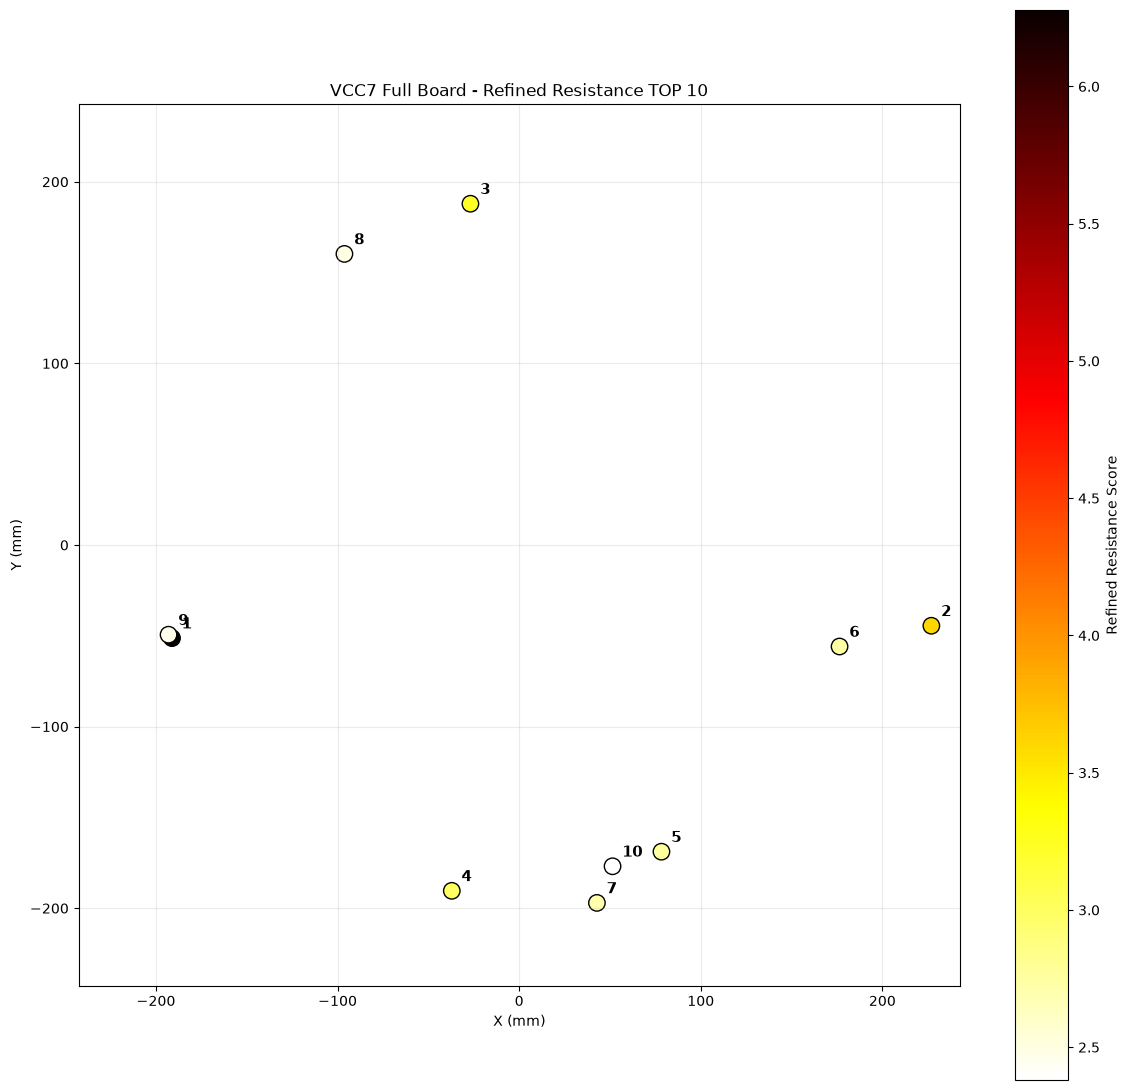

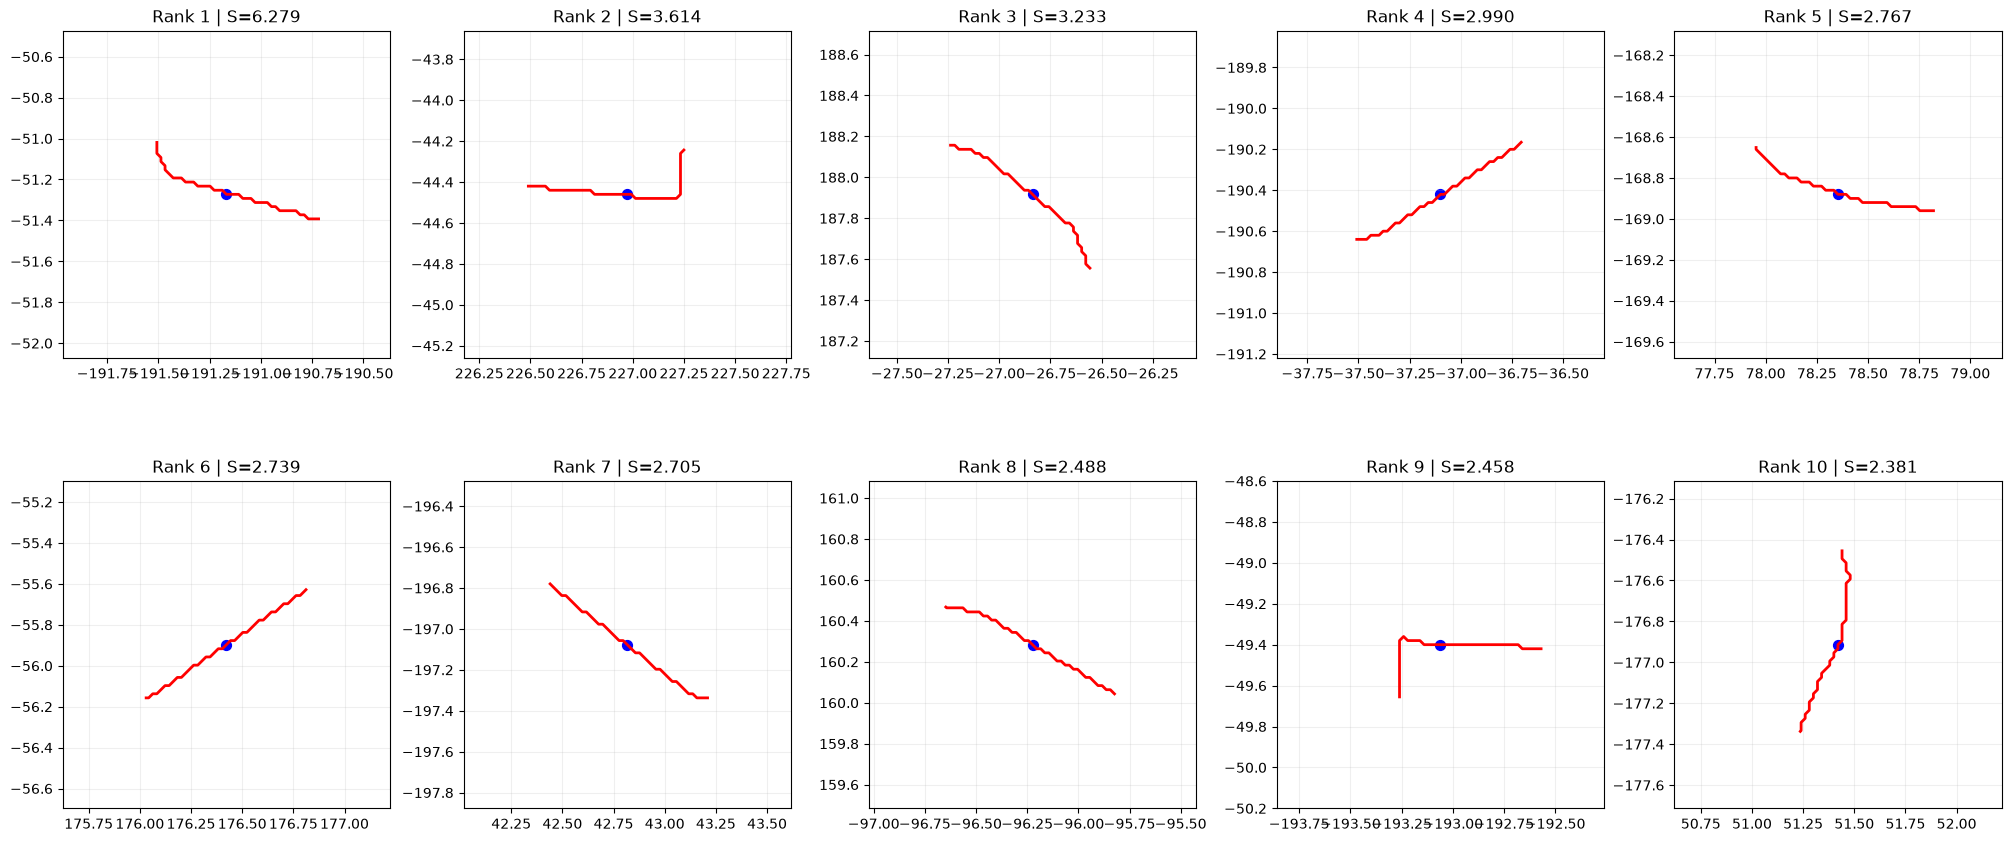


=== FINISHED ===
Refined valid candidates: 20272
Elapsed: 1583.5 seconds
Saved: VCC7_FINAL_TOP10.csv
Saved: VCC7_ALL_REFINED_RESULTS.csv
Saved: VCC7_FINAL_TOP10_MAP.png
Saved: VCC7_FINAL_TOP10_PATHS.png


In [81]:
# ============================================================
# VCC7 FULL BOARD - FINAL TOP 10 SEARCH
# 0.02 mm 정밀 검증 + 1 mm 연속 경로 저항 적분
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.ndimage import distance_transform_edt
from scipy.spatial import cKDTree
from skimage.morphology import skeletonize
from functools import lru_cache
import time

# ------------------------------------------------------------
# 1. 설정
# ------------------------------------------------------------

FINE_GRID = 0.02
LOCAL_TILE = 3.0
LOCAL_HALO = 1.5
PATH_LENGTH = 1.0
HALF_LENGTH = 0.5

TOP_N = 10
MAX_CHECK = None           # None = 전체 후보 검사
PRESELECT_DISTANCE = 0.5  # mm, 중복 후보 사전 제거
FINAL_DISTANCE = 2.0      # mm, 최종 위치 중복 방지

MAX_ANCHOR_DISTANCE = 0.12
MAX_DIRECTION_DOT = -0.35
MIN_ENDPOINT_DISTANCE = 0.60

# 같은 위치에 대한 불필요한 반복 계산 방지
CACHE_ROUND_MM = 0.5

start_time = time.time()

old_grid = GRID_MM
old_tile = TILE_MM
old_halo = HALO_MM

# ------------------------------------------------------------
# 2. 전체 후보 사전 정리
# ------------------------------------------------------------

df_candidates = df_all.sort_values(
    "resistance_score",
    ascending=False
).reset_index(drop=True)

# KDTree 기반 공간 중복 제거
preselected = []
preselected_xy = []

for row in df_candidates.itertuples():

    xy = np.array([row.x_mm, row.y_mm])

    if preselected_xy:
        tree = cKDTree(np.asarray(preselected_xy))
        dist, _ = tree.query(xy)

        if dist < PRESELECT_DISTANCE:
            continue

    preselected.append(row)
    preselected_xy.append(xy)

    if MAX_CHECK is not None and len(preselected) >= MAX_CHECK:
        break

print("Original candidates:", len(df_candidates))
print("Preselected locations:", len(preselected))

# ------------------------------------------------------------
# 3. 고해상도 후보 검증 및 경로 저항 계산
# ------------------------------------------------------------

def analyze_candidate(x, y):

    global GRID_MM, TILE_MM, HALO_MM

    GRID_MM = FINE_GRID
    TILE_MM = LOCAL_TILE
    HALO_MM = LOCAL_HALO

    mask, xs, ys = rasterize_tile(
        x - LOCAL_TILE / 2,
        y - LOCAL_TILE / 2
    )

    if not mask.any():
        return None

    # 후보 중심이 실제 구리 영역인지 확인
    ix = np.argmin(np.abs(xs - x))
    iy = np.argmin(np.abs(ys - y))

    if not mask[iy, ix]:
        return None

    dist = distance_transform_edt(mask) * FINE_GRID
    skel = skeletonize(mask)

    sy, sx = np.where(skel)

    if len(sx) == 0:
        return None

    skel_coords = np.column_stack([xs[sx], ys[sy]])

    tree = cKDTree(skel_coords)

    anchor_dist, anchor_idx = tree.query([x, y])

    if anchor_dist > MAX_ANCHOR_DISTANCE:
        return None

    anchor = (
        int(sy[anchor_idx]),
        int(sx[anchor_idx])
    )

    G = build_skeleton_graph(
        skel, dist, xs, ys, FINE_GRID
    )

    if anchor not in G:
        return None

    lengths, paths = nx.single_source_dijkstra(
        G,
        anchor,
        cutoff=HALF_LENGTH + 0.12,
        weight="length"
    )

    endpoints = [
        node for node, length in lengths.items()
        if length >= HALF_LENGTH
    ]

    if len(endpoints) < 2:
        return None

    anchor_pos = np.array(G.nodes[anchor]["pos"])

    arms = []

    for node in endpoints:

        path = paths[node]
        arm = integrate_path(G, path, HALF_LENGTH)

        if arm is None:
            continue

        end = arm["coords"][-1]
        vec = end - anchor_pos

        norm = np.linalg.norm(vec)

        if norm < 1e-9:
            continue

        arms.append({
            "path": path,
            "arm": arm,
            "vec": vec / norm,
            "end": end
        })

    best = None

    for i in range(len(arms)):

        for j in range(i + 1, len(arms)):

            a = arms[i]
            b = arms[j]

            dot = np.dot(a["vec"], b["vec"])

            if dot > MAX_DIRECTION_DOT:
                continue

            endpoint_dist = np.linalg.norm(
                a["end"] - b["end"]
            )

            if endpoint_dist < MIN_ENDPOINT_DISTANCE:
                continue

            # 중심점 외에 공유하는 경로가 없어야 함
            if set(a["path"][1:]) & set(b["path"][1:]):
                continue

            score = (
                a["arm"]["score"] +
                b["arm"]["score"]
            )

            min_width = min(
                a["arm"]["min_width"],
                b["arm"]["min_width"]
            )

            if best is None or score > best["refined_score"]:

                best = {
                    "x_mm": float(anchor_pos[0]),
                    "y_mm": float(anchor_pos[1]),
                    "refined_score": float(score),
                    "min_width_mm": float(min_width),
                    "effective_width_mm": float(
                        PATH_LENGTH / score
                    ),
                    "endpoint_distance_mm": float(
                        endpoint_dist
                    ),
                    "path_coords": np.vstack([
                        a["arm"]["coords"][::-1],
                        b["arm"]["coords"][1:]
                    ])
                }

    return best


# ------------------------------------------------------------
# 4. 전체 후보 정밀 분석
# ------------------------------------------------------------

refined_results = []
rejected = 0

try:

    for i, row in enumerate(preselected, start=1):

        x = float(row.x_mm)
        y = float(row.y_mm)

        result = analyze_candidate(x, y)

        if result is None:
            rejected += 1
        else:
            result["coarse_score"] = float(
                row.resistance_score
            )
            refined_results.append(result)

        if i % 100 == 0 or i == len(preselected):

            elapsed = time.time() - start_time

            print(
                f"{i}/{len(preselected)} "
                f"| valid={len(refined_results)} "
                f"| rejected={rejected} "
                f"| elapsed={elapsed:.1f}s"
            )

finally:

    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo


# ------------------------------------------------------------
# 5. 정밀 점수 기준 전체 정렬
# ------------------------------------------------------------

if not refined_results:
    raise RuntimeError("유효한 1 mm 경로가 검출되지 않았습니다.")

df_refined_all = pd.DataFrame(refined_results)

df_refined_all = df_refined_all.sort_values(
    "refined_score",
    ascending=False
).reset_index(drop=True)

# 최종 위치 간 최소 거리 유지
final_rows = []
final_xy = []

for row in df_refined_all.itertuples():

    xy = np.array([row.x_mm, row.y_mm])

    if final_xy:
        distances = np.linalg.norm(
            np.asarray(final_xy) - xy,
            axis=1
        )

        if distances.min() < FINAL_DISTANCE:
            continue

    final_rows.append(row._asdict())
    final_xy.append(xy)

    if len(final_rows) >= TOP_N:
        break

df_final = pd.DataFrame(final_rows)

df_final.insert(
    0,
    "rank",
    np.arange(1, len(df_final) + 1)
)

print("\n=== VCC7 FULL BOARD REFINED TOP 10 ===")

display(
    df_final.drop(
        columns=["path_coords"],
        errors="ignore"
    ).round(4)
)

# ------------------------------------------------------------
# 6. CSV 저장
# ------------------------------------------------------------

df_final.drop(
    columns=["path_coords"],
    errors="ignore"
).to_csv(
    "VCC7_FINAL_TOP10.csv",
    index=False,
    encoding="utf-8-sig"
)

df_refined_all.drop(
    columns=["path_coords"],
    errors="ignore"
).to_csv(
    "VCC7_ALL_REFINED_RESULTS.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. 최종 TOP 10 위치 시각화
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 11))

sc = ax.scatter(
    df_final["x_mm"],
    df_final["y_mm"],
    c=df_final["refined_score"],
    cmap="hot_r",
    s=140,
    edgecolors="black"
)

for row in df_final.itertuples():

    ax.annotate(
        str(row.rank),
        (row.x_mm, row.y_mm),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title(
    "VCC7 Full Board - Refined Resistance TOP 10"
)

ax.grid(alpha=0.25)

plt.colorbar(
    sc,
    ax=ax,
    label="Refined Resistance Score"
)

plt.tight_layout()

plt.savefig(
    "VCC7_FINAL_TOP10_MAP.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. 10개 구간 실제 중심선 시각화
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 5,
    figsize=(20, 9),
    constrained_layout=True
)

for ax, row in zip(axes.flat, df_final.itertuples()):

    path = row.path_coords

    ax.plot(
        path[:, 0],
        path[:, 1],
        "-r",
        linewidth=2
    )

    ax.scatter(
        [row.x_mm],
        [row.y_mm],
        c="blue",
        s=50
    )

    ax.set_xlim(row.x_mm - 0.8, row.x_mm + 0.8)
    ax.set_ylim(row.y_mm - 0.8, row.y_mm + 0.8)

    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

    ax.set_title(
        f"Rank {row.rank} | S={row.refined_score:.3f}"
    )

plt.savefig(
    "VCC7_FINAL_TOP10_PATHS.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n=== FINISHED ===")
print("Refined valid candidates:", len(df_refined_all))
print("Elapsed:", round(time.time() - start_time, 1), "seconds")
print("Saved: VCC7_FINAL_TOP10.csv")
print("Saved: VCC7_ALL_REFINED_RESULTS.csv")
print("Saved: VCC7_FINAL_TOP10_MAP.png")
print("Saved: VCC7_FINAL_TOP10_PATHS.png")

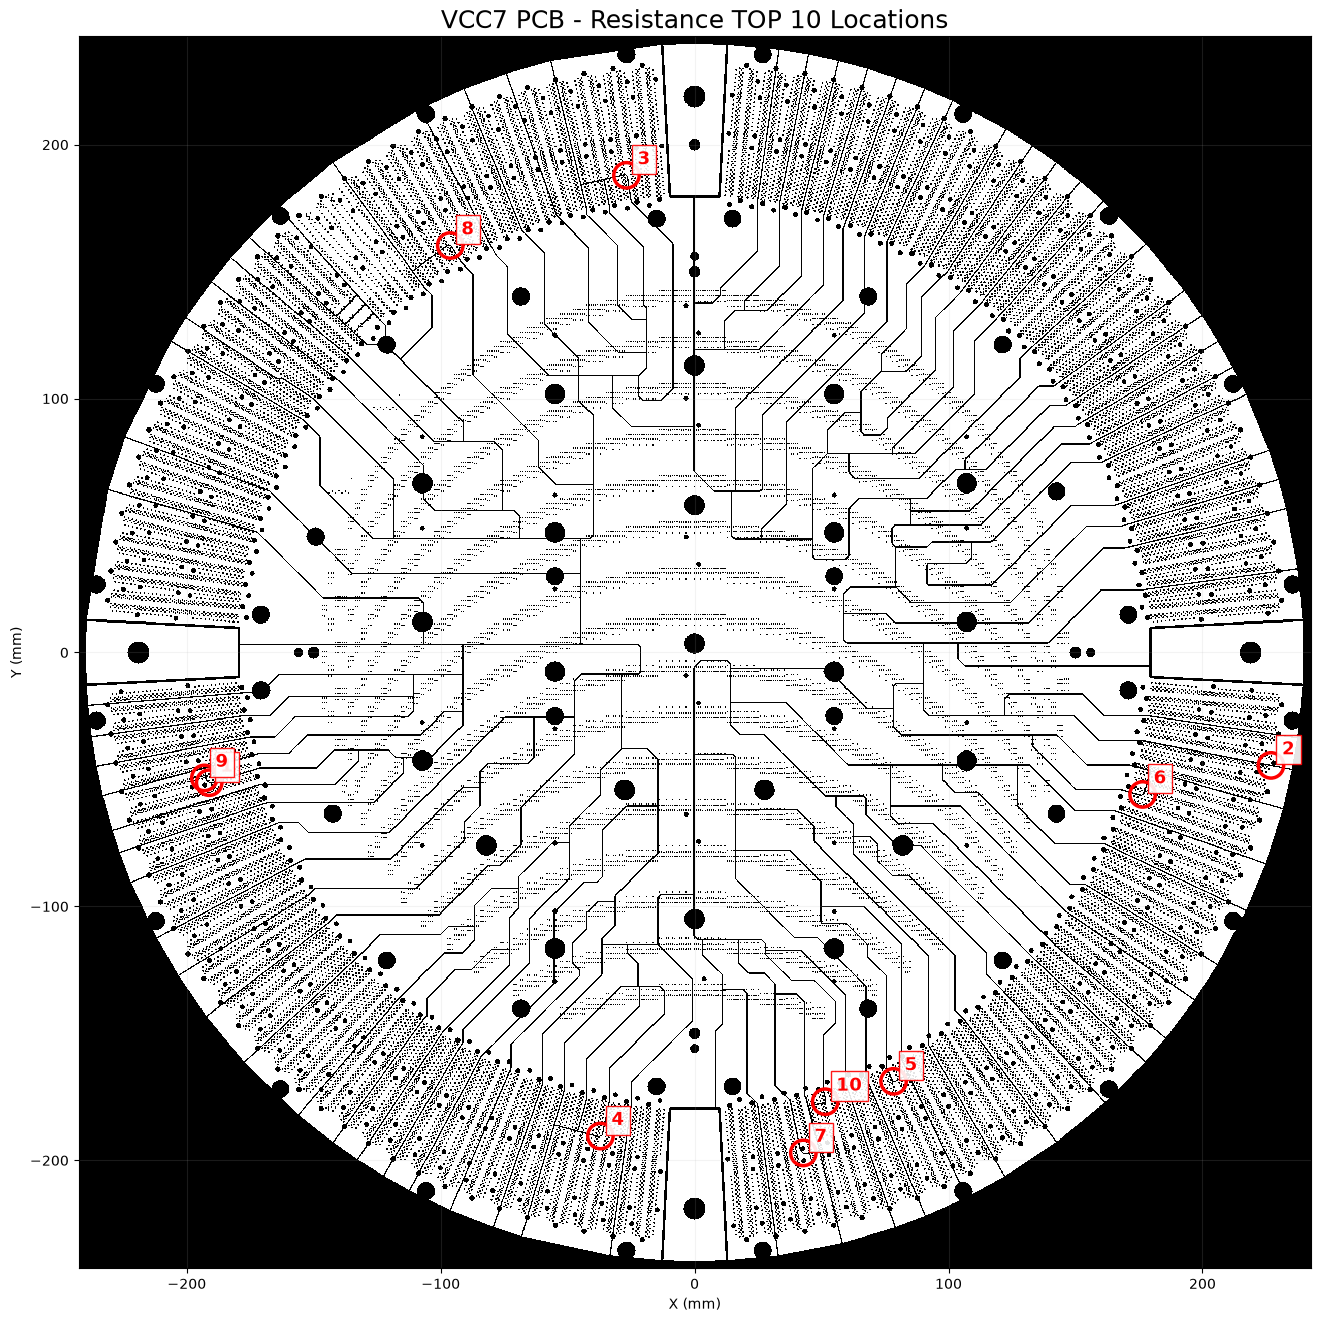

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# 기존 변수 사용: df_final, rasterize_tile, GRID_MM,
# TILE_MM, HALO_MM, xmin, xmax, ymin, ymax

old_grid, old_tile, old_halo = GRID_MM, TILE_MM, HALO_MM

# 전체 보드 시각화 해상도 (0.2 mm)
VIEW_GRID = 0.2
VIEW_TILE = 20.0
VIEW_HALO = 2.0

fig, ax = plt.subplots(figsize=(16, 16))

try:
    GRID_MM = VIEW_GRID
    TILE_MM = VIEW_TILE
    HALO_MM = VIEW_HALO

    # 전체 PCB를 타일 단위로 그리기
    for x0 in np.arange(xmin, xmax, VIEW_TILE):
        for y0 in np.arange(ymin, ymax, VIEW_TILE):

            mask, xs, ys = rasterize_tile(x0, y0)

            ax.imshow(
                mask,
                origin="lower",
                extent=[
                    xs[0] - VIEW_GRID / 2,
                    xs[-1] + VIEW_GRID / 2,
                    ys[0] - VIEW_GRID / 2,
                    ys[-1] + VIEW_GRID / 2
                ],
                cmap="Greys",
                vmin=0,
                vmax=1,
                interpolation="nearest"
            )

finally:
    GRID_MM, TILE_MM, HALO_MM = old_grid, old_tile, old_halo

# TOP 10 표시
for row in df_final.itertuples():

    x, y = row.x_mm, row.y_mm

    circle = Circle(
        (x, y),
        radius=5,
        fill=False,
        edgecolor="red",
        linewidth=2.5
    )
    ax.add_patch(circle)

    ax.annotate(
        f"{row.rank}",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        color="red",
        fontsize=13,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            edgecolor="red",
            alpha=0.9
        )
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_title(
    "VCC7 PCB - Resistance TOP 10 Locations",
    fontsize=18
)
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.grid(alpha=0.15)

plt.savefig(
    "VCC7_FULL_PCB_TOP10.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Angle analysis: 5000/20272
Angle analysis: 10000/20272
Angle analysis: 15000/20272
Angle analysis: 20000/20272

========== BEND FILTER SUMMARY ==========
전체 후보: 20272
형상 분석 성공: 20272
모서리 제외 후: 19912
제외된 후보: 360

========== STRAIGHT TRACE TOP 10 ==========


,rank,x_mm,y_mm,refined_score,min_width_mm,effective_width_mm,max_bend_deg,center_bend_deg,straightness
0,1,-26.8370,187.9170,3.2327,0.2800,0.3093,30.4680,12.2427,0.9079
1,2,-37.0994,-190.4200,2.9899,0.3200,0.3345,17.2325,6.4962,0.9331
2,3,78.3531,-168.8800,2.7667,0.3200,0.3614,27.1665,12.5185,0.9202
3,4,176.4230,-55.8970,2.7386,0.3441,0.3651,6.5503,6.5503,0.9431
4,5,42.8170,-197.0770,2.7052,0.3298,0.3697,9.6351,5.9562,0.9498
5,6,-96.2238,160.2838,2.4877,0.3418,0.4020,23.3018,6.6048,0.9270
6,7,51.4200,-176.9137,2.3806,0.3046,0.4201,23.7917,19.8076,0.9057
7,8,-38.7331,185.6200,2.0907,0.4400,0.4783,16.6876,16.6876,0.9524
8,9,-30.2600,159.6600,2.0881,0.4400,0.4789,7.2165,0.0000,0.9919
9,10,-55.2600,-103.7200,2.0833,0.4800,0.4800,0.0000,0.0000,1.0000


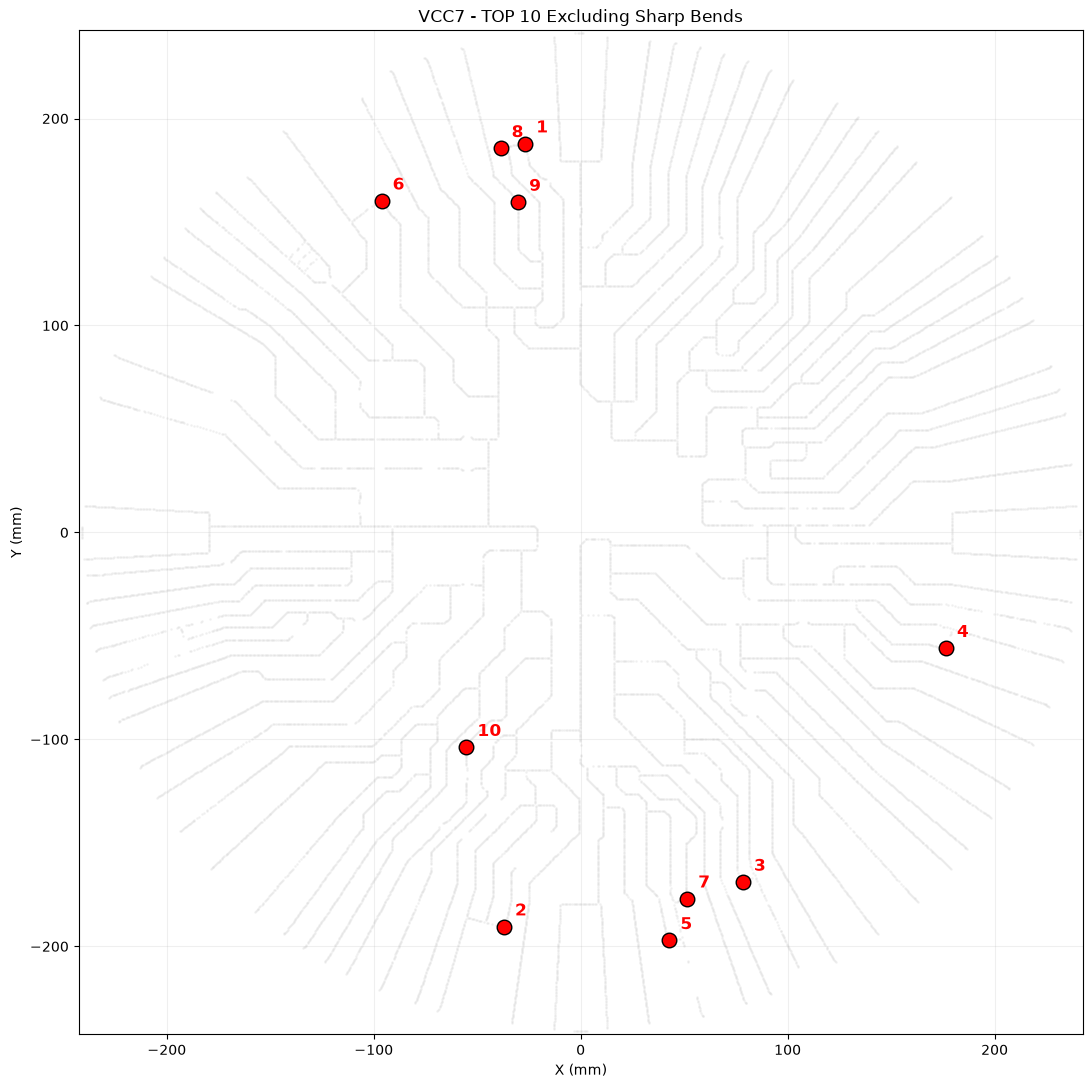

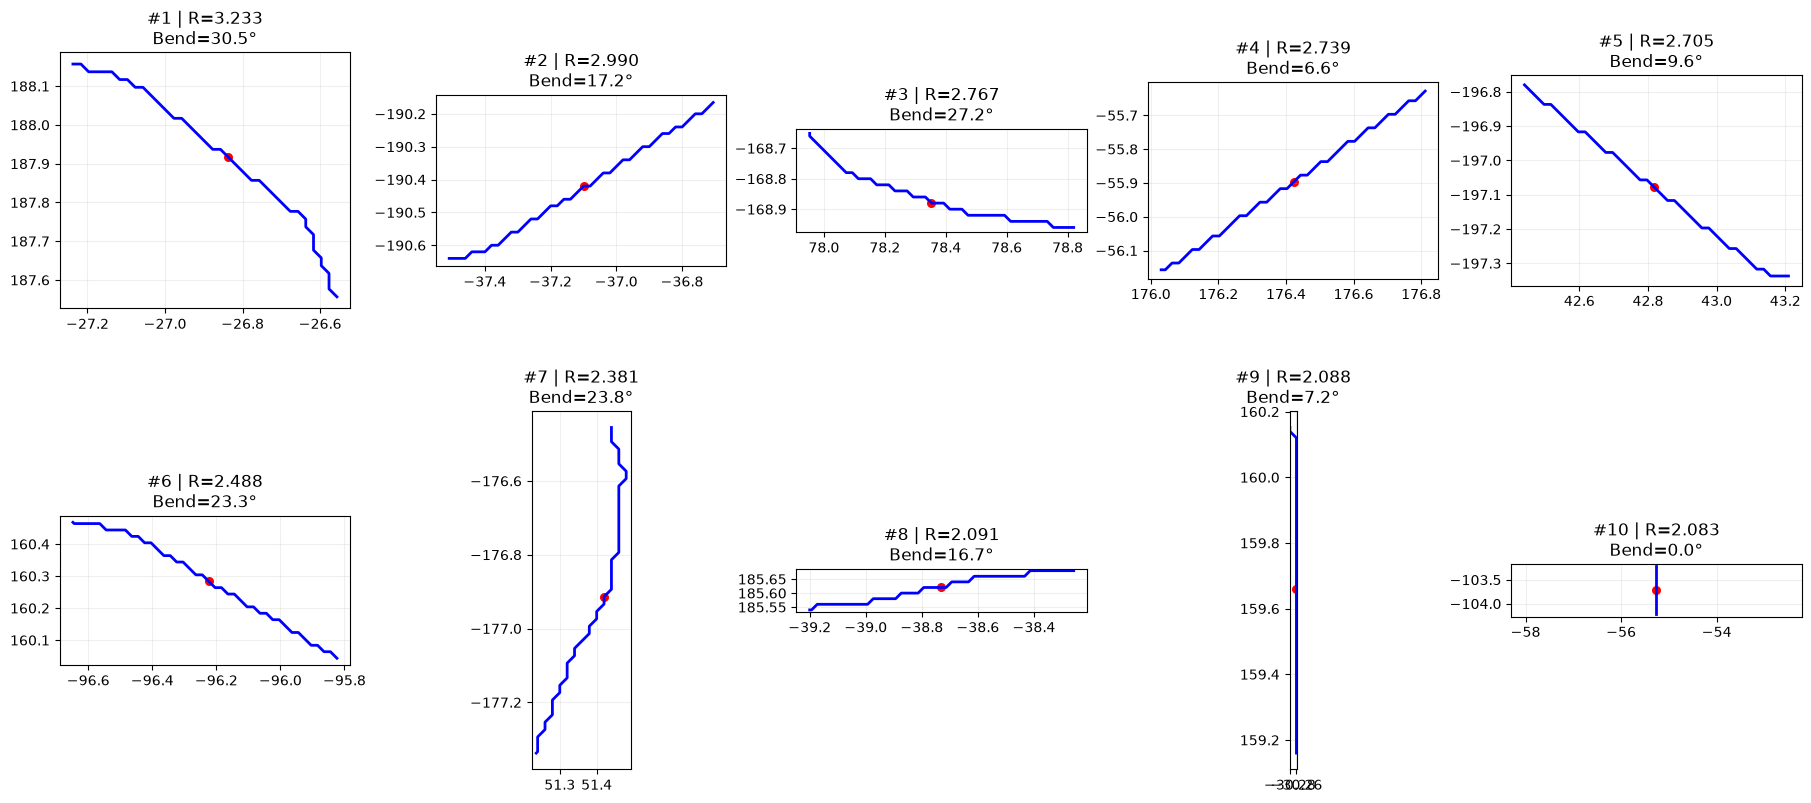


완료: 모서리 제외 TOP 10 계산 및 저장


In [83]:
# ============================================================
# VCC7 - 모서리(급격한 방향 변화) 제외 후 TOP 10
# 기존 df_refined_all의 20,272개 경로 활용
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# -----------------------------
# 1. 설정
# -----------------------------

TOP_N = 10
MIN_SEPARATION_MM = 2.0

# 모서리 판정
ANGLE_THRESHOLD_DEG = 45.0
ANGLE_SPAN_MM = 0.15

# 경로가 직선에서 얼마나 벗어나는지
MIN_STRAIGHTNESS = 0.88

# 중심 부근에 꺾임이 있는 경우 특히 제외
CENTER_ANGLE_THRESHOLD_DEG = 35.0
CENTER_RADIUS_MM = 0.20

# 픽셀 노이즈 제거용 경로 샘플 간격
SAMPLE_STEP_MM = 0.02


# -----------------------------
# 2. 경로 재표본화
# -----------------------------

def resample_path(path, step=0.02):

    p = np.asarray(path, dtype=float)

    if p.ndim != 2 or len(p) < 3:
        return None

    ds = np.linalg.norm(np.diff(p, axis=0), axis=1)
    cumulative = np.r_[0, np.cumsum(ds)]

    keep = np.r_[True, np.diff(cumulative) > 1e-9]

    cumulative = cumulative[keep]
    p = p[keep]

    if len(p) < 3 or cumulative[-1] < 0.5:
        return None

    samples = np.linspace(
        0,
        cumulative[-1],
        max(3, int(np.ceil(cumulative[-1] / step)) + 1)
    )

    x = np.interp(samples, cumulative, p[:, 0])
    y = np.interp(samples, cumulative, p[:, 1])

    return np.column_stack([x, y]), samples


# -----------------------------
# 3. 꺾임 각도 계산
# -----------------------------

def calculate_bend_metrics(path):

    result = resample_path(path, SAMPLE_STEP_MM)

    if result is None:
        return None

    p, s = result

    total_length = s[-1]

    span = ANGLE_SPAN_MM

    valid_s = s[
        (s >= span) &
        (s <= total_length - span)
    ]

    if len(valid_s) == 0:
        return None

    angles = []

    for position in valid_s:

        # 앞뒤 일정 거리의 좌표
        left_s = position - span
        right_s = position + span

        left = np.array([
            np.interp(left_s, s, p[:, 0]),
            np.interp(left_s, s, p[:, 1])
        ])

        center = np.array([
            np.interp(position, s, p[:, 0]),
            np.interp(position, s, p[:, 1])
        ])

        right = np.array([
            np.interp(right_s, s, p[:, 0]),
            np.interp(right_s, s, p[:, 1])
        ])

        v1 = center - left
        v2 = right - center

        n1 = np.linalg.norm(v1)
        n2 = np.linalg.norm(v2)

        if n1 < 1e-9 or n2 < 1e-9:
            angles.append(np.nan)
            continue

        cos_theta = np.clip(
            np.dot(v1, v2) / (n1 * n2),
            -1.0,
            1.0
        )

        angle = np.degrees(np.arccos(cos_theta))

        angles.append(angle)

    angles = np.asarray(angles)

    if not np.isfinite(angles).any():
        return None

    # 경로 전체 최대 꺾임
    max_angle = float(np.nanmax(angles))

    # 경로 중간 0.2mm 구간에서 최대 꺾임
    center_mask = (
        np.abs(valid_s - total_length / 2)
        <= CENTER_RADIUS_MM
    )

    center_angle = (
        float(np.nanmax(angles[center_mask]))
        if np.any(center_mask)
        else np.nan
    )

    endpoint_distance = np.linalg.norm(p[-1] - p[0])

    straightness = float(
        endpoint_distance / total_length
    )

    return {
        "max_bend_deg": max_angle,
        "center_bend_deg": center_angle,
        "straightness": straightness
    }


# -----------------------------
# 4. 전체 후보 판정
# -----------------------------

rows = []

for i, row in enumerate(df_refined_all.itertuples()):

    metrics = calculate_bend_metrics(row.path_coords)

    if metrics is None:
        continue

    is_straight = (
        metrics["max_bend_deg"] <= ANGLE_THRESHOLD_DEG
        and metrics["center_bend_deg"] <= CENTER_ANGLE_THRESHOLD_DEG
        and metrics["straightness"] >= MIN_STRAIGHTNESS
    )

    rows.append({
        "x_mm": row.x_mm,
        "y_mm": row.y_mm,
        "refined_score": row.refined_score,
        "min_width_mm": row.min_width_mm,
        "effective_width_mm": row.effective_width_mm,
        "max_bend_deg": metrics["max_bend_deg"],
        "center_bend_deg": metrics["center_bend_deg"],
        "straightness": metrics["straightness"],
        "is_straight": is_straight,
        "path_coords": row.path_coords
    })

    if (i + 1) % 5000 == 0:
        print(f"Angle analysis: {i+1}/{len(df_refined_all)}")

df_bend_analysis = pd.DataFrame(rows)

df_straight = df_bend_analysis[
    df_bend_analysis["is_straight"]
].sort_values(
    "refined_score",
    ascending=False
).reset_index(drop=True)

# -----------------------------
# 5. 중복 위치 제외
# -----------------------------

selected = []
selected_xy = []

for row in df_straight.itertuples():

    xy = np.array([row.x_mm, row.y_mm])

    if selected_xy:

        distances = np.linalg.norm(
            np.asarray(selected_xy) - xy,
            axis=1
        )

        if distances.min() < MIN_SEPARATION_MM:
            continue

    selected.append(row._asdict())
    selected_xy.append(xy)

    if len(selected) == TOP_N:
        break

df_straight_top10 = pd.DataFrame(selected)

df_straight_top10.insert(
    0, "rank",
    np.arange(1, len(df_straight_top10) + 1)
)

# -----------------------------
# 6. 결과 출력
# -----------------------------

print("\n========== BEND FILTER SUMMARY ==========")
print("전체 후보:", len(df_refined_all))
print("형상 분석 성공:", len(df_bend_analysis))
print("모서리 제외 후:", len(df_straight))
print("제외된 후보:", len(df_bend_analysis) - len(df_straight))

print("\n========== STRAIGHT TRACE TOP 10 ==========")

display(
    df_straight_top10.drop(
        columns=["path_coords", "Index", "is_straight"],
        errors="ignore"
    ).round(4)
)

# -----------------------------
# 7. 전체 PCB 좌표상 위치
# -----------------------------

fig, ax = plt.subplots(figsize=(11, 11))

ax.scatter(
    df_straight["x_mm"],
    df_straight["y_mm"],
    s=1,
    color="lightgray",
    alpha=0.2
)

ax.scatter(
    df_straight_top10["x_mm"],
    df_straight_top10["y_mm"],
    s=110,
    color="red",
    edgecolor="black",
    zorder=5
)

for row in df_straight_top10.itertuples():

    ax.annotate(
        str(row.rank),
        (row.x_mm, row.y_mm),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=12,
        color="red",
        fontweight="bold"
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("VCC7 - TOP 10 Excluding Sharp Bends")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    "VCC7_STRAIGHT_TOP10_MAP.png",
    dpi=250
)
plt.show()

# -----------------------------
# 8. 선정된 경로 모양 확인
# -----------------------------

fig, axes = plt.subplots(
    2, 5,
    figsize=(18, 8),
    constrained_layout=True
)

for ax, row in zip(axes.flat, df_straight_top10.itertuples()):

    path = np.asarray(row.path_coords)

    ax.plot(
        path[:, 0],
        path[:, 1],
        color="blue",
        linewidth=2
    )

    ax.scatter(
        [row.x_mm],
        [row.y_mm],
        color="red",
        s=30
    )

    ax.set_title(
        f"#{row.rank} | R={row.refined_score:.3f}\n"
        f"Bend={row.max_bend_deg:.1f}°"
    )

    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.savefig(
    "VCC7_STRAIGHT_TOP10_PATHS.png",
    dpi=250
)
plt.show()

# -----------------------------
# 9. 저장
# -----------------------------

df_straight_top10.drop(
    columns=["path_coords", "Index"],
    errors="ignore"
).to_csv(
    "VCC7_STRAIGHT_TOP10.csv",
    index=False,
    encoding="utf-8-sig"
)

df_bend_analysis.drop(
    columns=["path_coords"],
    errors="ignore"
).to_csv(
    "VCC7_ALL_BEND_ANALYSIS.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n완료: 모서리 제외 TOP 10 계산 및 저장")

전체 경로에서 모서리 위치 탐색 중...
Analyzed 5000/20272
Analyzed 10000/20272
Analyzed 15000/20272
Analyzed 20000/20272

========== CORNER EXCLUSION SUMMARY ==========
전체 분석 후보: 20272
검출된 모서리 위치: 8139
모서리 근처 후보: 3187
최종 필터 통과: 12268

========== NO CORNER TOP 10 ==========


,rank,x_mm,y_mm,refined_score,min_width_mm,effective_width_mm,straightness,max_bend_deg,distance_to_corner_mm
0,1,-55.26,-103.72,2.0833,0.48,0.48,1.0000,0.0,1.5704
1,2,-31.26,-106.24,2.0833,0.48,0.48,1.0000,0.0,1.2002
2,3,-31.26,-101.52,2.0833,0.48,0.48,1.0000,0.0,5.7603
3,4,-55.26,-108.52,2.0833,0.48,0.48,1.0000,0.0,4.2400
4,5,-55.26,-121.48,2.0833,0.48,0.48,1.0000,0.0,1.0002
5,6,-30.26,141.14,2.0833,0.48,0.48,1.0084,0.0,4.3400
6,7,-55.26,-106.28,2.0833,0.48,0.48,1.0000,0.0,4.1239
7,8,-31.26,-97.12,2.0833,0.48,0.48,1.0000,0.0,1.3613
8,9,-31.26,-104.08,2.0833,0.48,0.48,1.0000,0.0,3.3601
9,10,-30.26,150.54,2.0833,0.48,0.48,1.0084,0.0,9.7000


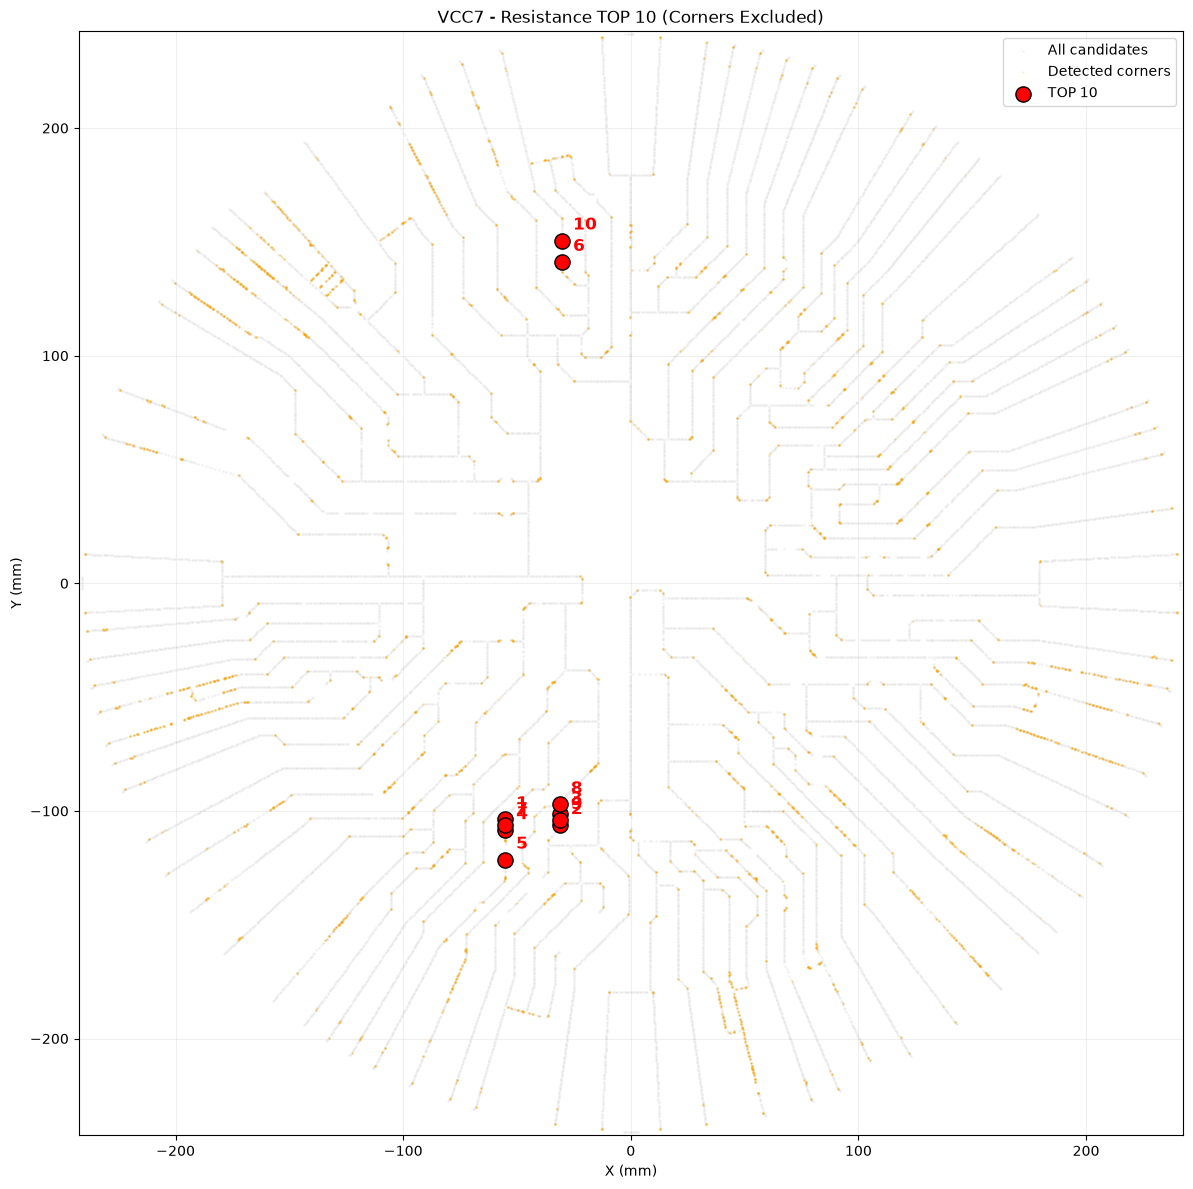

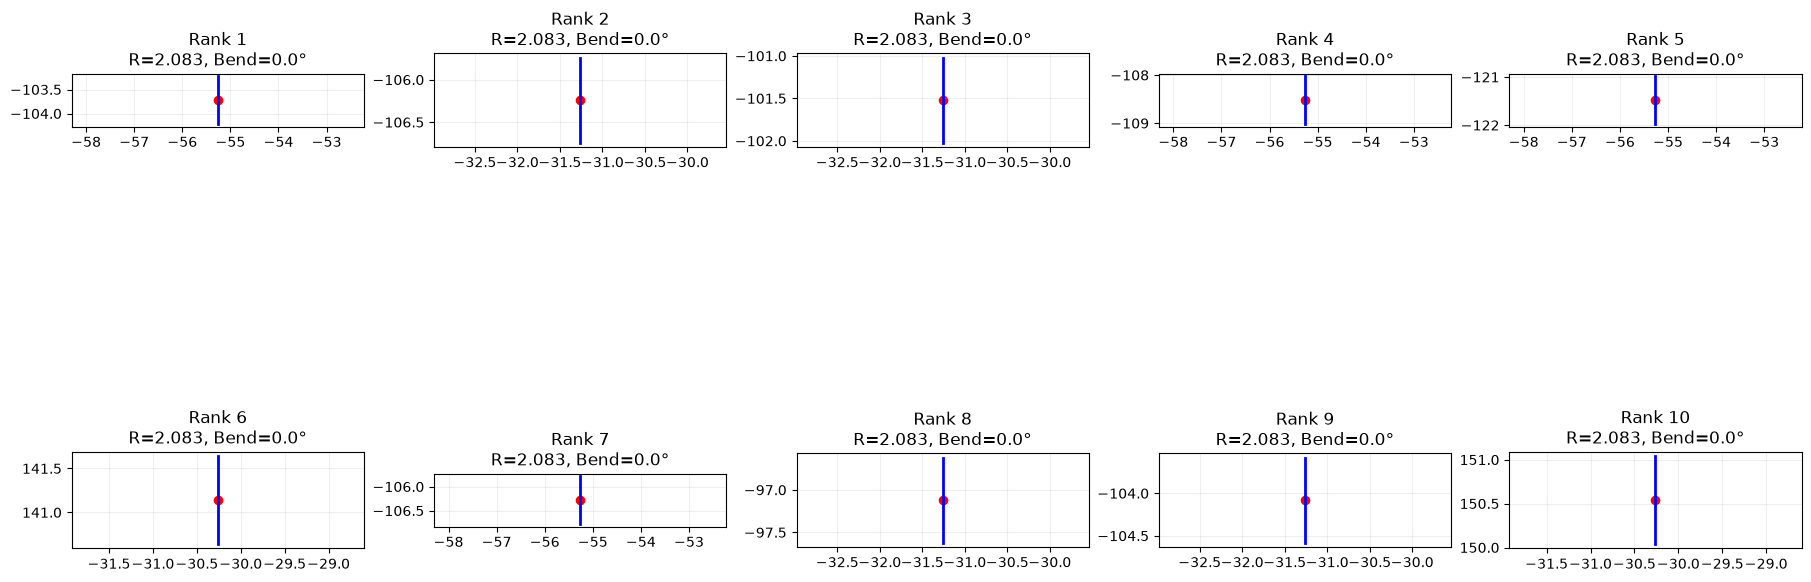


완료: 모서리 주변 제외 TOP 10


In [84]:
# ============================================================
# VCC7 - CORNER EXCLUSION V2
# 전체 경로에서 꺾임 위치 탐색
# 꺾임 주변 0.8 mm 제거
# 직선 배선만 TOP 10 선정
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from scipy.signal import savgol_filter

# ============================================================
# 1. 설정
# ============================================================

TOP_N = 10

# 모서리로 판단할 최소 방향 변화
CORNER_ANGLE_DEG = 18.0

# 모서리로부터 제외할 거리
CORNER_EXCLUSION_MM = 0.8

# 최종 경로의 직선성
MIN_STRAIGHTNESS = 0.97

# 최종 경로 최대 꺾임
MAX_PATH_BEND_DEG = 12.0

# 최종 후보 간 거리
MIN_SEPARATION_MM = 2.0

# 방향 변화 측정 구간
ANGLE_SPAN_MM = 0.18

# 경로 재표본화 간격
SAMPLE_STEP_MM = 0.02

# ============================================================
# 2. 경로 분석 함수
# ============================================================

def analyze_path_geometry(path):

    p = np.asarray(path, dtype=float)

    if p.ndim != 2 or len(p) < 3:
        return None

    segment_length = np.linalg.norm(
        np.diff(p, axis=0),
        axis=1
    )

    cumulative = np.r_[
        0,
        np.cumsum(segment_length)
    ]

    keep = np.r_[
        True,
        np.diff(cumulative) > 1e-9
    ]

    cumulative = cumulative[keep]
    p = p[keep]

    if len(p) < 3 or cumulative[-1] < 0.5:
        return None

    total_length = cumulative[-1]

    samples = np.arange(
        0,
        total_length,
        SAMPLE_STEP_MM
    )

    samples = np.r_[samples, total_length]

    x = np.interp(samples, cumulative, p[:, 0])
    y = np.interp(samples, cumulative, p[:, 1])

    coords = np.column_stack([x, y])

    # 픽셀 계단 노이즈 완화
    if len(coords) >= 11:

        window = min(
            11,
            len(coords) if len(coords) % 2 else len(coords)-1
        )

        coords[:, 0] = savgol_filter(
            coords[:, 0], window, 2
        )

        coords[:, 1] = savgol_filter(
            coords[:, 1], window, 2
        )

    endpoint_distance = np.linalg.norm(
        coords[-1] - coords[0]
    )

    straightness = endpoint_distance / total_length

    # 일정 거리 앞뒤를 비교하여 꺾임 측정
    angles = []
    positions = []

    for s in samples:

        if (
            s < ANGLE_SPAN_MM
            or s > total_length - ANGLE_SPAN_MM
        ):
            continue

        left_s = s - ANGLE_SPAN_MM
        right_s = s + ANGLE_SPAN_MM

        left = np.array([
            np.interp(left_s, samples, coords[:, 0]),
            np.interp(left_s, samples, coords[:, 1])
        ])

        center = np.array([
            np.interp(s, samples, coords[:, 0]),
            np.interp(s, samples, coords[:, 1])
        ])

        right = np.array([
            np.interp(right_s, samples, coords[:, 0]),
            np.interp(right_s, samples, coords[:, 1])
        ])

        v1 = center - left
        v2 = right - center

        n1 = np.linalg.norm(v1)
        n2 = np.linalg.norm(v2)

        if n1 < 1e-9 or n2 < 1e-9:
            continue

        cosine = np.clip(
            np.dot(v1, v2) / (n1 * n2),
            -1,
            1
        )

        angle = np.degrees(
            np.arccos(cosine)
        )

        angles.append(angle)
        positions.append(center)

    if not angles:
        return None

    angles = np.asarray(angles)
    positions = np.asarray(positions)

    corner_points = positions[
        angles >= CORNER_ANGLE_DEG
    ]

    return {
        "straightness": float(straightness),
        "max_bend_deg": float(np.max(angles)),
        "corner_points": corner_points
    }


# ============================================================
# 3. 전체 후보의 꺾임 위치 수집
# ============================================================

all_rows = []
all_corners = []

print("전체 경로에서 모서리 위치 탐색 중...")

for i, row in enumerate(df_refined_all.itertuples()):

    geometry = analyze_path_geometry(
        row.path_coords
    )

    if geometry is None:
        continue

    all_rows.append({
        "x_mm": float(row.x_mm),
        "y_mm": float(row.y_mm),
        "refined_score": float(row.refined_score),
        "min_width_mm": float(row.min_width_mm),
        "effective_width_mm": float(
            row.effective_width_mm
        ),
        "straightness": geometry["straightness"],
        "max_bend_deg": geometry["max_bend_deg"],
        "path_coords": row.path_coords
    })

    if len(geometry["corner_points"]) > 0:
        all_corners.append(
            geometry["corner_points"]
        )

    if (i + 1) % 5000 == 0:
        print(
            f"Analyzed {i+1}/{len(df_refined_all)}"
        )

df_geometry = pd.DataFrame(all_rows)

# ============================================================
# 4. 모서리 위치 KDTree 생성
# ============================================================

if all_corners:

    corner_coords = np.vstack(all_corners)

    # 0.04 mm 격자로 중복 위치 제거
    corner_coords = (
        np.unique(
            np.round(corner_coords / 0.04).astype(int),
            axis=0
        ) * 0.04
    )

    corner_tree = cKDTree(corner_coords)

    candidate_xy = df_geometry[
        ["x_mm", "y_mm"]
    ].to_numpy()

    distances, _ = corner_tree.query(
        candidate_xy
    )

else:

    corner_coords = np.empty((0, 2))

    distances = np.full(
        len(df_geometry),
        np.inf
    )

df_geometry["distance_to_corner_mm"] = distances

# ============================================================
# 5. 모서리 주변 제외 + 직선성 필터
# ============================================================

df_geometry["pass_filter"] = (
    (df_geometry["distance_to_corner_mm"]
        >= CORNER_EXCLUSION_MM)
    &
    (df_geometry["straightness"]
        >= MIN_STRAIGHTNESS)
    &
    (df_geometry["max_bend_deg"]
        <= MAX_PATH_BEND_DEG)
)

df_filtered = df_geometry[
    df_geometry["pass_filter"]
].sort_values(
    "refined_score",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 6. 중복 제거 및 TOP 10
# ============================================================

selected = []
selected_xy = []

for row in df_filtered.itertuples():

    xy = np.array([row.x_mm, row.y_mm])

    if selected_xy:

        d = np.linalg.norm(
            np.asarray(selected_xy) - xy,
            axis=1
        )

        if np.min(d) < MIN_SEPARATION_MM:
            continue

    selected.append(row._asdict())
    selected_xy.append(xy)

    if len(selected) >= TOP_N:
        break

df_no_corner_top10 = pd.DataFrame(selected)

if df_no_corner_top10.empty:
    raise RuntimeError(
        "현재 기준에서 통과한 후보가 없습니다. "
        "필터 기준을 확인하세요."
    )

df_no_corner_top10.insert(
    0,
    "rank",
    np.arange(1, len(df_no_corner_top10) + 1)
)

# ============================================================
# 7. 결과 출력
# ============================================================

print("\n========== CORNER EXCLUSION SUMMARY ==========")

print("전체 분석 후보:", len(df_geometry))
print("검출된 모서리 위치:", len(corner_coords))
print(
    "모서리 근처 후보:",
    int(np.sum(
        df_geometry["distance_to_corner_mm"]
        < CORNER_EXCLUSION_MM
    ))
)
print("최종 필터 통과:", len(df_filtered))

print("\n========== NO CORNER TOP 10 ==========")

display(
    df_no_corner_top10.drop(
        columns=["path_coords", "Index", "pass_filter"],
        errors="ignore"
    ).round(4)
)

# ============================================================
# 8. 전체 PCB 위치 표시
# ============================================================

fig, ax = plt.subplots(figsize=(12, 12))

# 전체 유효 후보
ax.scatter(
    df_geometry["x_mm"],
    df_geometry["y_mm"],
    s=1,
    color="lightgray",
    alpha=0.2,
    label="All candidates"
)

# 검출된 모서리 위치
if len(corner_coords):

    ax.scatter(
        corner_coords[:, 0],
        corner_coords[:, 1],
        s=0.5,
        color="orange",
        alpha=0.15,
        label="Detected corners"
    )

# TOP 10
ax.scatter(
    df_no_corner_top10["x_mm"],
    df_no_corner_top10["y_mm"],
    s=120,
    color="red",
    edgecolor="black",
    zorder=5,
    label="TOP 10"
)

for row in df_no_corner_top10.itertuples():

    ax.annotate(
        str(row.rank),
        (row.x_mm, row.y_mm),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=12,
        color="red",
        fontweight="bold"
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title(
    "VCC7 - Resistance TOP 10 (Corners Excluded)"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "VCC7_NO_CORNER_TOP10_MAP.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. 실제 경로 10개 확인
# ============================================================

fig, axes = plt.subplots(
    2, 5,
    figsize=(18, 8),
    constrained_layout=True
)

for ax, row in zip(
    axes.flat,
    df_no_corner_top10.itertuples()
):

    path = np.asarray(row.path_coords)

    ax.plot(
        path[:, 0],
        path[:, 1],
        "-b",
        linewidth=2
    )

    ax.scatter(
        [row.x_mm],
        [row.y_mm],
        color="red",
        s=35
    )

    ax.set_title(
        f"Rank {row.rank}\n"
        f"R={row.refined_score:.3f}, "
        f"Bend={row.max_bend_deg:.1f}°"
    )

    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.savefig(
    "VCC7_NO_CORNER_TOP10_PATHS.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. CSV 저장
# ============================================================

df_no_corner_top10.drop(
    columns=["path_coords", "Index"],
    errors="ignore"
).to_csv(
    "VCC7_NO_CORNER_TOP10.csv",
    index=False,
    encoding="utf-8-sig"
)

df_geometry.drop(
    columns=["path_coords"],
    errors="ignore"
).to_csv(
    "VCC7_CORNER_FILTER_ALL.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n완료: 모서리 주변 제외 TOP 10")

=== VCC7 SPATIALLY DIVERSE TOP 10 ===
모서리 제외 후보: 12268
최종 선정: 10
최소 위치 간격: 25.0 mm
구역 크기: 30.0 mm


,rank,x_mm,y_mm,refined_score,min_width_mm,effective_width_mm,straightness,max_bend_deg,distance_to_corner_mm,score_group,region_id
0,1,-55.2600,-126.7400,2.0833,0.4800,0.4800,1.0084,0.0000,2.0601,1,6_3
1,2,-31.2600,-106.2400,2.0833,0.4800,0.4800,1.0000,0.0000,1.2002,1,7_4
2,3,-30.2600,137.9400,2.0833,0.4800,0.4800,1.0084,0.0000,1.1402,1,7_12
3,4,177.7800,-24.8000,2.0382,0.4800,0.4906,0.9719,7.6172,10.0603,2,14_7
4,5,32.0800,-231.3469,2.0199,0.4800,0.4951,0.9701,6.7007,2.3290,3,9_0
5,6,177.3507,24.7907,2.0139,0.4800,0.4965,0.9719,7.9752,15.2882,4,13_8
6,7,-33.5200,-176.4931,2.0132,0.4472,0.4967,0.9716,8.0874,11.1939,5,6_2
7,8,-171.3459,-39.7659,2.0106,0.4400,0.4974,0.9713,11.6001,2.2643,6,2_6
8,9,-33.5200,175.6931,2.0089,0.4472,0.4978,0.9750,8.4034,2.6943,7,6_13
9,10,24.6400,176.9731,1.9955,0.4800,0.5011,0.9771,8.4153,15.2082,8,8_13


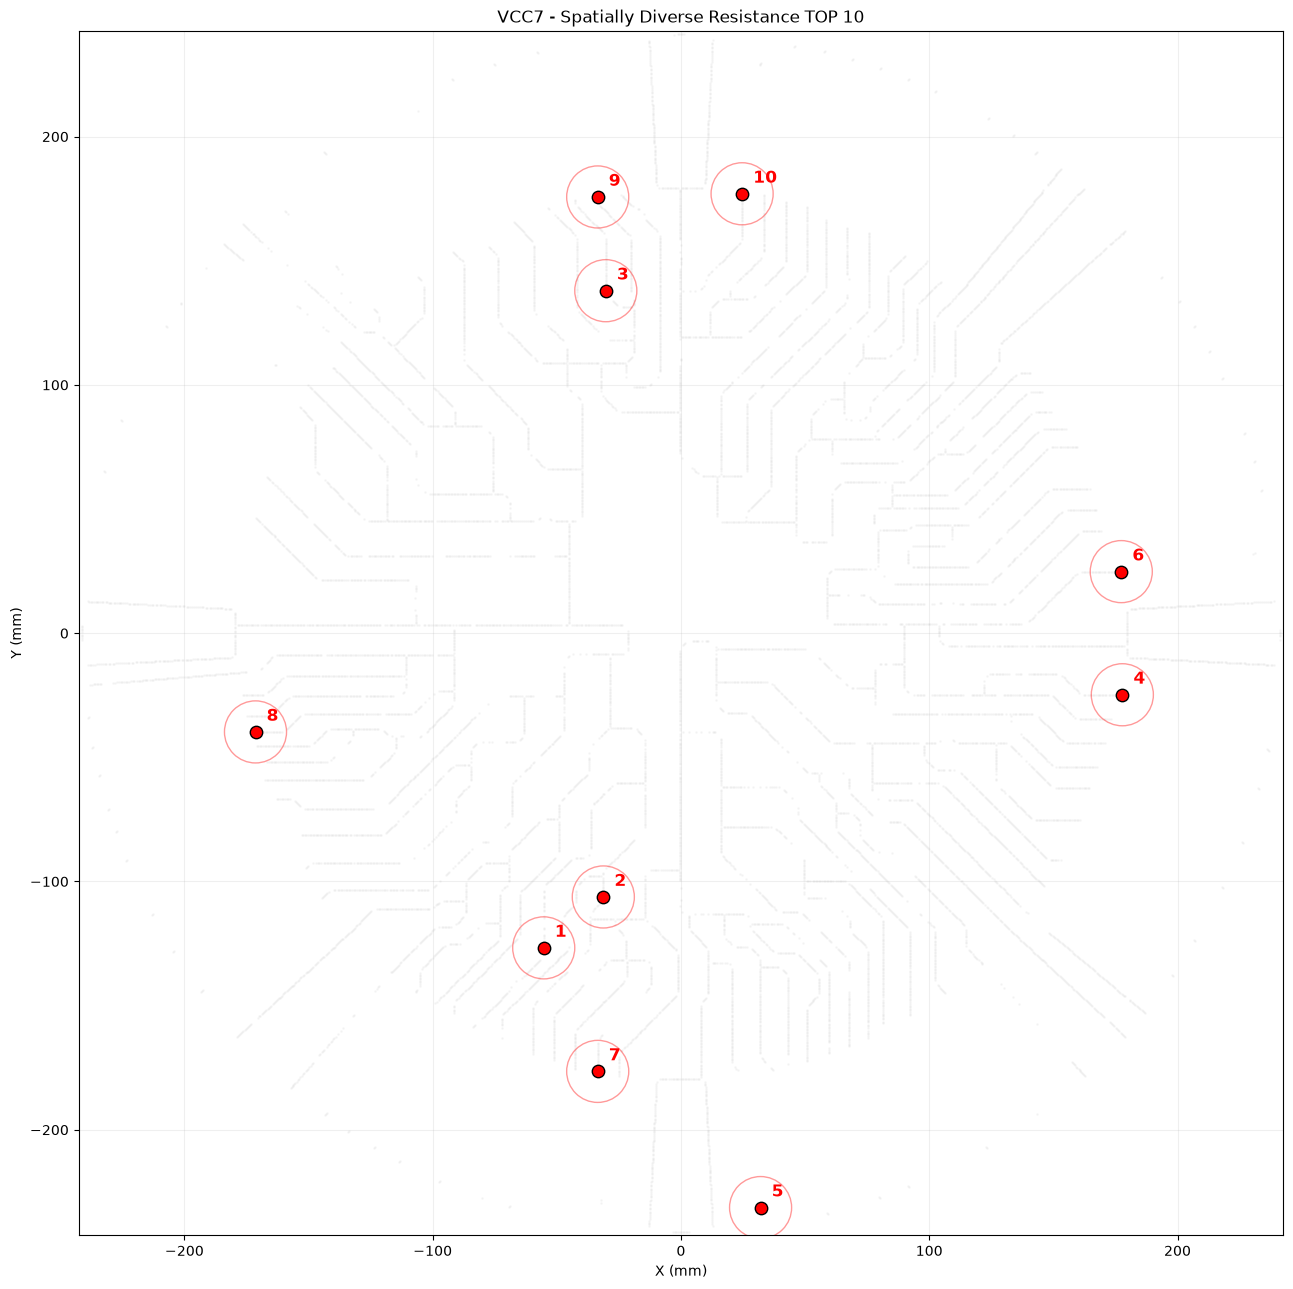

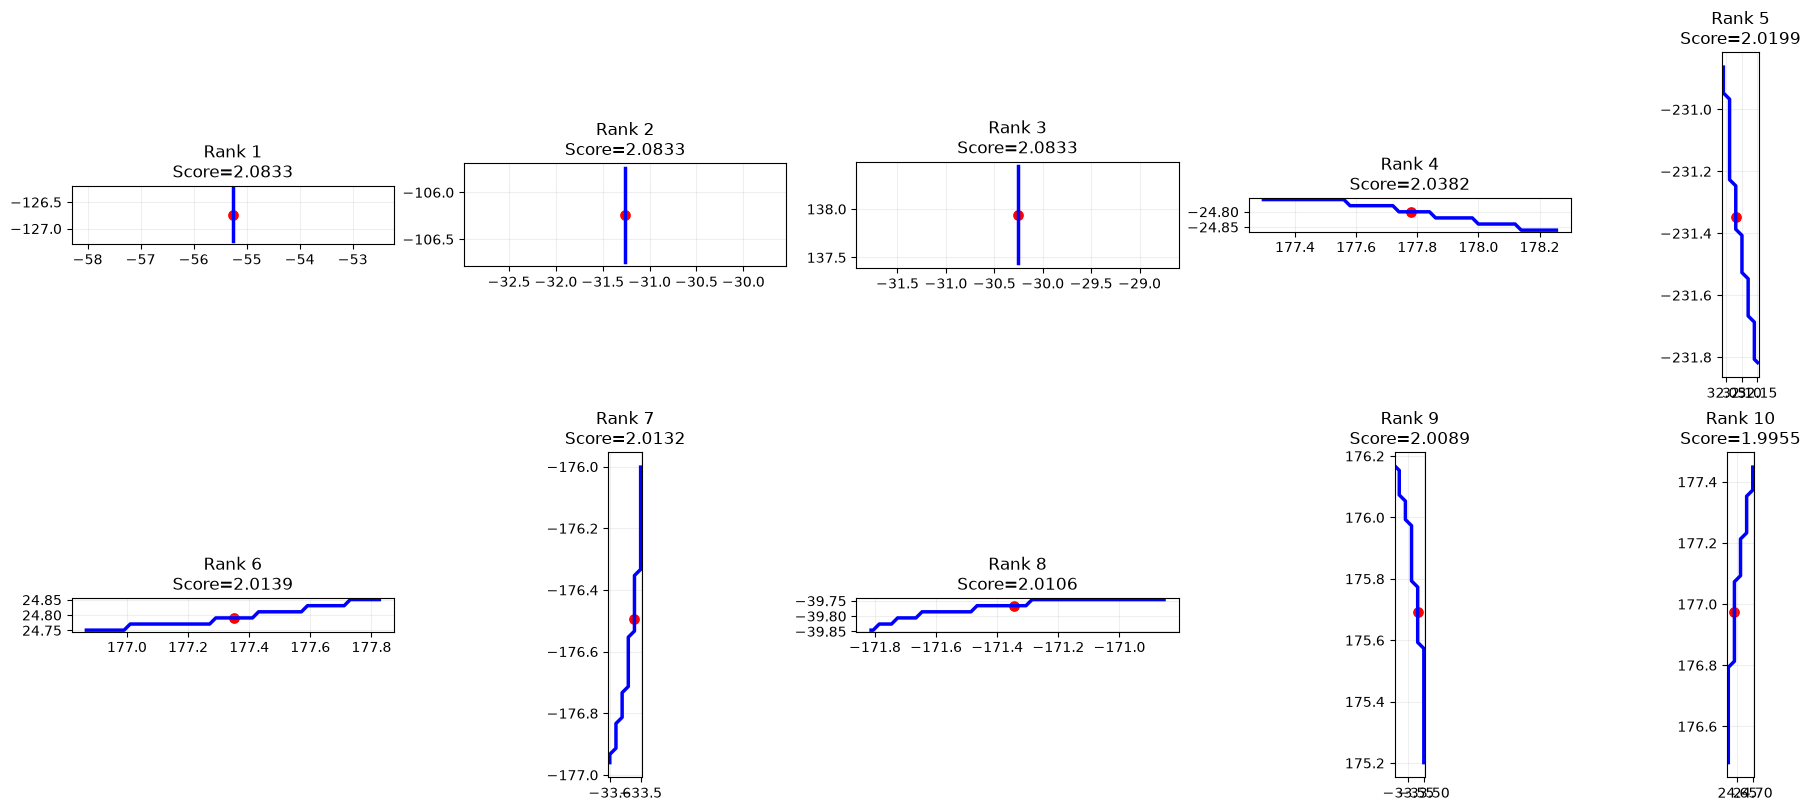


Saved:
VCC7_DIVERSE_TOP10.csv
VCC7_DIVERSE_TOP10_MAP.png
VCC7_DIVERSE_TOP10_PATHS.png


In [85]:
# ============================================================
# VCC7 - CORNER EXCLUDED + SPATIALLY DIVERSE TOP 10
# 기존 df_filtered 재사용
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# ------------------------------------------------------------
# 1. 설정
# ------------------------------------------------------------

TOP_N = 10

MIN_DISTANCE_MM = 25.0
REGION_SIZE_MM = 30.0

# 점수가 거의 같은 경우 동일 그룹으로 취급
SCORE_TOL = 1e-4

# ------------------------------------------------------------
# 2. 모서리 필터 통과 후보 준비
# ------------------------------------------------------------

df_pool = df_filtered.copy()

df_pool = df_pool.sort_values(
    ["refined_score", "x_mm", "y_mm"],
    ascending=[False, True, True]
).reset_index(drop=True)

# 공간 구역 ID
df_pool["region_x"] = np.floor(
    (df_pool["x_mm"] - xmin) / REGION_SIZE_MM
).astype(int)

df_pool["region_y"] = np.floor(
    (df_pool["y_mm"] - ymin) / REGION_SIZE_MM
).astype(int)

df_pool["region_id"] = (
    df_pool["region_x"].astype(str)
    + "_"
    + df_pool["region_y"].astype(str)
)

# ------------------------------------------------------------
# 3. 공간 중복 제거
# ------------------------------------------------------------

selected = []
selected_xy = []
used_regions = set()

for row in df_pool.itertuples():

    xy = np.array([row.x_mm, row.y_mm])

    # 동일 30mm 구역 제외
    if row.region_id in used_regions:
        continue

    # 기존 선정 위치와 25mm 이내면 제외
    if selected_xy:

        distances = np.linalg.norm(
            np.asarray(selected_xy) - xy,
            axis=1
        )

        if distances.min() < MIN_DISTANCE_MM:
            continue

    selected.append(row._asdict())
    selected_xy.append(xy)
    used_regions.add(row.region_id)

    if len(selected) >= TOP_N:
        break

if not selected:
    raise RuntimeError("조건을 만족하는 후보가 없습니다.")

df_diverse_top10 = pd.DataFrame(selected)

# ------------------------------------------------------------
# 4. 순위 및 동점 처리
# ------------------------------------------------------------

df_diverse_top10 = df_diverse_top10.sort_values(
    "refined_score",
    ascending=False
).reset_index(drop=True)

df_diverse_top10.insert(
    0,
    "rank",
    np.arange(1, len(df_diverse_top10) + 1)
)

scores = df_diverse_top10["refined_score"].to_numpy()

tie_groups = []
group = 0
previous_score = None

for score in scores:

    if (
        previous_score is None
        or abs(score - previous_score) > SCORE_TOL
    ):
        group += 1
        previous_score = score

    tie_groups.append(group)

df_diverse_top10["score_group"] = tie_groups

# ------------------------------------------------------------
# 5. 결과 출력
# ------------------------------------------------------------

print("=== VCC7 SPATIALLY DIVERSE TOP 10 ===")
print("모서리 제외 후보:", len(df_pool))
print("최종 선정:", len(df_diverse_top10))
print("최소 위치 간격:", MIN_DISTANCE_MM, "mm")
print("구역 크기:", REGION_SIZE_MM, "mm")

display(
    df_diverse_top10[
        [
            "rank",
            "x_mm",
            "y_mm",
            "refined_score",
            "min_width_mm",
            "effective_width_mm",
            "straightness",
            "max_bend_deg",
            "distance_to_corner_mm",
            "score_group",
            "region_id"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 6. 전체 PCB 좌표 위에 표시
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 13))

# 필터 통과 후보 분포
ax.scatter(
    df_pool["x_mm"],
    df_pool["y_mm"],
    s=1,
    c="lightgray",
    alpha=0.15,
    rasterized=True
)

# 선정된 위치
for row in df_diverse_top10.itertuples():

    ax.scatter(
        row.x_mm,
        row.y_mm,
        color="red",
        s=80,
        edgecolor="black",
        zorder=5
    )

    circle = Circle(
        (row.x_mm, row.y_mm),
        MIN_DISTANCE_MM / 2,
        fill=False,
        edgecolor="red",
        linewidth=1,
        alpha=0.4
    )

    ax.add_patch(circle)

    ax.annotate(
        str(row.rank),
        (row.x_mm, row.y_mm),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        color="red",
        zorder=6
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")

ax.set_title(
    "VCC7 - Spatially Diverse Resistance TOP 10"
)

ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "VCC7_DIVERSE_TOP10_MAP.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. 실제 경로 10개 확인
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 5,
    figsize=(19, 8),
    constrained_layout=True
)

for ax, row in zip(
    axes.flat,
    df_diverse_top10.itertuples()
):

    path = np.asarray(row.path_coords)

    ax.plot(
        path[:, 0],
        path[:, 1],
        "-b",
        linewidth=2.5
    )

    ax.scatter(
        [row.x_mm],
        [row.y_mm],
        color="red",
        s=45
    )

    ax.set_title(
        f"Rank {row.rank}\n"
        f"Score={row.refined_score:.4f}"
    )

    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.savefig(
    "VCC7_DIVERSE_TOP10_PATHS.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. CSV 저장
# ------------------------------------------------------------

df_diverse_top10.drop(
    columns=["path_coords", "Index"],
    errors="ignore"
).to_csv(
    "VCC7_DIVERSE_TOP10.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved:")
print("VCC7_DIVERSE_TOP10.csv")
print("VCC7_DIVERSE_TOP10_MAP.png")
print("VCC7_DIVERSE_TOP10_PATHS.png")

VCC7 FINAL RESISTANCE TOP 10
Corners Excluded / Spatial Duplicates Removed


,rank,x_mm,y_mm,refined_score,min_width_mm,effective_width_mm,distance_to_corner_mm
0,1,-55.2600,-126.7400,2.0833,0.4800,0.4800,2.0601
1,2,-31.2600,-106.2400,2.0833,0.4800,0.4800,1.2002
2,3,-30.2600,137.9400,2.0833,0.4800,0.4800,1.1402
3,4,177.7800,-24.8000,2.0382,0.4800,0.4906,10.0603
4,5,32.0800,-231.3469,2.0199,0.4800,0.4951,2.3290
5,6,177.3507,24.7907,2.0139,0.4800,0.4965,15.2882
6,7,-33.5200,-176.4931,2.0132,0.4472,0.4967,11.1939
7,8,-171.3459,-39.7659,2.0106,0.4400,0.4974,2.2643
8,9,-33.5200,175.6931,2.0089,0.4472,0.4978,2.6943
9,10,24.6400,176.9731,1.9955,0.4800,0.5011,15.2082


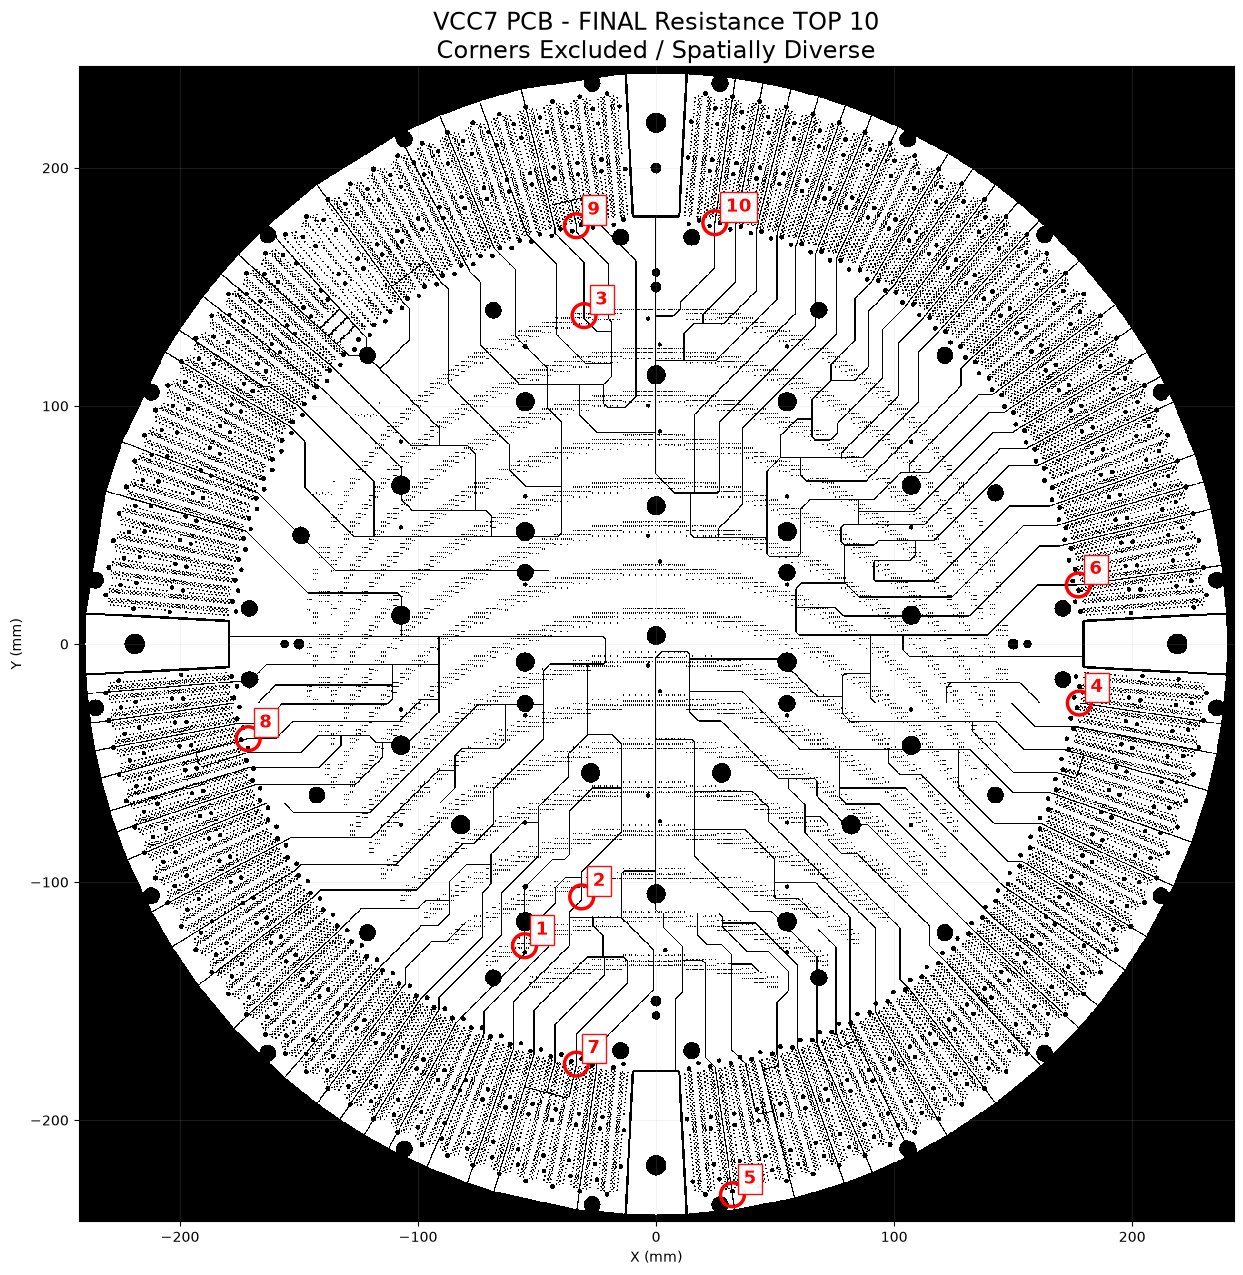

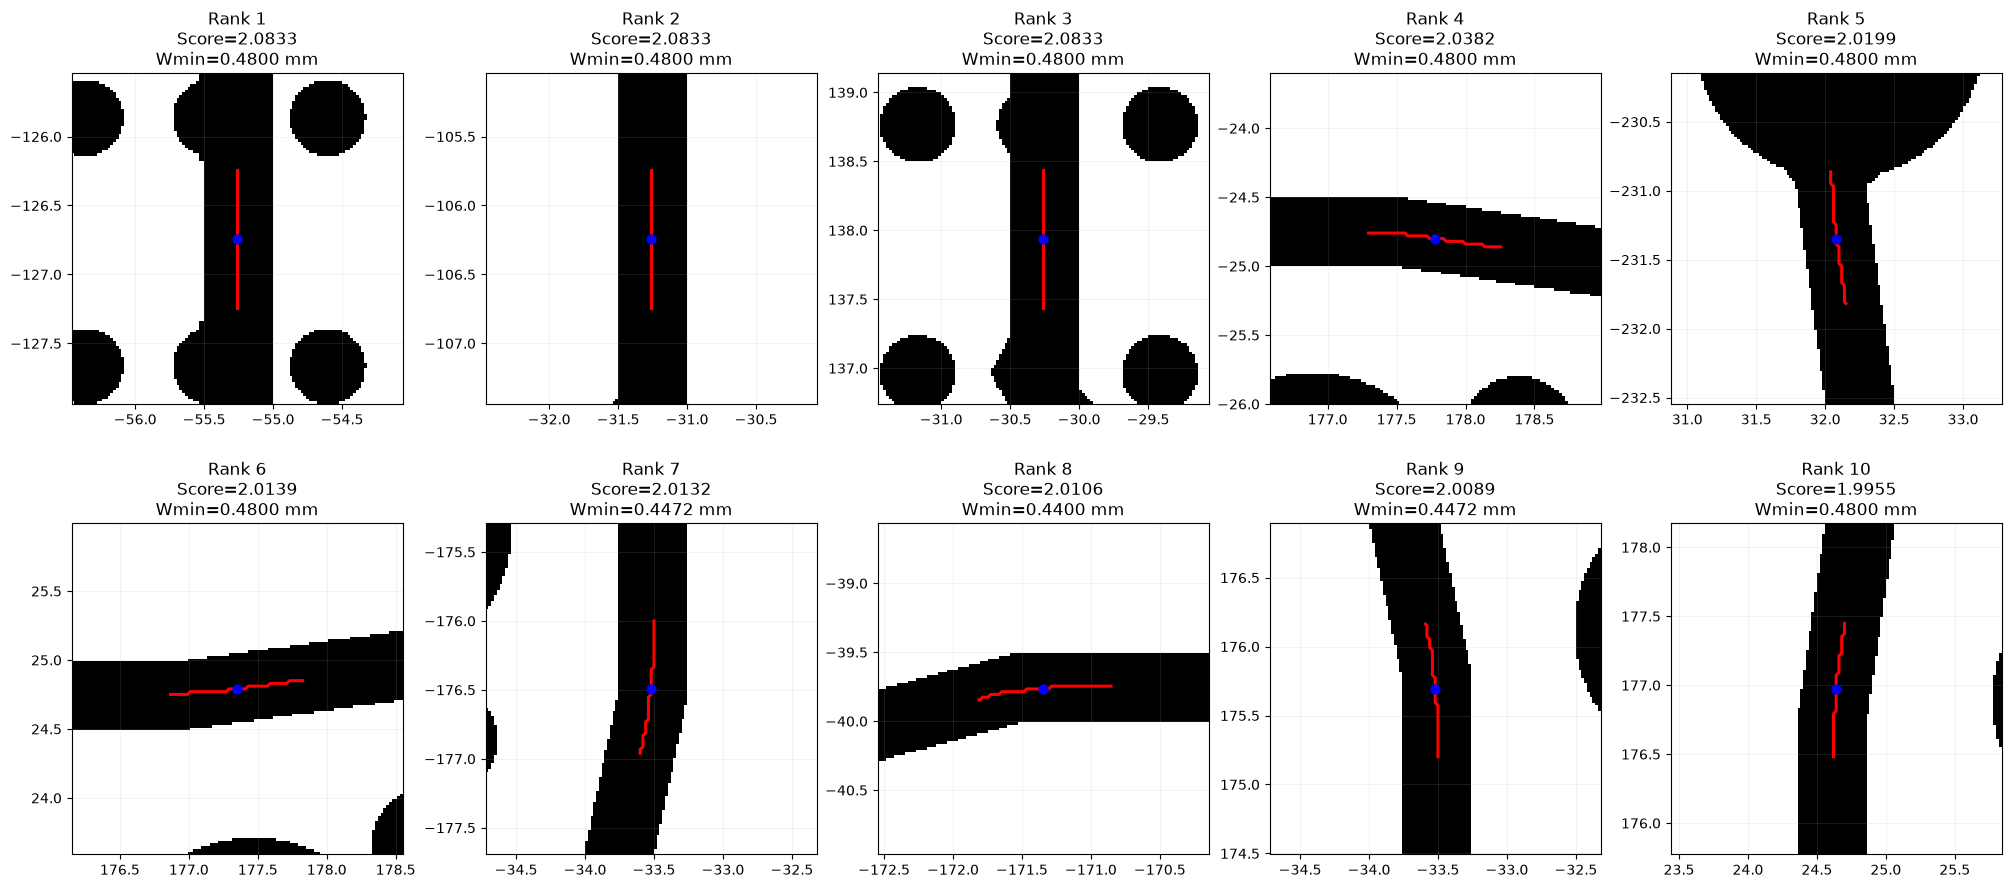

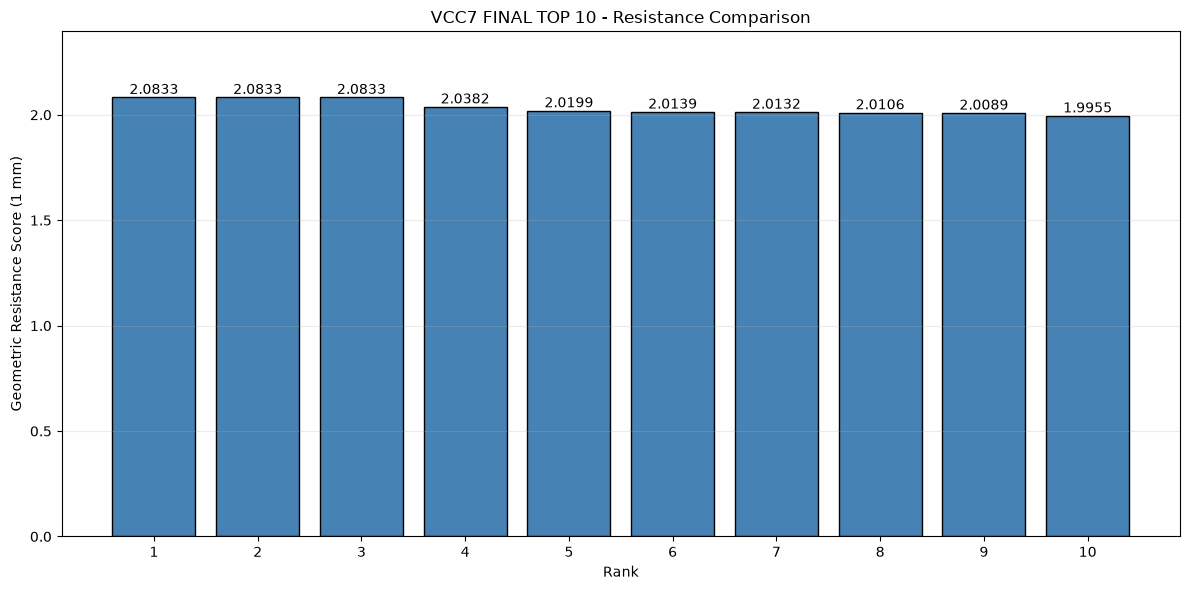


========== FINAL RESULT ==========
Highest-ranked location: (-55.2600, -126.7400) mm
Resistance score: 2.0833
Minimum width: 0.4800 mm
Effective width: 0.4800 mm

Saved files:
1. VCC7_FINAL_RESULT.csv
2. VCC7_FINAL_PCB_TOP10.png
3. VCC7_FINAL_TOP10_DETAIL.png
4. VCC7_FINAL_RESISTANCE_GRAPH.png


In [86]:
# ============================================================
# VCC7 FINAL RESULT VISUALIZATION
# 모서리 제외 + 공간 중복 제거 TOP 10
# 1. 최종 결과표
# 2. 전체 PCB 위 TOP 10 표시
# 3. TOP 10 개별 확대
# 4. 저항 점수 그래프
# 5. CSV / PNG 저장
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# ------------------------------------------------------------
# 1. 최종 결과 정리
# ------------------------------------------------------------

df_final_result = (
    df_diverse_top10
    .sort_values("refined_score", ascending=False)
    .reset_index(drop=True)
    .copy()
)

df_final_result["rank"] = np.arange(
    1, len(df_final_result) + 1
)

print("=" * 65)
print("VCC7 FINAL RESISTANCE TOP 10")
print("Corners Excluded / Spatial Duplicates Removed")
print("=" * 65)

display(
    df_final_result[
        [
            "rank",
            "x_mm",
            "y_mm",
            "refined_score",
            "min_width_mm",
            "effective_width_mm",
            "distance_to_corner_mm"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 2. 전체 PCB 패턴 위 TOP 10 표시
# ------------------------------------------------------------

old_grid = GRID_MM
old_tile = TILE_MM
old_halo = HALO_MM

VIEW_GRID = 0.2
VIEW_TILE = 20.0

fig, ax = plt.subplots(figsize=(15, 15))

try:
    GRID_MM = VIEW_GRID
    TILE_MM = VIEW_TILE
    HALO_MM = 2.0

    for x0 in np.arange(xmin, xmax, VIEW_TILE):
        for y0 in np.arange(ymin, ymax, VIEW_TILE):

            mask, xs, ys = rasterize_tile(x0, y0)

            ax.imshow(
                mask,
                origin="lower",
                extent=[
                    xs[0] - VIEW_GRID / 2,
                    xs[-1] + VIEW_GRID / 2,
                    ys[0] - VIEW_GRID / 2,
                    ys[-1] + VIEW_GRID / 2
                ],
                cmap="Greys",
                vmin=0,
                vmax=1,
                interpolation="nearest",
                zorder=1
            )

finally:
    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo

# TOP 10 위치 표시
for row in df_final_result.itertuples():

    ax.add_patch(
        Circle(
            (row.x_mm, row.y_mm),
            radius=5,
            fill=False,
            edgecolor="red",
            linewidth=2.5,
            zorder=5
        )
    )

    ax.annotate(
        f"{row.rank}",
        (row.x_mm, row.y_mm),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=13,
        color="red",
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            edgecolor="red",
            alpha=0.95
        ),
        zorder=6
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")

ax.set_title(
    "VCC7 PCB - FINAL Resistance TOP 10\n"
    "Corners Excluded / Spatially Diverse",
    fontsize=17
)

ax.grid(alpha=0.15)

plt.savefig(
    "VCC7_FINAL_PCB_TOP10.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. TOP 10 실제 구리 패턴 확대
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 5,
    figsize=(20, 9),
    constrained_layout=True
)

try:
    GRID_MM = 0.02
    TILE_MM = 3.0
    HALO_MM = 1.5

    for ax, row in zip(
        axes.flat,
        df_final_result.itertuples()
    ):

        x = float(row.x_mm)
        y = float(row.y_mm)

        mask, xs, ys = rasterize_tile(
            x - TILE_MM / 2,
            y - TILE_MM / 2
        )

        ax.imshow(
            mask,
            origin="lower",
            extent=[
                xs[0] - GRID_MM / 2,
                xs[-1] + GRID_MM / 2,
                ys[0] - GRID_MM / 2,
                ys[-1] + GRID_MM / 2
            ],
            cmap="Greys",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        path = np.asarray(row.path_coords)

        ax.plot(
            path[:, 0],
            path[:, 1],
            color="red",
            linewidth=2.2
        )

        ax.scatter(
            [x], [y],
            color="blue",
            s=40,
            zorder=5
        )

        ax.set_xlim(x - 1.2, x + 1.2)
        ax.set_ylim(y - 1.2, y + 1.2)

        ax.set_aspect("equal")

        ax.set_title(
            f"Rank {row.rank}\n"
            f"Score={row.refined_score:.4f}\n"
            f"Wmin={row.min_width_mm:.4f} mm"
        )

        ax.grid(alpha=0.15)

finally:
    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo

plt.savefig(
    "VCC7_FINAL_TOP10_DETAIL.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. 저항 점수 비교 그래프
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ranks = df_final_result["rank"].astype(str)
scores = df_final_result["refined_score"]

bars = ax.bar(
    ranks,
    scores,
    color="steelblue",
    edgecolor="black"
)

for bar, score in zip(bars, scores):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_xlabel("Rank")
ax.set_ylabel("Geometric Resistance Score (1 mm)")
ax.set_title("VCC7 FINAL TOP 10 - Resistance Comparison")
ax.grid(axis="y", alpha=0.25)

ax.set_ylim(0, max(scores) * 1.15)

plt.tight_layout()

plt.savefig(
    "VCC7_FINAL_RESISTANCE_GRAPH.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. 최종 결과 CSV 저장
# ------------------------------------------------------------

df_final_result.drop(
    columns=["path_coords", "Index"],
    errors="ignore"
).to_csv(
    "VCC7_FINAL_RESULT.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n========== FINAL RESULT ==========")

best = df_final_result.iloc[0]

print(f"Highest-ranked location: ({best.x_mm:.4f}, {best.y_mm:.4f}) mm")
print(f"Resistance score: {best.refined_score:.4f}")
print(f"Minimum width: {best.min_width_mm:.4f} mm")
print(f"Effective width: {best.effective_width_mm:.4f} mm")

print("\nSaved files:")
print("1. VCC7_FINAL_RESULT.csv")
print("2. VCC7_FINAL_PCB_TOP10.png")
print("3. VCC7_FINAL_TOP10_DETAIL.png")
print("4. VCC7_FINAL_RESISTANCE_GRAPH.png")

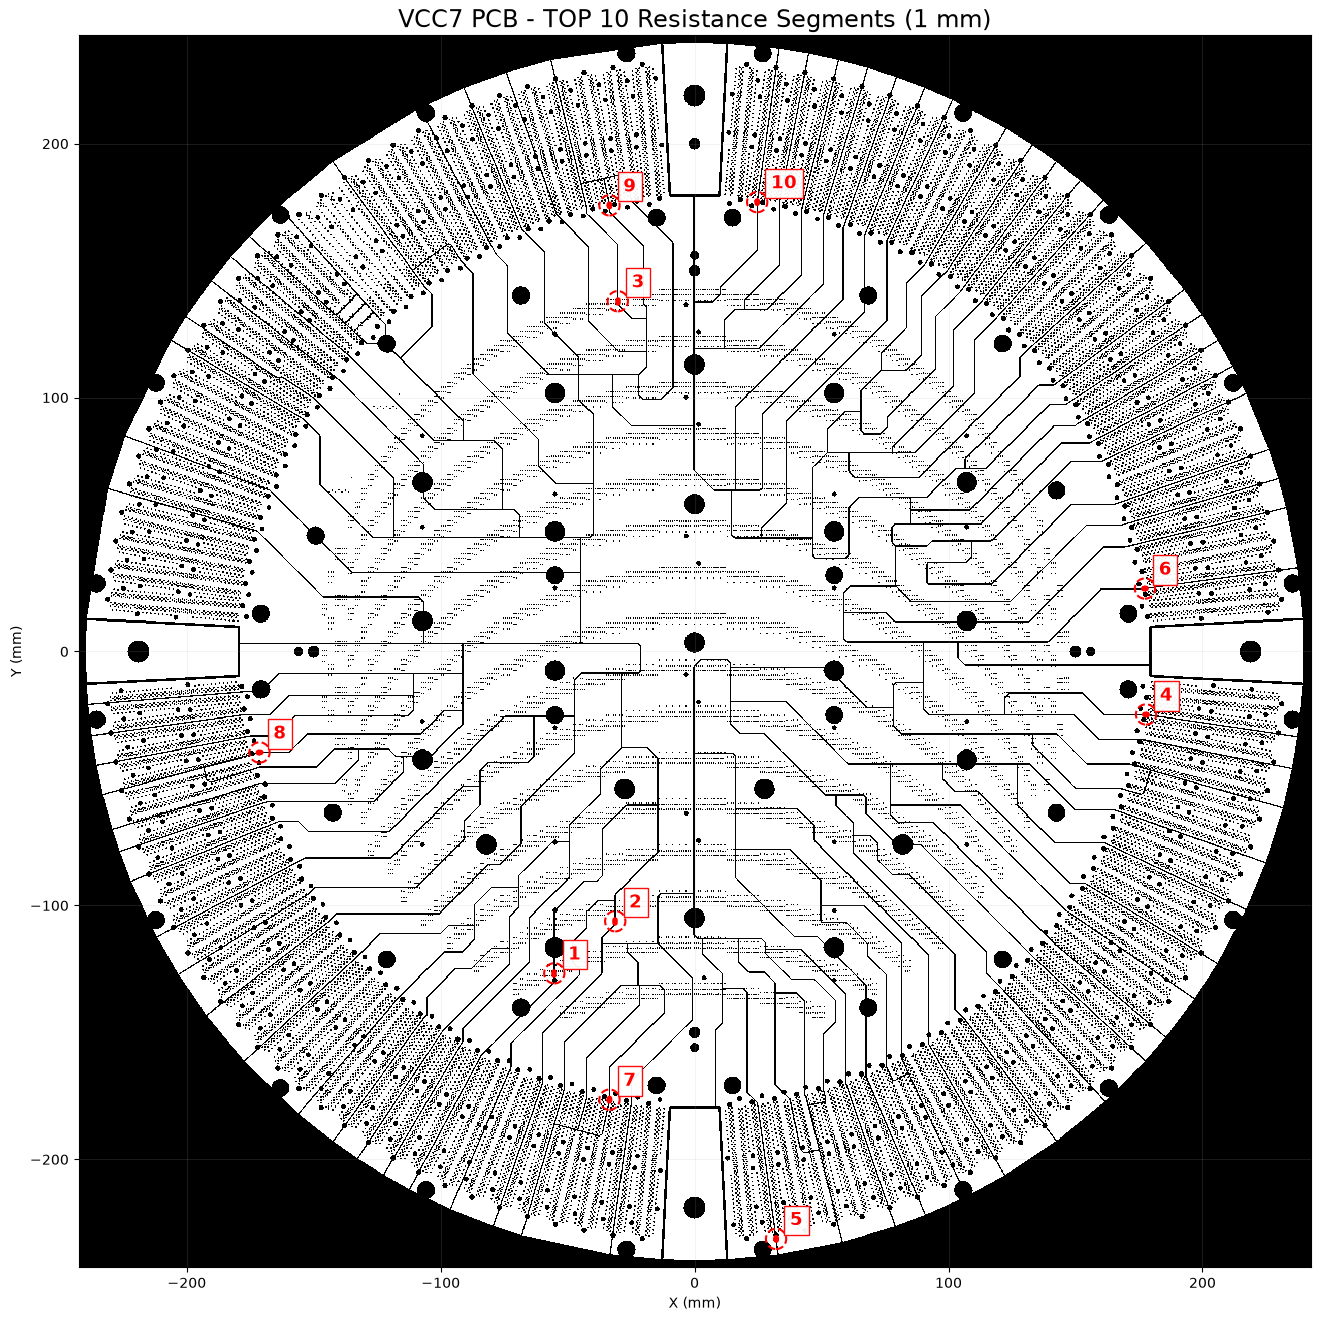

=== TOP 10 SEGMENT COORDINATES ===
Rank  1 | Start=(-55.2600, -127.2400) | End=(-55.2600, -126.2400) | Score=2.0833
Rank  2 | Start=(-31.2600, -105.7400) | End=(-31.2600, -106.7400) | Score=2.0833
Rank  3 | Start=(-30.2600, 137.4400) | End=(-30.2600, 138.4400) | Score=2.0833
Rank  4 | Start=(178.2551, -24.8600) | End=(177.2966, -24.7600) | Score=2.0382
Rank  5 | Start=(32.1507, -231.8176) | End=(32.0400, -230.8634) | Score=2.0199
Rank  6 | Start=(177.8259, 24.8507) | End=(176.8673, 24.7507) | Score=2.0139
Rank  7 | Start=(-33.5000, -176.0014) | End=(-33.6000, -176.9600) | Score=2.0132
Rank  8 | Start=(-170.8541, -39.7459) | End=(-171.8127, -39.8459) | Score=2.0106
Rank  9 | Start=(-33.5000, 175.2014) | End=(-33.5907, 176.1638) | Score=2.0089
Rank 10 | Start=(24.7000, 177.4483) | End=(24.6200, 176.4814) | Score=1.9955

Saved: VCC7_FINAL_TOP10_SEGMENTS.png


In [87]:
# ============================================================
# VCC7 FINAL TOP 10 - 1 mm LINE SEGMENT VISUALIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# 최종 결과 데이터
df_plot = df_final_result.copy()

old_grid, old_tile, old_halo = GRID_MM, TILE_MM, HALO_MM

VIEW_GRID = 0.2
VIEW_TILE = 20.0

fig, ax = plt.subplots(figsize=(16, 16))

# ------------------------------------------------------------
# 1. 전체 PCB 구리 패턴 표시
# ------------------------------------------------------------

try:
    GRID_MM = VIEW_GRID
    TILE_MM = VIEW_TILE
    HALO_MM = 2.0

    for x0 in np.arange(xmin, xmax, VIEW_TILE):
        for y0 in np.arange(ymin, ymax, VIEW_TILE):

            mask, xs, ys = rasterize_tile(x0, y0)

            ax.imshow(
                mask,
                origin="lower",
                extent=[
                    xs[0] - GRID_MM / 2,
                    xs[-1] + GRID_MM / 2,
                    ys[0] - GRID_MM / 2,
                    ys[-1] + GRID_MM / 2
                ],
                cmap="Greys",
                vmin=0,
                vmax=1,
                interpolation="nearest",
                zorder=1
            )

finally:
    GRID_MM, TILE_MM, HALO_MM = old_grid, old_tile, old_halo

# ------------------------------------------------------------
# 2. TOP 10 분석 경로를 빨간 선분으로 표시
# ------------------------------------------------------------

for row in df_plot.itertuples():

    path = np.asarray(row.path_coords)

    # 실제 분석한 1 mm 경로
    ax.plot(
        path[:, 0],
        path[:, 1],
        color="red",
        linewidth=4,
        solid_capstyle="round",
        zorder=10
    )

    # 전체 PCB에서 찾기 위한 위치 표시
    ax.add_patch(
        Circle(
            (row.x_mm, row.y_mm),
            radius=4,
            fill=False,
            edgecolor="red",
            linewidth=1.5,
            linestyle="--",
            zorder=9
        )
    )

    # 순위 번호
    ax.annotate(
        f"{row.rank}",
        (row.x_mm, row.y_mm),
        xytext=(10, 10),
        textcoords="offset points",
        fontsize=13,
        color="red",
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            edgecolor="red",
            alpha=0.95
        ),
        zorder=11
    )

# ------------------------------------------------------------
# 3. 전체 PCB 표시 설정
# ------------------------------------------------------------

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")

ax.set_title(
    "VCC7 PCB - TOP 10 Resistance Segments (1 mm)",
    fontsize=17
)

ax.grid(alpha=0.15)

plt.savefig(
    "VCC7_FINAL_TOP10_SEGMENTS.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. 선분 좌표 출력
# ------------------------------------------------------------

print("=== TOP 10 SEGMENT COORDINATES ===")

for row in df_plot.itertuples():

    path = np.asarray(row.path_coords)

    start = path[0]
    end = path[-1]

    print(
        f"Rank {row.rank:2d} | "
        f"Start=({start[0]:.4f}, {start[1]:.4f}) | "
        f"End=({end[0]:.4f}, {end[1]:.4f}) | "
        f"Score={row.refined_score:.4f}"
    )

print("\nSaved: VCC7_FINAL_TOP10_SEGMENTS.png")

VCC7 FINAL RESISTANCE TOP 10
Corners Excluded / Spatially Diverse


,rank,center_x_mm,center_y_mm,refined_score,min_width_mm,effective_width_mm
0,1,-55.2600,-126.7400,2.0833,0.4800,0.4800
1,2,-31.2600,-106.2400,2.0833,0.4800,0.4800
2,3,-30.2600,137.9400,2.0833,0.4800,0.4800
3,4,177.7800,-24.8000,2.0382,0.4800,0.4906
4,5,32.0800,-231.3469,2.0199,0.4800,0.4951
5,6,177.3507,24.7907,2.0139,0.4800,0.4965
6,7,-33.5200,-176.4931,2.0132,0.4472,0.4967
7,8,-171.3459,-39.7659,2.0106,0.4400,0.4974
8,9,-33.5200,175.6931,2.0089,0.4472,0.4978
9,10,24.6400,176.9731,1.9955,0.4800,0.5011



Rendering full PCB...


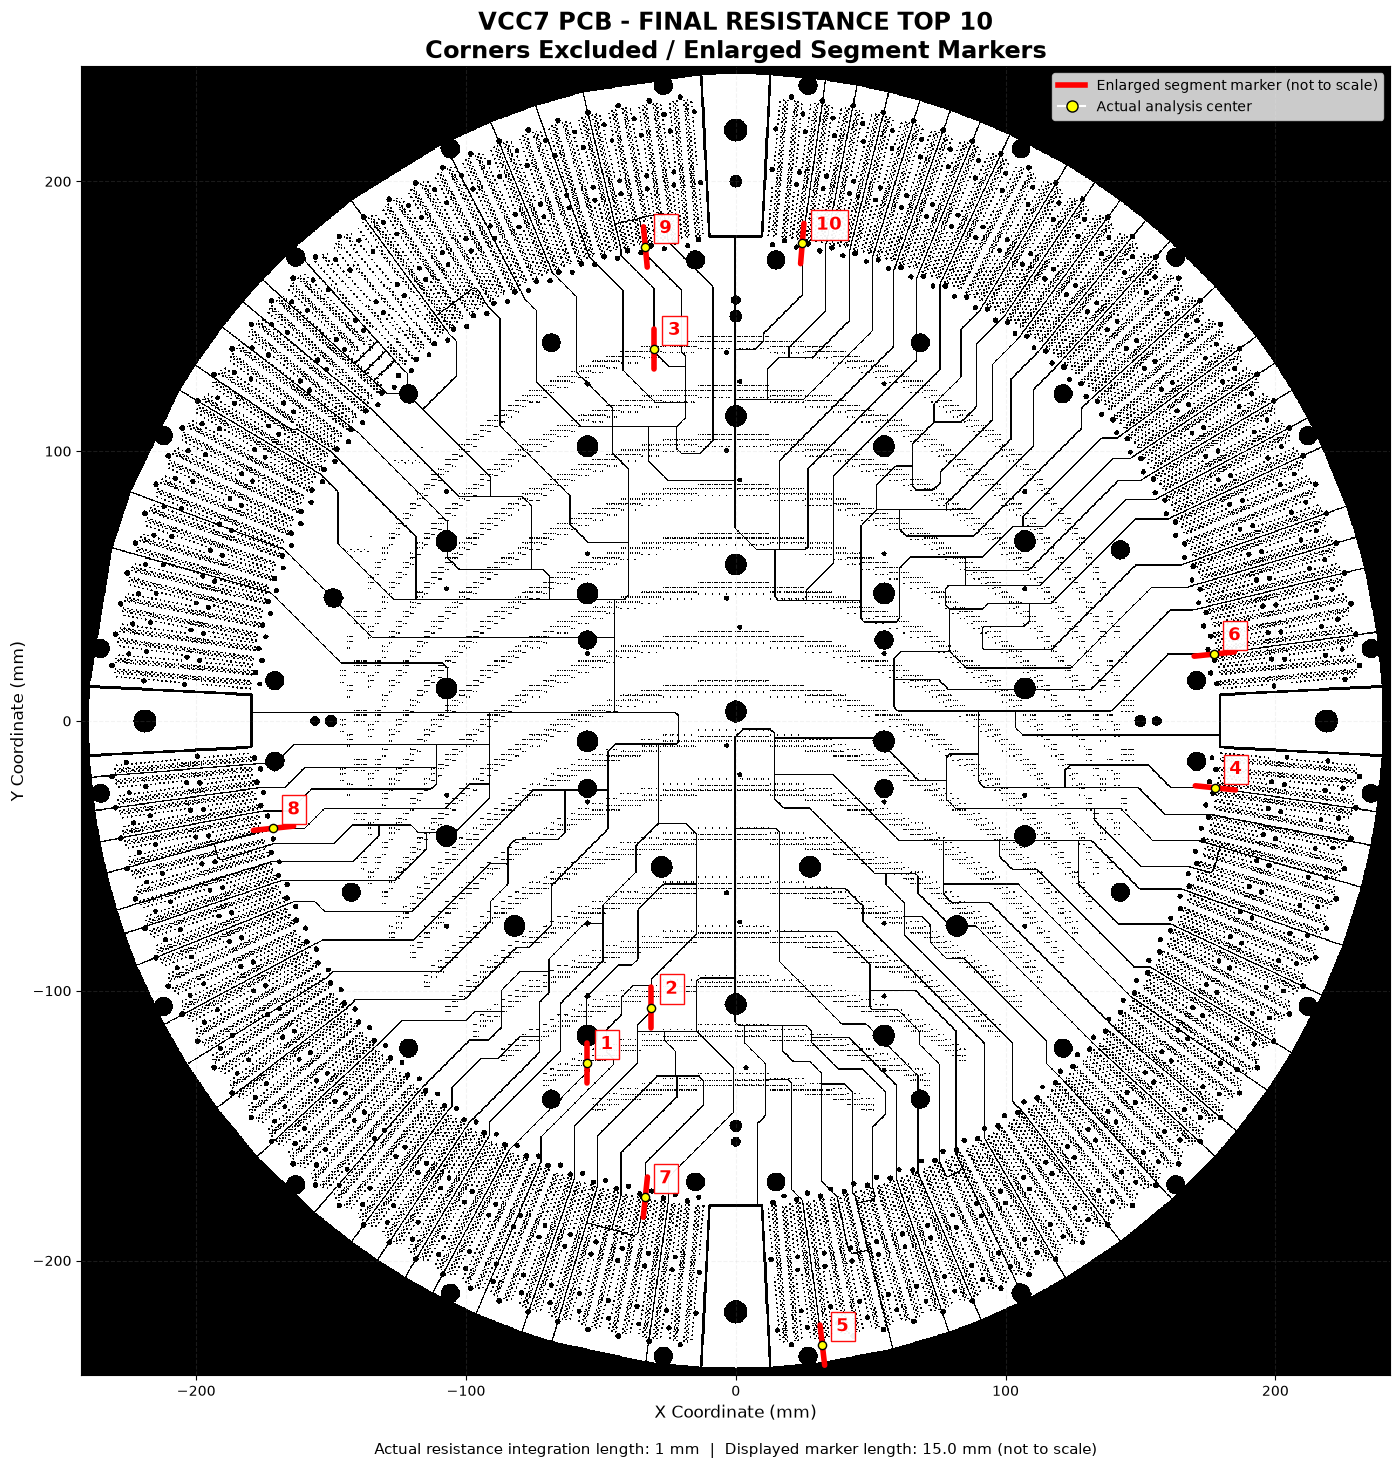


Rendering detailed resistance segments...


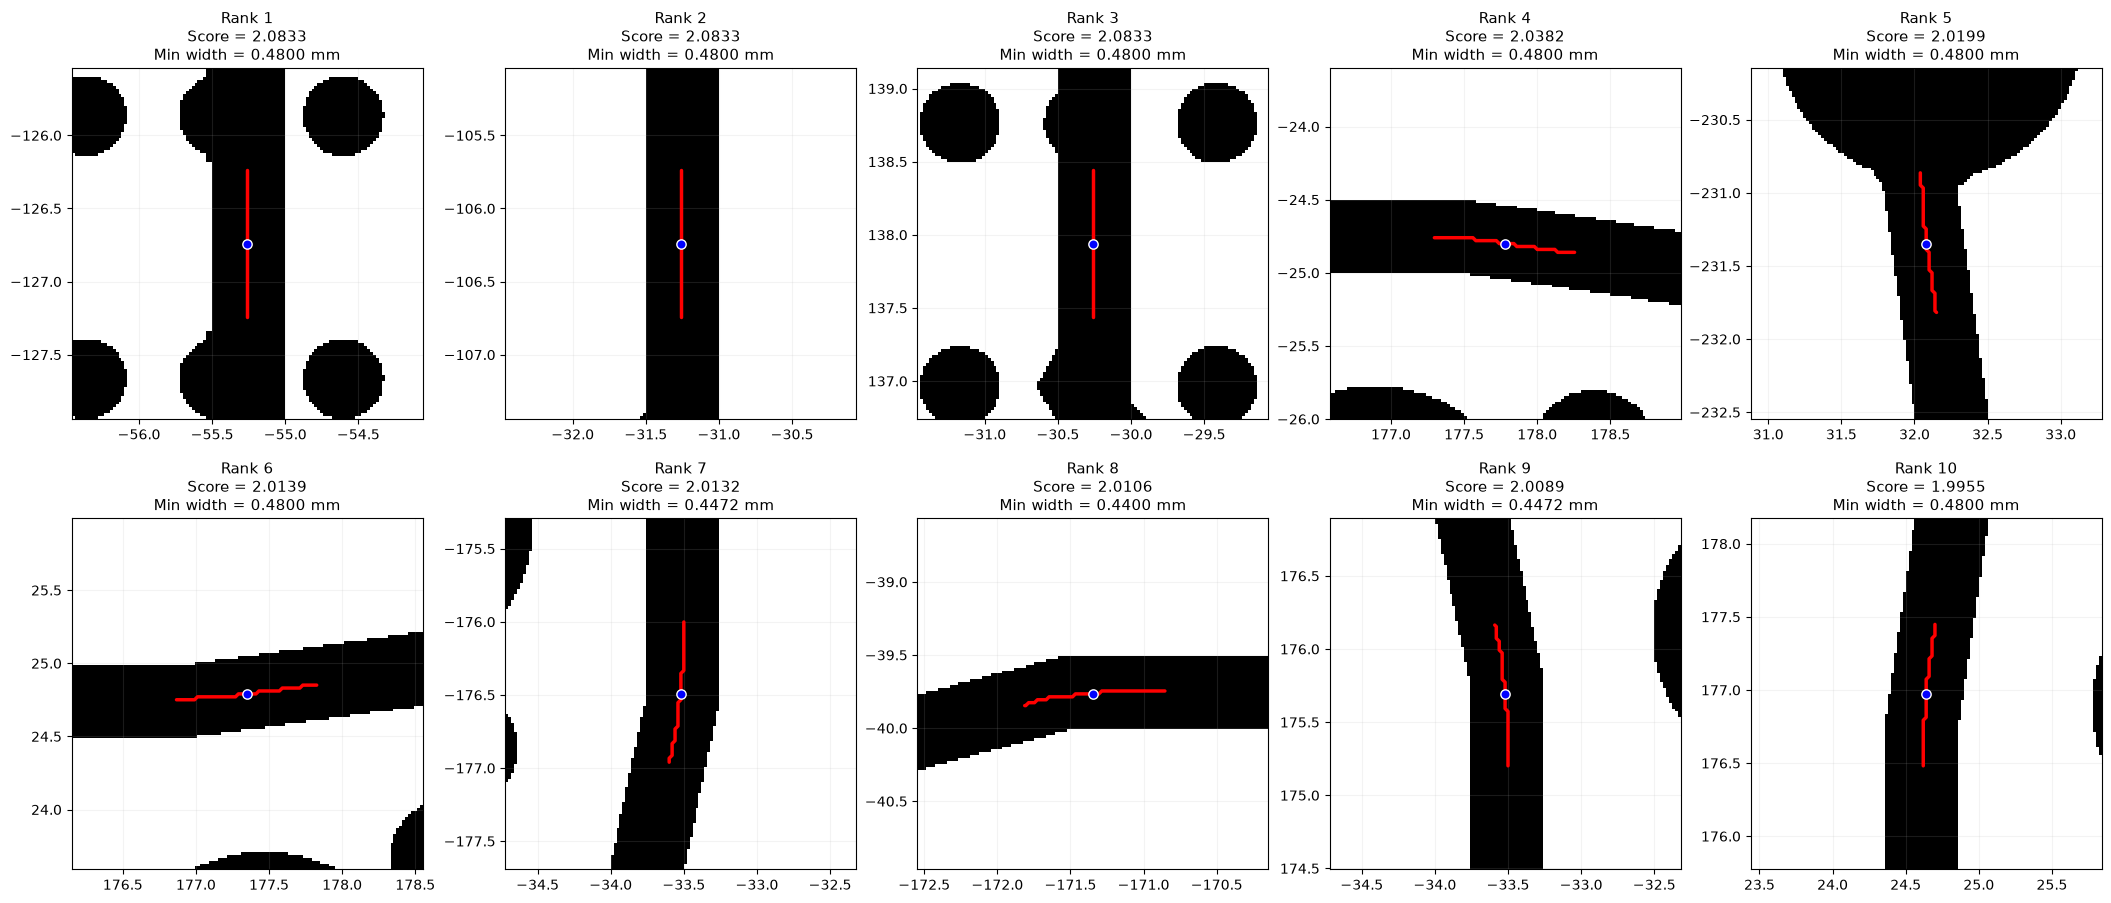

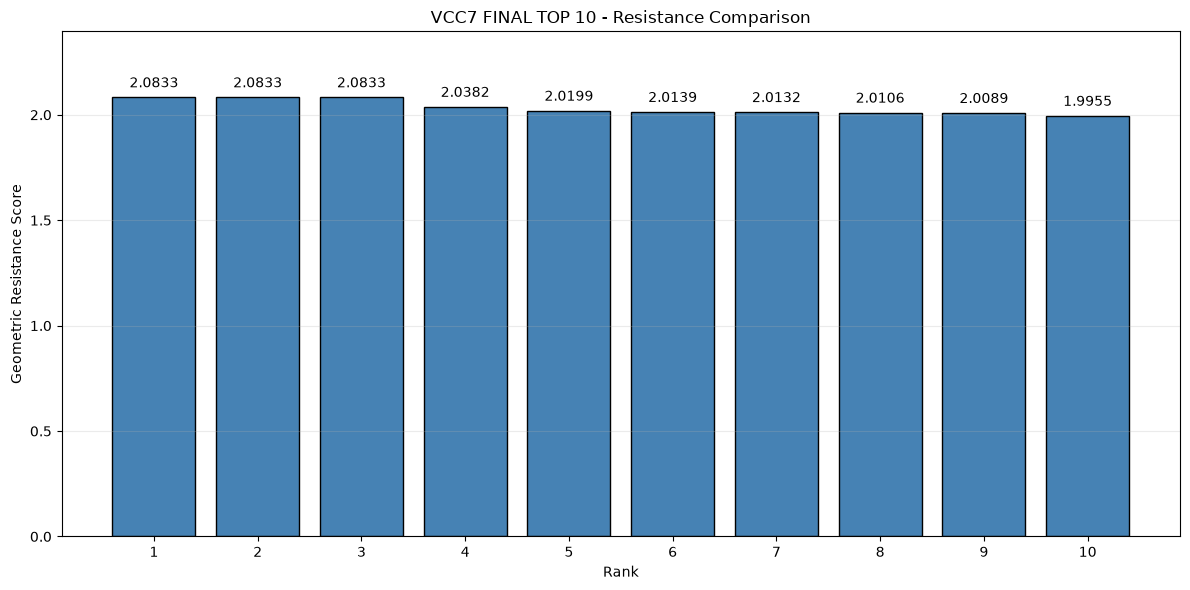


FINAL ANALYSIS RESULT
Rank 1 center: (-55.2600, -126.7400) mm
Resistance score: 2.0833
Minimum width: 0.4800 mm
Effective width: 0.4800 mm

Saved files:
1. VCC7_FINAL_TOP10_ENLARGED_SEGMENTS.png
2. VCC7_FINAL_TOP10_ACTUAL_PATHS.png
3. VCC7_FINAL_TOP10_RESISTANCE_GRAPH.png
4. VCC7_FINAL_TOP10_RESULT.csv
5. VCC7_FINAL_TOP10_SEGMENT_COORDINATES.csv

Visualization complete.


In [88]:
# ============================================================
# VCC7 FINAL TOP 10 VISUALIZATION
#
# 1. 최종 결과표
# 2. 전체 PCB 구리 패턴
# 3. 확대된 TOP 10 빨간 선분
# 4. 실제 1 mm 경로 상세 이미지
# 5. 저항 점수 비교 그래프
# 6. CSV 및 PNG 저장
#
# 기존 Notebook 변수:
# df_diverse_top10
# rasterize_tile()
# GRID_MM, TILE_MM, HALO_MM
# xmin, xmax, ymin, ymax
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.lines import Line2D


# ============================================================
# 1. 사용자 설정
# ============================================================

# 시각화용 선분 길이
# 실제 분석 구간은 1 mm이며, 이 값은 표시 길이에만 적용
DISPLAY_LENGTH_MM = 15.0

# 빨간 선분 두께
DISPLAY_LINE_WIDTH = 4.0

# 전체 PCB 렌더링 해상도
VIEW_GRID_MM = 0.2

# 전체 PCB 렌더링 타일 크기
VIEW_TILE_MM = 20.0

# 개별 상세 이미지 해상도
DETAIL_GRID_MM = 0.02

# 개별 상세 이미지 범위
DETAIL_VIEW_MM = 1.2

# 출력 이미지 해상도
OUTPUT_DPI = 300


# ============================================================
# 2. 기존 변수 확인
# ============================================================

required_vars = [
    "df_diverse_top10",
    "rasterize_tile",
    "GRID_MM",
    "TILE_MM",
    "HALO_MM",
    "xmin",
    "xmax",
    "ymin",
    "ymax"
]

missing = [
    name for name in required_vars
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "다음 변수가 없습니다: "
        + ", ".join(missing)
        + "\n기존 VCC7 분석 셀을 먼저 실행하세요."
    )


# ============================================================
# 3. 최종 TOP 10 데이터 준비
# ============================================================

df_final_result = (
    df_diverse_top10
    .sort_values(
        "refined_score",
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)

df_final_result["rank"] = np.arange(
    1,
    len(df_final_result) + 1
)

# ------------------------------------------------------------
# 선분 시작점과 끝점 계산
# ------------------------------------------------------------

segment_records = []

for row in df_final_result.itertuples():

    path = np.asarray(
        row.path_coords,
        dtype=float
    )

    if path.ndim != 2 or path.shape[1] != 2:
        raise ValueError(
            f"Rank {row.rank}: path_coords 형식 오류"
        )

    if len(path) < 2:
        raise ValueError(
            f"Rank {row.rank}: 경로 좌표 부족"
        )

    # 실제 분석 경로 시작점과 끝점
    actual_start = path[0]
    actual_end = path[-1]

    # 실제 경로의 대표 방향
    direction = actual_end - actual_start

    norm = np.linalg.norm(direction)

    if norm < 1e-9:
        raise ValueError(
            f"Rank {row.rank}: 경로 방향 계산 불가"
        )

    direction = direction / norm

    # 기존 분석 중심 좌표
    center = np.array([
        float(row.x_mm),
        float(row.y_mm)
    ])

    # 확대 표시용 선분
    display_start = (
        center
        - direction * DISPLAY_LENGTH_MM / 2
    )

    display_end = (
        center
        + direction * DISPLAY_LENGTH_MM / 2
    )

    segment_records.append({
        "rank": int(row.rank),

        "center_x_mm": center[0],
        "center_y_mm": center[1],

        "actual_start_x_mm": actual_start[0],
        "actual_start_y_mm": actual_start[1],

        "actual_end_x_mm": actual_end[0],
        "actual_end_y_mm": actual_end[1],

        "display_start_x_mm": display_start[0],
        "display_start_y_mm": display_start[1],

        "display_end_x_mm": display_end[0],
        "display_end_y_mm": display_end[1],

        "refined_score": float(row.refined_score),
        "min_width_mm": float(row.min_width_mm),
        "effective_width_mm": float(
            row.effective_width_mm
        )
    })

df_segments = pd.DataFrame(segment_records)


# ============================================================
# 4. 최종 결과표 출력
# ============================================================

print("=" * 75)
print("VCC7 FINAL RESISTANCE TOP 10")
print("Corners Excluded / Spatially Diverse")
print("=" * 75)

display(
    df_segments[
        [
            "rank",
            "center_x_mm",
            "center_y_mm",
            "refined_score",
            "min_width_mm",
            "effective_width_mm"
        ]
    ].round(4)
)


# ============================================================
# 5. Raster 설정 저장
# ============================================================

old_grid = GRID_MM
old_tile = TILE_MM
old_halo = HALO_MM


# ============================================================
# 6. 전체 PCB 패턴 + 확대 선분 표시
# ============================================================

print("\nRendering full PCB...")

fig, ax = plt.subplots(
    figsize=(17, 17)
)

try:

    GRID_MM = VIEW_GRID_MM
    TILE_MM = VIEW_TILE_MM
    HALO_MM = 2.0

    # 전체 PCB를 타일 단위로 표시
    for x0 in np.arange(
        xmin,
        xmax,
        VIEW_TILE_MM
    ):

        for y0 in np.arange(
            ymin,
            ymax,
            VIEW_TILE_MM
        ):

            mask, xs, ys = rasterize_tile(
                x0,
                y0
            )

            ax.imshow(
                mask,
                origin="lower",
                extent=[
                    xs[0] - GRID_MM / 2,
                    xs[-1] + GRID_MM / 2,
                    ys[0] - GRID_MM / 2,
                    ys[-1] + GRID_MM / 2
                ],
                cmap="Greys",
                vmin=0,
                vmax=1,
                interpolation="nearest",
                zorder=1
            )

finally:

    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo


# ------------------------------------------------------------
# 확대 선분 표시
# ------------------------------------------------------------

for row in df_segments.itertuples():

    # 시각화용 15 mm 선분
    ax.plot(
        [
            row.display_start_x_mm,
            row.display_end_x_mm
        ],
        [
            row.display_start_y_mm,
            row.display_end_y_mm
        ],
        color="red",
        linewidth=DISPLAY_LINE_WIDTH,
        solid_capstyle="round",
        zorder=10
    )

    # 실제 분석 중심점
    ax.scatter(
        row.center_x_mm,
        row.center_y_mm,
        color="yellow",
        edgecolor="black",
        s=35,
        zorder=11
    )

    # 순위 번호
    ax.annotate(
        str(row.rank),
        (
            row.center_x_mm,
            row.center_y_mm
        ),
        xytext=(10, 10),
        textcoords="offset points",
        fontsize=13,
        fontweight="bold",
        color="red",
        bbox=dict(
            facecolor="white",
            edgecolor="red",
            alpha=0.95
        ),
        zorder=12
    )


# ------------------------------------------------------------
# 전체 PCB 그래프 설정
# ------------------------------------------------------------

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_aspect("equal")

ax.set_xlabel(
    "X Coordinate (mm)",
    fontsize=12
)

ax.set_ylabel(
    "Y Coordinate (mm)",
    fontsize=12
)

ax.set_title(
    "VCC7 PCB - FINAL RESISTANCE TOP 10\n"
    "Corners Excluded / Enlarged Segment Markers",
    fontsize=17,
    fontweight="bold"
)

ax.grid(
    alpha=0.15,
    linestyle="--"
)

legend_elements = [
    Line2D(
        [0], [0],
        color="red",
        linewidth=4,
        label="Enlarged segment marker (not to scale)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="yellow",
        markeredgecolor="black",
        markersize=8,
        label="Actual analysis center"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=10
)

ax.text(
    0.5,
    -0.06,
    (
        "Actual resistance integration length: 1 mm  |  "
        f"Displayed marker length: {DISPLAY_LENGTH_MM:.1f} mm "
        "(not to scale)"
    ),
    transform=ax.transAxes,
    ha="center",
    fontsize=11
)

plt.savefig(
    "VCC7_FINAL_TOP10_ENLARGED_SEGMENTS.png",
    dpi=OUTPUT_DPI,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. TOP 10 실제 분석 경로 상세 이미지
# ============================================================

print("\nRendering detailed resistance segments...")

fig, axes = plt.subplots(
    2,
    5,
    figsize=(21, 9),
    constrained_layout=True
)

try:

    GRID_MM = DETAIL_GRID_MM
    TILE_MM = 3.0
    HALO_MM = 1.5

    for ax, row in zip(
        axes.flat,
        df_final_result.itertuples()
    ):

        x = float(row.x_mm)
        y = float(row.y_mm)

        mask, xs, ys = rasterize_tile(
            x - TILE_MM / 2,
            y - TILE_MM / 2
        )

        # 실제 구리 패턴
        ax.imshow(
            mask,
            origin="lower",
            extent=[
                xs[0] - GRID_MM / 2,
                xs[-1] + GRID_MM / 2,
                ys[0] - GRID_MM / 2,
                ys[-1] + GRID_MM / 2
            ],
            cmap="Greys",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        # 실제 저항 계산 경로
        path = np.asarray(
            row.path_coords,
            dtype=float
        )

        ax.plot(
            path[:, 0],
            path[:, 1],
            color="red",
            linewidth=2.5,
            solid_capstyle="round",
            zorder=10
        )

        # 실제 분석 중심점
        ax.scatter(
            [x],
            [y],
            color="blue",
            edgecolor="white",
            s=45,
            zorder=11
        )

        ax.set_xlim(
            x - DETAIL_VIEW_MM,
            x + DETAIL_VIEW_MM
        )

        ax.set_ylim(
            y - DETAIL_VIEW_MM,
            y + DETAIL_VIEW_MM
        )

        ax.set_aspect("equal")

        ax.set_title(
            f"Rank {row.rank}\n"
            f"Score = {row.refined_score:.4f}\n"
            f"Min width = {row.min_width_mm:.4f} mm",
            fontsize=11
        )

        ax.grid(alpha=0.15)

finally:

    GRID_MM = old_grid
    TILE_MM = old_tile
    HALO_MM = old_halo

# 사용하지 않는 축 숨기기
for ax in axes.flat[len(df_final_result):]:
    ax.axis("off")

plt.savefig(
    "VCC7_FINAL_TOP10_ACTUAL_PATHS.png",
    dpi=OUTPUT_DPI,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. TOP 10 저항 점수 비교
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 6)
)

ranks = df_segments["rank"].astype(str)
scores = df_segments["refined_score"]

bars = ax.bar(
    ranks,
    scores,
    color="steelblue",
    edgecolor="black"
)

for bar, score in zip(bars, scores):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(scores) * 0.015,
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_xlabel("Rank")
ax.set_ylabel("Geometric Resistance Score")
ax.set_title(
    "VCC7 FINAL TOP 10 - Resistance Comparison"
)

ax.set_ylim(
    0,
    max(scores) * 1.15
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "VCC7_FINAL_TOP10_RESISTANCE_GRAPH.png",
    dpi=OUTPUT_DPI,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. CSV 저장
# ============================================================

# 최종 TOP 10 요약
df_final_result.drop(
    columns=["path_coords", "Index"],
    errors="ignore"
).to_csv(
    "VCC7_FINAL_TOP10_RESULT.csv",
    index=False,
    encoding="utf-8-sig"
)

# 실제 경로 및 확대 선분 좌표
df_segments.to_csv(
    "VCC7_FINAL_TOP10_SEGMENT_COORDINATES.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 10. 최종 결과 요약
# ============================================================

print("\n" + "=" * 75)
print("FINAL ANALYSIS RESULT")
print("=" * 75)

best = df_segments.iloc[0]

print(
    f"Rank 1 center: "
    f"({best.center_x_mm:.4f}, "
    f"{best.center_y_mm:.4f}) mm"
)

print(
    f"Resistance score: "
    f"{best.refined_score:.4f}"
)

print(
    f"Minimum width: "
    f"{best.min_width_mm:.4f} mm"
)

print(
    f"Effective width: "
    f"{best.effective_width_mm:.4f} mm"
)

print("\nSaved files:")
print("1. VCC7_FINAL_TOP10_ENLARGED_SEGMENTS.png")
print("2. VCC7_FINAL_TOP10_ACTUAL_PATHS.png")
print("3. VCC7_FINAL_TOP10_RESISTANCE_GRAPH.png")
print("4. VCC7_FINAL_TOP10_RESULT.csv")
print("5. VCC7_FINAL_TOP10_SEGMENT_COORDINATES.csv")

print("\nVisualization complete.")